# F1 Podium Prediction — Milestone 1

**Task.** For every driver in every race, predict whether the driver finishes on the podium (`positionOrder` ≤ 3), using only what is known after qualifying and before the race starts. The race's own results, points, status, laps and pit stops, and the standings stored for that race, are only known after the start, so they are never used as features (that would be data leakage).

**Data.** Kaggle "Formula 1 World Championship (1950–2024)" (Ergast): 14 linked CSV tables. On Kaggle, attach the dataset and Run All; cell 2 finds it under `/kaggle/input`. Locally, unzip `f1_dataset.zip` into `f1_dataset/` next to this notebook and Run All. Libraries: pandas, numpy, matplotlib, seaborn, scipy, statsmodels, scikit-learn, PyTorch, shap and lime (Section 9 installs shap and lime if they are missing).

**Sections.**

| Section | Objective | Content |
|---|---|---|
| 1. Initial EDA & audit | 1 | Load the 14 tables, missing values, first charts |
| 2. Cleaning pipeline | 1 | Placeholders, data types, keys, duplicates, before vs after |
| 3. Extra anomaly checks | 1 | Impossible lap times and dates, summary of data issues |
| 4. Master merge | 1 → 2 | One joined table, the race-start rule, distributions |
| 5. Data-engineering questions | 2 | Q1 front-row conversion, Q2 home advantage, Q3 mechanical retirements |
| 6. Features and split | 3 | Modelling table, season split, 19 features with evidence, preparation, experiments, limitations |
| 7. Predictive modelling | 4 | Baseline, three statistical models, a shallow neural network, comparison on training, validation and test |
| 8. Feature-group ablation | 5 | Retrain without each feature group and with each group alone |
| 9. Explainability (XAI) | 6 | Permutation importance, SHAP, one prediction explained with SHAP and LIME |
| 10. Inference function | deliverable 7 | Podium chances for a race from pre-race information, on complete and partially-missing records |
| Summary | | The main results in one place |

**How to read it.** Every analysis has a **[GOAL]**, a **[LOGIC]** and an **[OBSERVATION]**, and every number in the text is printed or plotted by the notebook itself.

---

## Section 1: Initial EDA & Audit (Objective 1)

**[GOAL]:** Perform a baseline audit of the raw datasets to identify missing values, sentinel strings (`\N`), and data type inconsistencies before any cleaning takes place.

**[LOGIC]:** By automating a "Health Report" for all files, we ensure that no dataset is overlooked and we create a quantifiable baseline to measure the impact of our cleaning pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Configuration
KAGGLE_INPUT = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
LOCAL_DATA_PATH = Path("f1_dataset")  # extracted f1_dataset.zip, next to this notebook
CSV_FILES = [
    "circuits.csv", "constructor_results.csv", "constructors.csv",
    "constructor_standings.csv", "drivers.csv", "driver_standings.csv",
    "lap_times.csv", "pit_stops.csv", "qualifying.csv", "races.csv",
    "results.csv", "seasons.csv", "sprint_results.csv", "status.csv"
]
# On Kaggle the dataset is mounted somewhere under /kaggle/input: use the folder that holds all 14 CSVs
found = [p.parent for p in sorted(KAGGLE_INPUT.rglob("races.csv"))
         if all((p.parent / f).exists() for f in CSV_FILES)] if KAGGLE_INPUT.exists() else []
DATA_PATH = found[0] if found else LOCAL_DATA_PATH

# Load all CSVs into a dictionary
dfs_raw = {}
for file in CSV_FILES:
    df_name = file.replace(".csv", "")
    dfs_raw[df_name] = pd.read_csv(os.path.join(DATA_PATH, file))

print(f"Successfully loaded {len(dfs_raw)} datasets from {DATA_PATH}.")

Successfully loaded 14 datasets from /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020.


In [2]:
def generate_health_report(dfs):
    """Generate a comprehensive health report for all datasets."""
    report_data = []
    for name, df in dfs.items():
        sentinel_count = (df == '\\N').sum().sum()
        # Per-column null distribution
        null_dist = df.isnull().sum()
        report_data.append({
            "Dataset": name,
            "Rows": df.shape[0],
            "Cols": df.shape[1],
            "Nulls": int(df.isnull().sum().sum()),
            "Sentinels (\\N)": int(sentinel_count),
            "Null_Distribution": null_dist.to_dict()
        })
    
    return pd.DataFrame(report_data)

# Generate and display the report
health_df = generate_health_report(dfs_raw)
total_sentinels = health_df['Sentinels (\\N)'].sum()
print(f"Total \\N sentinels across all tables: {total_sentinels:,}")
health_df[['Dataset', 'Rows', 'Cols', 'Nulls', 'Sentinels (\\N)']]

Total \N sentinels across all tables: 160,076


,Dataset,Rows,Cols,Nulls,Sentinels (\N)
0,circuits,77,9,0,0
1,constructor_results,12625,5,0,12608
2,constructors,212,5,0,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,0,1559
5,driver_standings,34863,7,0,0
6,lap_times,589081,6,0,0
7,pit_stops,11371,7,0,0
8,qualifying,10494,9,68,11600
9,races,1125,18,0,11349


**[OBSERVATION]:** The health report shows that missing values are written as the literal string `\N` rather than left empty: **160,076** sentinels in total. Most are in `results` (122,887), `constructor_results` (12,608), `qualifying` (11,600) and `races` (11,349), with smaller counts in `drivers` (1,559) and `sprint_results` (73). The other eight tables, including `pit_stops`, have none. `qualifying` also has 68 genuinely empty cells (the `Nulls` column), a second form of missing value. Because `\N` is read as text, affected columns load as text instead of numbers or dates (see the column-type comparison in 2.4), so the sentinels must be replaced before any numeric analysis.

results - missing % per column: milliseconds 71.3%, time 71.3%, fastestLapTime 69.2%, fastestLap 69.2%, fastestLapSpeed 69.2%, rank 68.2%, position 40.9%, number 0.0%
qualifying - missing % per column: q3 65.4%, q2 44.3%, q1 1.5%


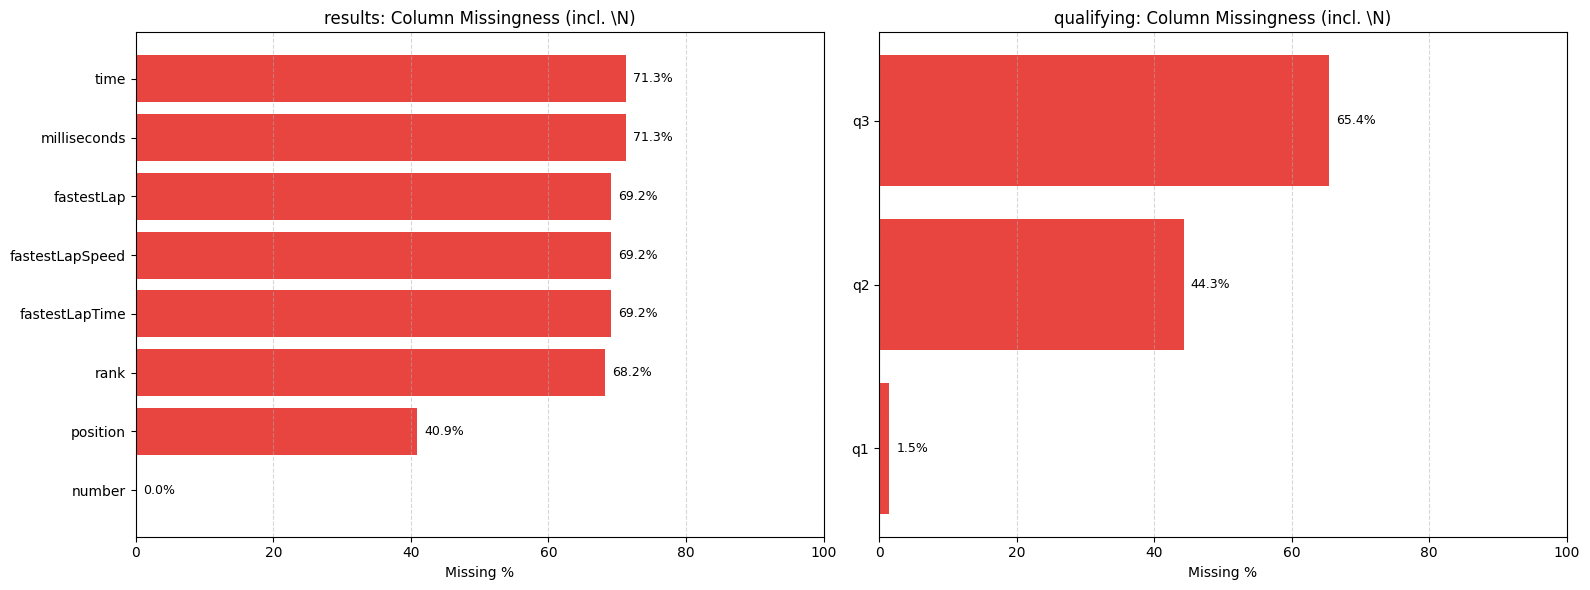

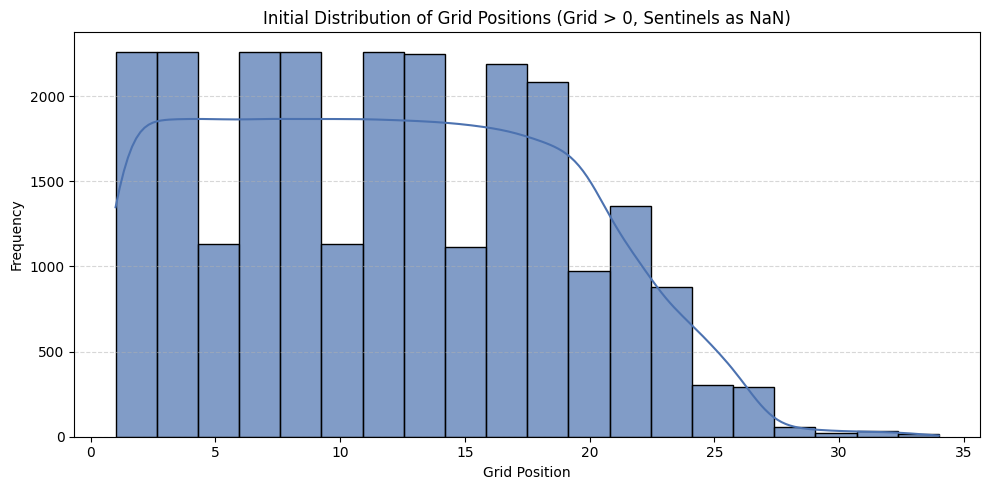

Grid = 0: 1638 rows
Grid NaN: 0 rows

Grid = 0 rows by status (top 6):
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Never started (did not qualify, did not pre-qualify, withdrew): 1508 (92.1%)
Grid = 0 rows by decade: {1950: 68, 1960: 198, 1970: 351, 1980: 571, 1990: 357, 2000: 8, 2010: 28, 2020: 57}
2003-2024: 86 grid = 0 rows, most common statuses: {'+1 Lap': 27, 'Finished': 22, '+2 Laps': 7}
Podium finishes from grid = 0 (all years): 0


In [3]:
# Visualization 1: Missingness Analysis for Key Datasets (Results & Qualifying)
# For large datasets, column-wise missingness percentage bars are more informative than row-wise heatmaps

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (name, df) in enumerate([('results', dfs_raw['results']), ('qualifying', dfs_raw['qualifying'])]):
    ax = axes[idx]
    # Calculate missing percentage per column (including \N sentinels)
    missing_pct = ((df.isnull() | (df == '\\N')).sum() / len(df) * 100).sort_values(ascending=True)
    # Only show columns with >0% missing
    missing_pct = missing_pct[missing_pct > 0]
    print(f"{name} - missing % per column: " + ', '.join(f"{c} {p:.1f}%" for c, p in missing_pct.sort_values(ascending=False).items()))
    if len(missing_pct) > 0:
        bars = ax.barh(range(len(missing_pct)), missing_pct.values, color='#E10600', alpha=0.75)
        ax.set_yticks(range(len(missing_pct)))
        ax.set_yticklabels(missing_pct.index, fontsize=10)
        ax.set_xlabel('Missing %')
        ax.set_title(f'{name}: Column Missingness (incl. \\N)')
        ax.set_xlim(0, 100)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        # Add percentage labels on bars
        for bar, pct in zip(bars, missing_pct.values):
            ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
                    f'{pct:.1f}%', va='center', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'No missing values', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{name}: Column Missingness')

plt.tight_layout()
plt.show()

# Visualization 2: Distribution of Grid Positions (Initial State)
# Exclude grid=0 (no grid slot: non-starters or pit-lane starts) for a cleaner distribution view
grid_data = dfs_raw['results']['grid'].replace('\\N', np.nan).astype(float)
plt.figure(figsize=(10, 5))
sns.histplot(grid_data[grid_data > 0], bins=20, kde=True, color='#4C72B0', alpha=0.7)
plt.title("Initial Distribution of Grid Positions (Grid > 0, Sentinels as NaN)")
plt.xlabel("Grid Position")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Show grid=0 count, and what those entries actually are (their race status)
print(f"Grid = 0: {(grid_data == 0).sum()} rows")
print(f"Grid NaN: {grid_data.isna().sum()} rows")
grid0 = (dfs_raw['results'][grid_data == 0]
         .merge(dfs_raw['status'], on='statusId')
         .merge(dfs_raw['races'][['raceId', 'year']], on='raceId'))
print("\nGrid = 0 rows by status (top 6):")
print(grid0['status'].value_counts().head(6).to_string())
never_started = grid0['status'].isin(['Did not qualify', 'Did not prequalify', 'Withdrew'])
print(f"Never started (did not qualify, did not pre-qualify, withdrew): {never_started.sum()} ({never_started.mean():.1%})")
print(f"Grid = 0 rows by decade: {(grid0['year'] // 10 * 10).value_counts().sort_index().to_dict()}")
modern_grid0 = grid0[grid0['year'] >= 2003]
print(f"2003-2024: {len(modern_grid0)} grid = 0 rows, most common statuses: {modern_grid0['status'].value_counts().head(3).to_dict()}")
print(f"Podium finishes from grid = 0 (all years): {(grid0['positionOrder'] <= 3).sum()}")

**[OBSERVATION]:** Missing data is concentrated in a few columns.
- **`results`:** the timing columns are mostly empty: `time` and `milliseconds` 71.3%, `fastestLapTime`, `fastestLap` and `fastestLapSpeed` 69.2%, and `rank` 68.2%. `position` is empty for 40.9% of rows, i.e. for drivers without an official classification; `positionOrder` still orders every row.
- **`qualifying`:** `q1` is missing for 1.5%, `q2` for 44.3% and `q3` for 65.4%, because not every driver takes part in the later qualifying sessions.

**Grid = 0 (1,638 rows):** these are not unrecorded grids.
- **92.1% (1,508) never started the race:** did not qualify (1,013), did not pre-qualify (331) or withdrew (164).
- **When:** they are most common in the 1970s–1990s (351, 571 and 357 rows per decade), when more cars entered than were allowed to start.
- **Since 2003:** only 86 such rows remain, mostly drivers who started from the pit lane and finished ("+1 Lap" 27, "Finished" 22).
- **No driver has ever reached the podium from grid 0.**

Grid 0 therefore means "no grid slot". Q1 and Q2 count only real grid slots (grid 1 or more); Section 6 keeps the pit-lane starters, places them at the back of the field and marks them with a flag (6.3).

## Section 2: The Cleaning Pipeline (Objective 1)

**[GOAL]:** Turn the raw tables into clean, correctly typed copies while keeping the original data unchanged.

**[LOGIC]:** The raw tables (`dfs_raw`) are never modified; all cleaning happens on copies in `dfs_clean`, so the raw state stays available for the before/after comparison. The steps run in order: 2.1 sentinel replacement and semantic typing → 2.2 primary/foreign key validation → 2.3 duplicate resolution → 2.4 before/after comparison.

In [4]:
# 2.1 Sentinel Replacement and Semantic Typing
# Goal: replace \N sentinels with NaN, convert date strings to datetime objects and lap-time strings (m:ss.ms) to numeric seconds.

def parse_lap_time(time_str):
    """Converts F1 lap time string 'm:ss.ms' or 'mm:ss.ms' to total seconds."""
    if pd.isna(time_str) or time_str == '':
        return np.nan
    try:
        parts = str(time_str).split(':')
        if len(parts) == 2:
            minutes, seconds = parts
            return int(minutes) * 60 + float(seconds)
        elif len(parts) == 3:
            hours, minutes, seconds = parts
            return int(hours) * 3600 + int(minutes) * 60 + float(seconds)
        return float(time_str)
    except (ValueError, AttributeError):
        return np.nan

def parse_clock_time(time_str):
    """Converts clock time string 'HH:MM:SS' to seconds since midnight."""
    if pd.isna(time_str) or time_str == '':
        return np.nan
    try:
        parts = str(time_str).split(':')
        if len(parts) == 3:
            hours, minutes, seconds = parts
            return int(hours) * 3600 + int(minutes) * 60 + float(seconds)
        return np.nan
    except (ValueError, AttributeError):
        return np.nan

# Create a deep copy for cleaning
dfs_clean = {}
for name, df in dfs_raw.items():
    dfs_clean[name] = df.copy()

# 1. Replace all \N sentinels with NaN across all dataframes
for name, df in dfs_clean.items():
    dfs_clean[name] = df.replace('\\N', np.nan)

# 2. Convert DATE columns to datetime64
date_columns = {
    'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'],
    'drivers': ['dob'],
    'constructor_results': [],
    'constructors': [],
    'constructor_standings': [],
    'driver_standings': [],
    'lap_times': [],
    'pit_stops': [],
    'qualifying': [],
    'results': [],
    'seasons': [],
    'sprint_results': [],
    'status': [],
}

for table, cols in date_columns.items():
    if table in dfs_clean:
        for col in cols:
            if col in dfs_clean[table].columns:
                dfs_clean[table][col] = pd.to_datetime(dfs_clean[table][col], errors='coerce')

# 3. Convert LAP TIME columns (m:ss.ms format) to numeric seconds
qualifying_time_cols = ['q1', 'q2', 'q3']
for col in qualifying_time_cols:
    if col in dfs_clean['qualifying'].columns:
        dfs_clean['qualifying'][col] = dfs_clean['qualifying'][col].apply(parse_lap_time)

if 'fastestLapTime' in dfs_clean['results'].columns:
    dfs_clean['results']['fastestLapTime'] = dfs_clean['results']['fastestLapTime'].apply(parse_lap_time)

if 'time' in dfs_clean['lap_times'].columns:
    dfs_clean['lap_times']['time'] = dfs_clean['lap_times']['time'].apply(parse_lap_time)

if 'duration' in dfs_clean['pit_stops'].columns:
    dfs_clean['pit_stops']['duration'] = dfs_clean['pit_stops']['duration'].apply(parse_lap_time)

# 4. Convert NUMERIC columns that should be numeric
# results numeric columns
# 'milliseconds' is the race time as a number. 'time' stays text on purpose: it mixes the winner's total time
# ('1:34:50.616') with gaps to the winner ('+5.478'), and the same information is numeric in 'milliseconds'.
results_numeric = ['number', 'grid', 'position', 'positionOrder', 'points', 'laps', 'milliseconds', 'rank', 'fastestLap', 'fastestLapSpeed']
for col in results_numeric:
    if col in dfs_clean['results'].columns:
        dfs_clean['results'][col] = pd.to_numeric(dfs_clean['results'][col], errors='coerce')

# qualifying numeric
for col in ['number', 'position']:
    if col in dfs_clean['qualifying'].columns:
        dfs_clean['qualifying'][col] = pd.to_numeric(dfs_clean['qualifying'][col], errors='coerce')

# lap_times numeric
if 'milliseconds' in dfs_clean['lap_times'].columns:
    dfs_clean['lap_times']['milliseconds'] = pd.to_numeric(dfs_clean['lap_times']['milliseconds'], errors='coerce')
if 'lap' in dfs_clean['lap_times'].columns:
    dfs_clean['lap_times']['lap'] = pd.to_numeric(dfs_clean['lap_times']['lap'], errors='coerce')

# pit_stops numeric
# NOTE: 'time' in pit_stops is a clock time (HH:MM:SS), NOT duration. Parse it as time, not numeric.
pit_numeric = ['stop', 'lap', 'milliseconds']
for col in pit_numeric:
    if col in dfs_clean['pit_stops'].columns:
        dfs_clean['pit_stops'][col] = pd.to_numeric(dfs_clean['pit_stops'][col], errors='coerce')

# Parse pit_stops.time as clock time (HH:MM:SS) to seconds since midnight for potential temporal analysis
if 'time' in dfs_clean['pit_stops'].columns:
    dfs_clean['pit_stops']['time_seconds'] = dfs_clean['pit_stops']['time'].apply(parse_clock_time)
    # Keep original 'time' column as string for reference

# sprint_results: same structure as results
sprint_numeric = ['number', 'grid', 'position', 'positionOrder', 'points', 'laps', 'milliseconds', 'fastestLap']
for col in sprint_numeric:
    if col in dfs_clean['sprint_results'].columns:
        dfs_clean['sprint_results'][col] = pd.to_numeric(dfs_clean['sprint_results'][col], errors='coerce')
dfs_clean['sprint_results']['fastestLapTime'] = dfs_clean['sprint_results']['fastestLapTime'].apply(parse_lap_time)

# races: session start times are clock times ('HH:MM:SS', UTC) -> time-of-day durations
for col in ['time', 'fp1_time', 'fp2_time', 'fp3_time', 'quali_time', 'sprint_time']:
    if col in dfs_clean['races'].columns:
        dfs_clean['races'][col] = pd.to_timedelta(dfs_clean['races'][col], errors='coerce')

# drivers numeric
dfs_clean['drivers']['number'] = pd.to_numeric(dfs_clean['drivers']['number'], errors='coerce')
if 'driverId' in dfs_clean['drivers'].columns:
    dfs_clean['drivers']['driverId'] = pd.to_numeric(dfs_clean['drivers']['driverId'], errors='coerce')

# constructors numeric
if 'constructorId' in dfs_clean['constructors'].columns:
    dfs_clean['constructors']['constructorId'] = pd.to_numeric(dfs_clean['constructors']['constructorId'], errors='coerce')

# circuits numeric
circuit_numeric = ['circuitId', 'lat', 'lng', 'alt']
for col in circuit_numeric:
    if col in dfs_clean['circuits'].columns:
        dfs_clean['circuits'][col] = pd.to_numeric(dfs_clean['circuits'][col], errors='coerce')

# races numeric
races_numeric = ['raceId', 'year', 'round', 'circuitId']
for col in races_numeric:
    if col in dfs_clean['races'].columns:
        dfs_clean['races'][col] = pd.to_numeric(dfs_clean['races'][col], errors='coerce')

print("Semantic typing completed. Examples of converted columns:")
converted = {'races': ['date', 'time'], 'drivers': ['dob'], 'qualifying': ['q1', 'q2', 'q3'],
             'results': ['milliseconds', 'fastestLapTime'], 'sprint_results': ['milliseconds', 'fastestLapTime'],
             'lap_times': ['time'], 'pit_stops': ['duration']}
for table, cols in converted.items():
    print(f"  {table}: " + ', '.join(f"{c} -> {dfs_clean[table][c].dtype}" for c in cols))
unparsed = {c: int(dfs_raw['races'][c].replace('\\N', np.nan).notna().sum() - dfs_clean['races'][c].notna().sum())
            for c in ['time', 'fp1_time', 'quali_time', 'sprint_time']}
print(f"  races clock times that failed to parse: {unparsed}")

Semantic typing completed. Examples of converted columns:
  races: date -> datetime64[ns], time -> timedelta64[ns]
  drivers: dob -> datetime64[ns]
  qualifying: q1 -> float64, q2 -> float64, q3 -> float64
  results: milliseconds -> float64, fastestLapTime -> float64
  sprint_results: milliseconds -> float64, fastestLapTime -> float64
  lap_times: time -> float64
  pit_stops: duration -> float64
  races clock times that failed to parse: {'time': 0, 'fp1_time': 0, 'quali_time': 0, 'sprint_time': 0}


**[OBSERVATION]:** All `\N` sentinels are replaced with `NaN` (the comparison in 2.4 confirms that none remain), and the columns are given proper types. The printed examples show the result:
- **Dates** are `datetime64`: `races.date`, `drivers.dob`.
- **Lap and qualifying times** are numeric seconds: `qualifying.q1`–`q3`, `results.fastestLapTime`, `sprint_results.fastestLapTime`, `lap_times.time`, `pit_stops.duration`.
- **Race times** are numeric milliseconds: `results.milliseconds`, `sprint_results.milliseconds`.
- **Session start times** (`races.time`, `fp1_time`, `quali_time`, ...) are time-of-day durations; none of the four checked (`time`, `fp1_time`, `quali_time`, `sprint_time`) failed to parse.

`results.time` deliberately stays text. It mixes the winner's total time ("1:34:50.616") with gaps to the winner ("+5.478"), and the same information is available as a number in `milliseconds`.

In [5]:
# 2.2 Primary/Foreign Key Validation
# Goal: Ensure referential integrity. Every foreign key (FK) must exist in the primary key (PK) table.
# Also verify PK uniqueness and non-null constraints.

def verify_pk_uniqueness(df, pk_cols):
    """Check if primary key columns are unique and non-null."""
    subset = df[pk_cols].dropna()
    duplicates = subset.duplicated().sum()
    nulls = df[pk_cols].isnull().sum().sum()
    return duplicates, nulls

def verify_referential_integrity(child_df, child_col, parent_df, parent_col):
    """Checks if all values in child_col exist in parent_col."""
    valid_children = child_df[child_col].dropna().unique()
    valid_parents = parent_df[parent_col].unique()
    orphans = [val for val in valid_children if val not in valid_parents]
    return orphans

# Define Primary Keys for each table
primary_keys = {
    'circuits': ['circuitId'],
    'constructors': ['constructorId'],
    'drivers': ['driverId'],
    'races': ['raceId'],
    'results': ['resultId'],
    'qualifying': ['qualifyId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'status': ['statusId'],
    'seasons': ['year'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'sprint_results': ['resultId'],
}

# Verify PK constraints
pk_results = {}
for table, pk_cols in primary_keys.items():
    if table in dfs_clean:
        # Check if all PK columns exist
        missing_cols = [c for c in pk_cols if c not in dfs_clean[table].columns]
        if missing_cols:
            pk_results[table] = f"MISSING PK COLUMNS: {missing_cols}"
        else:
            dups, nulls = verify_pk_uniqueness(dfs_clean[table], pk_cols)
            pk_results[table] = f"Duplicates: {dups}, Nulls: {nulls}"

# Define FK relationships to check
relationships = [
    # Results table
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'statusId', 'status', 'statusId'),
    # Qualifying table
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    # Lap times
    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),
    # Pit stops
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),
    # Races (races.year references seasons.year)
    ('races', 'circuitId', 'circuits', 'circuitId'),
    ('races', 'year', 'seasons', 'year'),
    # Constructor results
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    # Constructor standings
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    # Driver standings
    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),
    # Sprint results
    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
]

# Run integrity checks
integrity_results = {}
for child, c_col, parent, p_col in relationships:
    if child in dfs_clean and parent in dfs_clean:
        if c_col in dfs_clean[child].columns and p_col in dfs_clean[parent].columns:
            orphans = verify_referential_integrity(dfs_clean[child], c_col, dfs_clean[parent], p_col)
            integrity_results[f"{child}.{c_col} -> {parent}.{p_col}"] = len(orphans)
        else:
            integrity_results[f"{child}.{c_col} -> {parent}.{p_col}"] = "COLUMN MISSING"
    else:
        integrity_results[f"{child}.{c_col} -> {parent}.{p_col}"] = "TABLE MISSING"

# Display results
pk_df = pd.DataFrame(list(pk_results.items()), columns=['Table', 'PK Check'])
fk_df = pd.DataFrame(list(integrity_results.items()), columns=['Relationship', 'Orphan Count'])

print("=== PRIMARY KEY CHECKS ===")
print(pk_df.to_string(index=False))
print("\n=== FOREIGN KEY INTEGRITY ===")
print(fk_df.to_string(index=False))
print(f"Foreign-key relationships checked: {len(relationships)}, with orphans: "
      f"{sum(1 for v in integrity_results.values() if v != 0)}")

# Natural (composite) keys: the per-race tables should hold one row per driver (or team) per race
natural_keys = {
    'qualifying': ['raceId', 'driverId'], 'sprint_results': ['raceId', 'driverId'],
    'driver_standings': ['raceId', 'driverId'], 'constructor_standings': ['raceId', 'constructorId'],
    'constructor_results': ['raceId', 'constructorId'], 'races': ['year', 'round'],
}
print("\n=== NATURAL KEY CHECKS (duplicate combinations) ===")
for table, cols in natural_keys.items():
    print(f"  {table} {tuple(cols)}: {dfs_clean[table].duplicated(subset=cols).sum()} duplicates")
print("  results ('raceId', 'driverId'): has duplicates - examined and resolved in 2.3 below")

=== PRIMARY KEY CHECKS ===
                Table                PK Check
             circuits Duplicates: 0, Nulls: 0
         constructors Duplicates: 0, Nulls: 0
              drivers Duplicates: 0, Nulls: 0
                races Duplicates: 0, Nulls: 0
              results Duplicates: 0, Nulls: 0
           qualifying Duplicates: 0, Nulls: 0
            lap_times Duplicates: 0, Nulls: 0
            pit_stops Duplicates: 0, Nulls: 0
               status Duplicates: 0, Nulls: 0
              seasons Duplicates: 0, Nulls: 0
  constructor_results Duplicates: 0, Nulls: 0
constructor_standings Duplicates: 0, Nulls: 0
     driver_standings Duplicates: 0, Nulls: 0
       sprint_results Duplicates: 0, Nulls: 0

=== FOREIGN KEY INTEGRITY ===
                                                     Relationship  Orphan Count
                             results.driverId -> drivers.driverId             0
              results.constructorId -> constructors.constructorId             0
            

**[OBSERVATION]:** All primary keys are unique and non-null (0 duplicates, 0 nulls in all 14 tables). All 23 foreign-key relationships have 0 orphans, including `sprint_results.statusId` → `status.statusId`, so every reference points to an existing row.
- **Natural keys hold:** there are 0 duplicate combinations in `qualifying` and `sprint_results` (raceId, driverId), `driver_standings` (raceId, driverId), `constructor_standings` and `constructor_results` (raceId, constructorId), and `races` (year, round).
- **The exception is `results`**, which repeats some (raceId, driverId) pairs; this is examined and resolved in 2.3.

This confirms that the left joins in the Master Merge will not lose rows to missing keys.

=== DUPLICATE (raceId, driverId) RESOLUTION ===
176 rows in 85 (raceId, driverId) groups, years 1950-1978
  Groups at the Indianapolis 500: 21
  Groups where the driver appears for two different constructors: 16
  Groups where every row is a non-start (entered twice, started neither): 3
  Groups with at least one podium row: 22
  Podium label differs between 'best finish' and 'start car' rules: 17 groups
  Grid position differs between the two rules: 56 groups

Results: 176 rows in duplicate (raceId, driverId) groups before resolution.
Results: Duplicates remaining after resolution: 0
Races with more than 3 podium rows (positionOrder <= 3) after resolution: 18
Qualifying: Found 0 rows with duplicate (raceId, driverId)
Sprint Results: Found 0 rows with duplicate (raceId, driverId)

Duplicate rows in the raw results, by decade: {1950: 164, 1960: 10, 1970: 2}


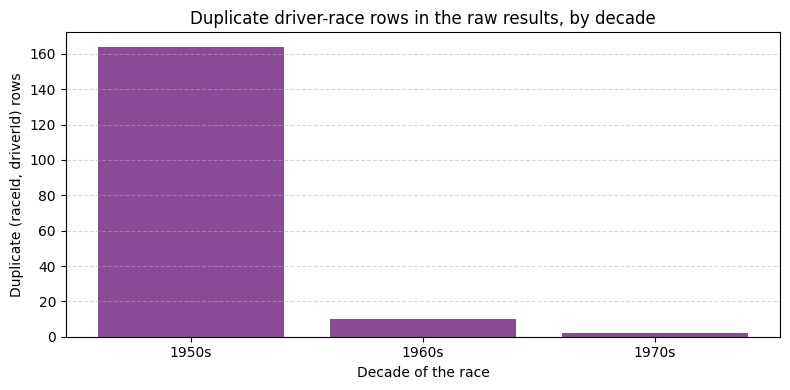

In [6]:
# 2.3 Duplicate (raceId, driverId) Resolution (1950s-1970s data)
# Goal: one row per driver per race. Rule: keep the driver's best-classified row (lowest positionOrder).
# Also check qualifying and sprint_results for the same issue.

print("=== DUPLICATE (raceId, driverId) RESOLUTION ===")

# What are the duplicates?
dup_info = (dfs_clean['results'][dfs_clean['results'].duplicated(subset=['raceId', 'driverId'], keep=False)]
            .merge(dfs_clean['races'][['raceId', 'year', 'name']], on='raceId')
            .merge(dfs_clean['status'], on='statusId'))
dup_groups = dup_info.groupby(['raceId', 'driverId'])
non_start = ['Did not qualify', 'Did not prequalify', 'Withdrew']
print(f"{len(dup_info)} rows in {dup_groups.ngroups} (raceId, driverId) groups, years {dup_info['year'].min()}-{dup_info['year'].max()}")
print(f"  Groups at the Indianapolis 500: {(dup_groups['name'].first() == 'Indianapolis 500').sum()}")
print(f"  Groups where the driver appears for two different constructors: {(dup_groups['constructorId'].nunique() > 1).sum()}")
print(f"  Groups where every row is a non-start (entered twice, started neither): "
      f"{dup_groups['status'].agg(lambda s: s.isin(non_start).all()).sum()}")
print(f"  Groups with at least one podium row: {(dup_groups['positionOrder'].min() <= 3).sum()}")

# Compare with the alternative rule 'keep the car the driver started in' (a row with a grid slot, lowest grid)
best_rule = (dup_info.sort_values(['raceId', 'driverId', 'positionOrder'])
             .drop_duplicates(['raceId', 'driverId']).set_index(['raceId', 'driverId']))
start_rule = (dup_info.assign(no_grid_slot=dup_info['grid'] <= 0)
              .sort_values(['raceId', 'driverId', 'no_grid_slot', 'grid', 'positionOrder'])
              .drop_duplicates(['raceId', 'driverId']).set_index(['raceId', 'driverId'])
              .loc[best_rule.index])
print(f"  Podium label differs between 'best finish' and 'start car' rules: "
      f"{((best_rule['positionOrder'] <= 3) != (start_rule['positionOrder'] <= 3)).sum()} groups")
print(f"  Grid position differs between the two rules: {(best_rule['grid'] != start_rule['grid']).sum()} groups\n")

# RESULTS table
duplicates_before = dfs_clean['results'][dfs_clean['results'].duplicated(subset=['raceId', 'driverId'], keep=False)]
print(f"Results: {len(duplicates_before)} rows in duplicate (raceId, driverId) groups before resolution.")

# Implement the "Best Finish" rule: Sort by positionOrder (ascending) and keep the first
# positionOrder = 1 is the winner
dfs_clean['results'] = dfs_clean['results'].sort_values(by=['raceId', 'driverId', 'positionOrder']).drop_duplicates(subset=['raceId', 'driverId'], keep='first')

remaining_dups = dfs_clean['results'].duplicated(subset=['raceId', 'driverId']).sum()
print(f"Results: Duplicates remaining after resolution: {remaining_dups}")
podium_rows = dfs_clean['results'][dfs_clean['results']['positionOrder'] <= 3].groupby('raceId').size()
print(f"Races with more than 3 podium rows (positionOrder <= 3) after resolution: {(podium_rows > 3).sum()}")

# QUALIFYING table - check for duplicates
if 'qualifyId' in dfs_clean['qualifying'].columns:
    qual_dups = dfs_clean['qualifying'].duplicated(subset=['raceId', 'driverId'], keep=False)
    print(f"Qualifying: Found {qual_dups.sum()} rows with duplicate (raceId, driverId)")
    if qual_dups.sum() > 0:
        dfs_clean['qualifying'] = dfs_clean['qualifying'].sort_values(by=['raceId', 'driverId', 'position']).drop_duplicates(subset=['raceId', 'driverId'], keep='first')

# SPRINT_RESULTS table - check for duplicates
if 'resultId' in dfs_clean['sprint_results'].columns:
    sprint_dups = dfs_clean['sprint_results'].duplicated(subset=['raceId', 'driverId'], keep=False)
    print(f"Sprint Results: Found {sprint_dups.sum()} rows with duplicate (raceId, driverId)")
    if sprint_dups.sum() > 0:
        dfs_clean['sprint_results'] = dfs_clean['sprint_results'].sort_values(by=['raceId', 'driverId', 'position']).drop_duplicates(subset=['raceId', 'driverId'], keep='first')

# Where the duplicates come from: the raw results by decade (shared drives were allowed until 1957)
dup_raw = (dfs_raw['results'][dfs_raw['results'].duplicated(subset=['raceId', 'driverId'], keep=False)]
           .merge(dfs_raw['races'][['raceId', 'year']], on='raceId'))
by_decade = (dup_raw['year'] // 10 * 10).value_counts().sort_index()
print(f"\nDuplicate rows in the raw results, by decade: {by_decade.to_dict()}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([f"{d}s" for d in by_decade.index], by_decade.values, color='#762A83', alpha=0.85)
ax.set_xlabel('Decade of the race')
ax.set_ylabel('Duplicate (raceId, driverId) rows')
ax.set_title('Duplicate driver-race rows in the raw results, by decade')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**[OBSERVATION]:** `results` has **176 rows in 85 duplicate (raceId, driverId) groups**, all between 1950 and 1978. Early F1 allowed drivers to share or swap cars during a race, which produces two rows for one driver (21 of the groups are at the Indianapolis 500). Not every group is a shared drive, though:
- In 16 groups the driver appears for two different constructors.
- In 3 groups every row is a non-start (the driver was entered twice and started neither time).

**Rule: keep the driver's best-classified row (lowest `positionOrder`).** 91 rows are removed and 0 duplicates remain.

**Why this rule:**
- **It matches the prediction target.** The model predicts whether *this driver* finishes on the podium. A shared car's result is credited to each driver who drove it, which is why 18 races still have more than 3 rows with `positionOrder` ≤ 3 after resolution. A driver who shared a car that finished on the podium did score a podium, and keeping the best row labels them that way.
- **The alternative was checked.** Keeping the car the driver started in would change the podium label in 17 of the 85 groups, marking drivers who were credited with a podium as non-podium.
- **Limitation:** the kept row is not always the car the driver started in, so its grid position differs from the start-car row in 56 of 85 groups.
- **Where they come from:** 164 of the 176 rows are from the 1950s, 10 from the 1960s and 2 from the 1970s (bar chart), the era when drivers could share cars.
- **Scope:** every duplicate is from 1950–1978. The modelling table (Section 6) starts in 2003, so this rule does not affect the model.

No duplicates were found in `qualifying` or `sprint_results`.

,Dataset,Rows_Before,Rows_After,Row_Change,Sentinels_Before,Sentinels_After,Sentinel_Reduction,Nulls_Before,Nulls_After,Null_Change
0,circuits,77,77,0,0,0,0,0,0,0
1,constructor_results,12625,12625,0,12608,0,12608,0,12608,12608
2,constructors,212,212,0,0,0,0,0,0,0
3,constructor_standings,13391,13391,0,0,0,0,0,0,0
4,drivers,861,861,0,1559,0,1559,0,1559,1559
5,driver_standings,34863,34863,0,0,0,0,0,0,0
6,lap_times,589081,589081,0,0,0,0,0,0,0
7,pit_stops,11371,11371,0,0,0,0,0,0,0
8,qualifying,10494,10494,0,11600,0,11600,68,11668,11600
9,races,1125,1125,0,11349,0,11349,0,11349,11349


Total sentinels removed: 160,076

Column types before cleaning:
                text  numeric  datetime  duration
results            9        9         0         0
qualifying         3        6         0         0
races             14        4         0         0
sprint_results     6       10         0         0
drivers            8        1         0         0
lap_times          1        5         0         0
pit_stops          2        5         0         0

Column types after cleaning:
                text  numeric  datetime  duration
results            2       16         0         0
qualifying         0        9         0         0
races              2        4         6         6
sprint_results     2       14         0         0
drivers            6        2         1         0
lap_times          0        6         0         0
pit_stops          1        7         0         0


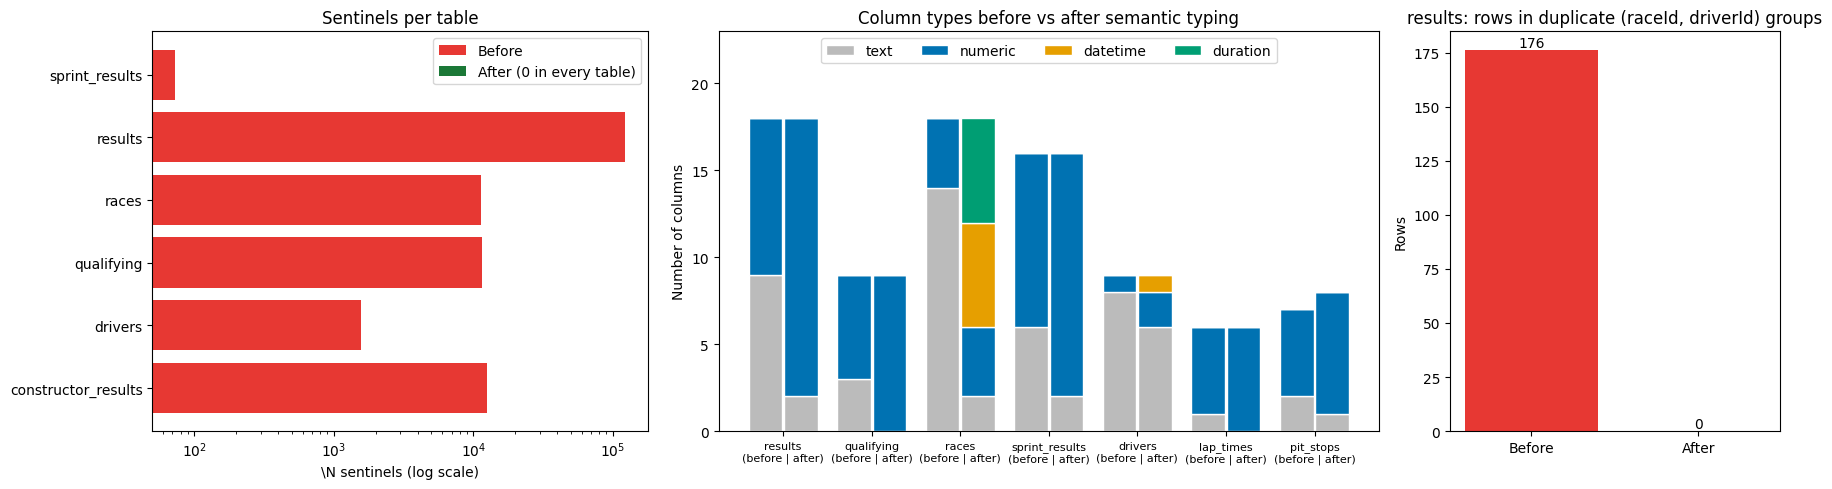

In [7]:
# 2.4 Final EDA (the "after" state): before vs after comparison
# Goal: Quantify the impact of the cleaning pipeline by comparing Before vs After across multiple dimensions.

# Generate "After" Health Report
health_df_after = generate_health_report(dfs_clean)

# Compare Before and After
comparison_df = health_df[['Dataset', 'Rows', 'Cols', 'Nulls', 'Sentinels (\\N)']].copy()
comparison_df = comparison_df.rename(columns={
    'Rows': 'Rows_Before', 'Cols': 'Cols_Before', 
    'Nulls': 'Nulls_Before', 'Sentinels (\\N)': 'Sentinels_Before'
})
comparison_df['Rows_After'] = health_df_after['Rows']
comparison_df['Cols_After'] = health_df_after['Cols']
comparison_df['Nulls_After'] = health_df_after['Nulls']
comparison_df['Sentinels_After'] = health_df_after['Sentinels (\\N)']

comparison_df['Row_Change'] = comparison_df['Rows_After'] - comparison_df['Rows_Before']
comparison_df['Sentinel_Reduction'] = comparison_df['Sentinels_Before'] - comparison_df['Sentinels_After']
comparison_df['Null_Change'] = comparison_df['Nulls_After'] - comparison_df['Nulls_Before']

# Display comparison
display_cols = ['Dataset', 'Rows_Before', 'Rows_After', 'Row_Change', 
                'Sentinels_Before', 'Sentinels_After', 'Sentinel_Reduction',
                'Nulls_Before', 'Nulls_After', 'Null_Change']
display(comparison_df[display_cols])
print(f"Total sentinels removed: {comparison_df['Sentinel_Reduction'].sum():,}")

# Visualising the impact of cleaning: sentinels, column types and duplicate rows, before vs after
def column_kinds(df):
    kinds = ['datetime' if pd.api.types.is_datetime64_any_dtype(df[c]) else
             'duration' if pd.api.types.is_timedelta64_dtype(df[c]) else
             'numeric' if pd.api.types.is_numeric_dtype(df[c]) else 'text' for c in df.columns]
    return pd.Series(kinds).value_counts()

type_tables = ['results', 'qualifying', 'races', 'sprint_results', 'drivers', 'lap_times', 'pit_stops']
kinds_order = ['text', 'numeric', 'datetime', 'duration']
types_before = pd.DataFrame({t: column_kinds(dfs_raw[t]) for t in type_tables}).T.reindex(columns=kinds_order).fillna(0).astype(int)
types_after = pd.DataFrame({t: column_kinds(dfs_clean[t]) for t in type_tables}).T.reindex(columns=kinds_order).fillna(0).astype(int)
print("\nColumn types before cleaning:")
print(types_before.to_string())
print("\nColumn types after cleaning:")
print(types_after.to_string())
dup_before = dfs_raw['results'].duplicated(subset=['raceId', 'driverId'], keep=False).sum()
dup_after = dfs_clean['results'].duplicated(subset=['raceId', 'driverId'], keep=False).sum()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.2, 1.6, 0.8]})
s = comparison_df[comparison_df['Sentinels_Before'] > 0].set_index('Dataset')
axes[0].barh(s.index, s['Sentinels_Before'], color='#E10600', alpha=0.8, label='Before')
axes[0].barh(s.index, s['Sentinels_After'], color='#1B7837', label='After (0 in every table)')
axes[0].set_xscale('log')
axes[0].set_xlabel('\\N sentinels (log scale)')
axes[0].set_title('Sentinels per table')
axes[0].legend()
colors = {'text': '#BBBBBB', 'numeric': '#0072B2', 'datetime': '#E69F00', 'duration': '#009E73'}
x = np.arange(len(type_tables))
for offset, (types, label) in zip([-0.2, 0.2], [(types_before, 'before'), (types_after, 'after')]):
    bottom = np.zeros(len(type_tables))
    for kind in kinds_order:
        axes[1].bar(x + offset, types[kind], 0.38, bottom=bottom, color=colors[kind],
                    edgecolor='white', label=kind if label == 'before' else None)
        bottom += types[kind].to_numpy()
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{t}\n(before | after)' for t in type_tables], fontsize=8)
axes[1].set_ylabel('Number of columns')
axes[1].set_title('Column types before vs after semantic typing')
axes[1].set_ylim(0, max(types_before.sum(axis=1).max(), types_after.sum(axis=1).max()) + 5)
axes[1].legend(ncol=4, loc='upper center')
axes[2].bar(['Before', 'After'], [dup_before, dup_after], color=['#E10600', '#1B7837'], alpha=0.8)
for i, v in enumerate([dup_before, dup_after]):
    axes[2].text(i, v, str(v), ha='center', va='bottom')
axes[2].set_ylabel('Rows')
axes[2].set_title('results: rows in duplicate (raceId, driverId) groups')
plt.tight_layout()
plt.show()

**[OBSERVATION]:** All **160,076** sentinels are gone (0 remain in every table).
- **Null counts** rose by the same amounts, as expected when sentinels become `NaN`. The one exception is `results`, whose null increase (122,260) is smaller than its sentinel count (122,887) because the 91 removed duplicate rows contained some sentinels.
- **Row counts:** only `results` changes, from 26,759 to 26,668 (−91), all from the duplicate resolution.

The chart shows the impact of cleaning:
- **Sentinels:** removed from every table.
- **Column types:** text columns converted. `results` goes from 9 text columns to 2, `races` from 14 to 2 (gaining 6 datetime and 6 duration columns), and `qualifying` and `lap_times` have no text columns left.
- **Duplicates:** the 176 rows in duplicate groups are reduced to 0.

No other rows were lost.

## Section 3: Additional Anomaly Checks (Objective 1)

**[GOAL]:** Look for data problems beyond the checks the milestone requires.

**[LOGIC]:** Values that are impossible given other columns are counted across the whole dataset rather than spotted by eye: a fastest lap slower than the driver's average lap, a date of birth after a race date, a practice or qualifying date after the race, or an implausible driver age.

Merged 8249 driver-races with both fastestLapTime and lap_times data.
Fastest lap SLOWER than average: 17 cases
FastestLapTime != min(lap_seconds) [>0.1s tolerance]: 181 cases
Sample mismatches:
      raceId  driverId  fastestLapTime  min_lap_seconds
243       13        67          85.564           87.846
385       21         7          85.999           87.449
646       34        15         159.612          151.999
859       45         3         170.950          133.966
868       45        16         145.798          142.911
870       45        18         140.041          126.366
875       45        24         202.300          130.715
877       45        26         181.900          129.078
1026      52        21         122.680           89.298
1030      52        29         110.404           90.342

Label given to every results row (lap_check):
lap_check
not checked (no lap data)              18419
consistent                              8068
slower than quickest recorded lap        1

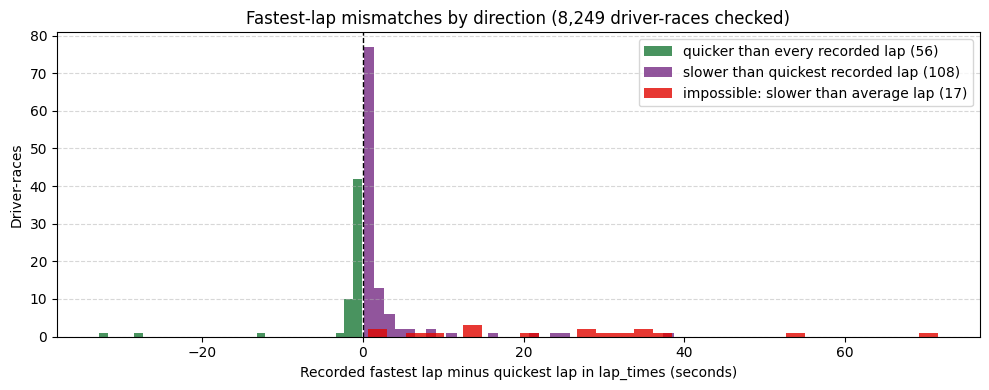

In [8]:
# 3.1 Logical Consistency Scan: Fastest Lap Time Anomaly
# Goal: Vectorized check if any driver's recorded fastestLapTime is SLOWER than their average lap time.

# Merge results with lap_times on (raceId, driverId) where both have valid times
# results.fastestLapTime is now in seconds; lap_times.milliseconds needs conversion
lap_stats = dfs_clean['lap_times'].copy()
lap_stats['lap_seconds'] = lap_stats['milliseconds'] / 1000.0

# Average lap time per driver per race
avg_laps = lap_stats.groupby(['raceId', 'driverId'])['lap_seconds'].mean().reset_index()
avg_laps.columns = ['raceId', 'driverId', 'avg_lap_seconds']

# Merge with results (which has fastestLapTime in seconds)
results_times = dfs_clean['results'][['raceId', 'driverId', 'fastestLapTime', 'positionOrder']].copy()
results_times = results_times.dropna(subset=['fastestLapTime'])

merged = results_times.merge(avg_laps, on=['raceId', 'driverId'], how='inner')
print(f"Merged {len(merged)} driver-races with both fastestLapTime and lap_times data.")

# Anomaly: fastestLapTime > avg_lap_seconds (impossible - fastest lap cannot be slower than average)
anomalies = merged[merged['fastestLapTime'] > merged['avg_lap_seconds']]
anomaly_count = len(anomalies)
print(f"Fastest lap SLOWER than average: {anomaly_count} cases")

# Also check: fastestLapTime should match the minimum lap time for that driver-race
min_laps = lap_stats.groupby(['raceId', 'driverId'])['lap_seconds'].min().reset_index()
min_laps.columns = ['raceId', 'driverId', 'min_lap_seconds']

merged_min = results_times.merge(min_laps, on=['raceId', 'driverId'], how='inner')
# Allow a small timing tolerance (0.1 s)
mismatch = merged_min[abs(merged_min['fastestLapTime'] - merged_min['min_lap_seconds']) > 0.1]
print(f"FastestLapTime != min(lap_seconds) [>0.1s tolerance]: {len(mismatch)} cases")

if len(mismatch) > 0:
    print("Sample mismatches:")
    print(mismatch[['raceId', 'driverId', 'fastestLapTime', 'min_lap_seconds']].head(10))

# Handling: the values are kept, because we cannot tell which table is wrong, and every results row
# gets a label saying in which direction the two tables disagree, so any later use can leave the suspect rows out.
lap_ref = min_laps.merge(avg_laps, on=['raceId', 'driverId'])  # quickest and average recorded lap per driver-race
rows = dfs_clean['results'][['raceId', 'driverId', 'fastestLapTime']].merge(lap_ref, on=['raceId', 'driverId'], how='left')
rows['gap'] = rows['fastestLapTime'] - rows['min_lap_seconds']
checked = rows['fastestLapTime'].notna() & rows['min_lap_seconds'].notna()
rows['lap_check'] = np.select(
    [~checked, rows['fastestLapTime'] > rows['avg_lap_seconds'], rows['gap'] < -0.1, rows['gap'] > 0.1],
    ['not checked (no lap data)', 'impossible: slower than average lap', 'quicker than every recorded lap',
     'slower than quickest recorded lap'],
    default='consistent')
dfs_clean['results']['lap_check'] = rows['lap_check'].to_numpy()  # same row order: a left merge keeps it
print("\nLabel given to every results row (lap_check):")
print(dfs_clean['results']['lap_check'].value_counts().to_string())

fig, ax = plt.subplots(figsize=(10, 4))
for label, color in [('quicker than every recorded lap', '#1B7837'), ('slower than quickest recorded lap', '#762A83'),
                     ('impossible: slower than average lap', '#E10600')]:
    gaps = rows.loc[rows['lap_check'] == label, 'gap']
    ax.hist(gaps, bins=30, color=color, alpha=0.8, label=f"{label} ({len(gaps)})")
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Recorded fastest lap minus quickest lap in lap_times (seconds)')
ax.set_ylabel('Driver-races')
ax.set_title(f"Fastest-lap mismatches by direction ({checked.sum():,} driver-races checked)")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**[OBSERVATION]:**
- **What was checked:** 8,249 driver-races have both a recorded fastest lap (`results`) and lap-by-lap times (`lap_times`).
- **17 are impossible:** the recorded fastest lap is slower than the driver's own average lap.
- **181 disagree by more than 0.1 s** with the quickest lap in `lap_times`, in two directions (chart):
  - **56 are quicker than every lap recorded in `lap_times`** for that driver and race.
  - **The rest are slower than the quickest recorded lap:** 108 by more than 0.1 s, plus the 17 impossible ones above. The largest gap in the sample printed above is race 45, driver 24: 202.3 s against 130.7 s.
  - The data does not say which table is right in either direction, so the notebook does not guess a cause.
- **How it is handled:** we cannot tell which table is right, so no value is changed or guessed. Instead every `results` row gets a label, `lap_check`: consistent (8,068), quicker than every recorded lap (56), slower than the quickest recorded lap (108), impossible (17), or not checked because there is no lap data (18,419, mostly older seasons). The label travels with the master table, and the Section 4 fastest-lap histogram uses it to leave out the 17 impossible values.
- **Why that is enough:** neither column is used anywhere else. Q1–Q3 use finishing positions and race-ending reasons, and lap times are race-time information, so the leakage rule keeps them out of the model (Section 6).


Driver DOB after race date: 0 cases
fp1_date after race date: 0 cases
fp2_date after race date: 0 cases
fp3_date after race date: 0 cases
quali_date after race date: 0 cases
sprint_date after race date: 0 cases
Driver age < 15: 0 cases
Driver age > 55: 4 cases

Drivers older than 55 at a race:
forename   surname              name       date  age_at_race
   Louis    Chiron Monaco Grand Prix 1958-05-18         58.8
   Louis    Chiron Monaco Grand Prix 1956-05-13         56.8
   Louis    Chiron Monaco Grand Prix 1955-05-22         55.8
Philippe Étancelin French Grand Prix 1952-07-06         55.5


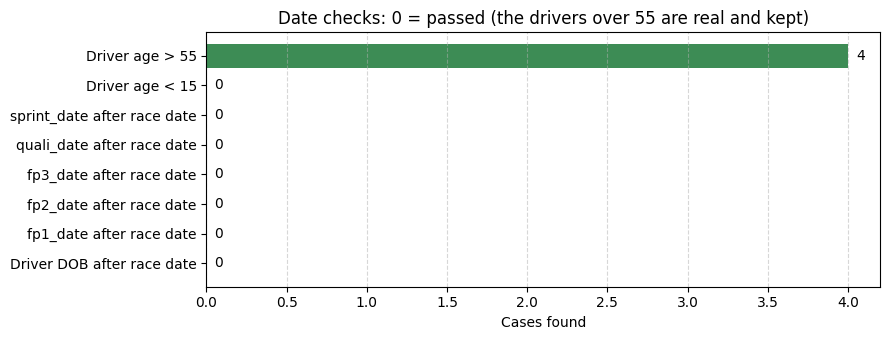

In [9]:
# 3.2 Temporal Consistency Scan
# Goal: Check for temporal anomalies - driver DOB after race date, practice/quali dates after race date, etc.

anomalies_temporal = []

# 3.2.1 Driver DOB after race date
race_driver = dfs_clean['races'][['raceId', 'date']].merge(
    dfs_clean['results'][['raceId', 'driverId']], on='raceId'
).merge(
    dfs_clean['drivers'][['driverId', 'dob']], on='driverId'
)

race_driver = race_driver.dropna(subset=['date', 'dob'])
dob_after_race = race_driver[race_driver['dob'] > race_driver['date']]
anomalies_temporal.append(('Driver DOB after race date', len(dob_after_race)))

# 3.2.2 Practice/Qualifying/Sprint dates after race date
date_cols = ['fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']
for col in date_cols:
    if col in dfs_clean['races'].columns:
        mask = dfs_clean['races'][col].notna() & dfs_clean['races']['date'].notna()
        late = dfs_clean['races'][mask & (dfs_clean['races'][col] > dfs_clean['races']['date'])]
        anomalies_temporal.append((f'{col} after race date', len(late)))

# 3.2.3 Driver age sanity check (age < 15 or > 55 at race)
race_driver['age_at_race'] = (race_driver['date'] - race_driver['dob']).dt.days / 365.25
too_young = race_driver[race_driver['age_at_race'] < 15]
too_old = race_driver[race_driver['age_at_race'] > 55]
anomalies_temporal.append(('Driver age < 15', len(too_young)))
anomalies_temporal.append(('Driver age > 55', len(too_old)))

# Display all temporal anomalies
for desc, count in anomalies_temporal:
    print(f"{desc}: {count} cases")

if len(too_old) > 0:
    print("\nDrivers older than 55 at a race:")
    print(too_old.merge(dfs_clean['drivers'][['driverId', 'forename', 'surname']], on='driverId')
          .merge(dfs_clean['races'][['raceId', 'name']], on='raceId')
          .assign(age_at_race=lambda d: d['age_at_race'].round(1))[['forename', 'surname', 'name', 'date', 'age_at_race']]
          .to_string(index=False))

# Show details if any found
if len(dob_after_race) > 0:
    print("\nDriver DOB after race details:")
    print(dob_after_race[['raceId', 'driverId', 'date', 'dob']].head())

# The checks at a glance: 0 means the check passed
checks = pd.DataFrame(anomalies_temporal, columns=['check', 'cases'])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(checks['check'], checks['cases'], color='#1B7837', alpha=0.85)
for y, v in enumerate(checks['cases']):
    ax.text(v + 0.05, y, str(v), va='center')
ax.set_xlabel('Cases found')
ax.set_title('Date checks: 0 = passed (the drivers over 55 are real and kept)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**[OBSERVATION]:** The temporal checks find no impossible dates: every driver's date of birth precedes their races, and no practice, qualifying or sprint date falls after its race date. No driver was younger than 15. Four entries are older than 55: Louis Chiron at the Monaco Grand Prix in 1955, 1956 and 1958 (aged 55.8–58.8) and Philippe Étancelin at the 1952 French Grand Prix (55.5). These are real drivers of the early era, so the rows are kept. The bar chart shows every check at a glance.

### Additional Data Issues and How They Are Handled

**[GOAL]:** Summarise the data issues found beyond the required checks, how each one is handled, and where in the code.

**[LOGIC]:** Each issue could distort the analyses in Section 5 or the modelling table if left unhandled.

**[OBSERVATION]:** Five issues were found:

**Finding 1: Lap-time recording discrepancies (3.1)**
- **Symptom:** in 8,249 driver-races, 17 recorded fastest laps are slower than the driver's average lap (impossible), and 181 disagree with the quickest lap in `lap_times` by more than 0.1 s (56 quicker than every recorded lap; 108 slower than the quickest one, plus the 17 impossible ones).
- **Handled in the 3.1 cell:** the values are kept, because we cannot tell which table is wrong, and every `results` row gets a `lap_check` label. The Section 4 histogram leaves out the 17 impossible values using that label. Neither column is used by Q1–Q3 or by the model (lap times are race-time information).

**Finding 2: Grid = 0 means "no grid slot" (1)**
- **Symptom:** 1,638 rows in `results` have `grid = 0`. 92.1% of them never started; since 2003 most are pit-lane starts. None reached the podium.
- **Handled:** Q1 counts only grid 1–2 (`between(1, 2)`), Q2 only `grid >= 1`, and Section 6 (`add_grid_features`) turns a pit-lane start into the back of the field with a `pit_lane_start` flag. Grid 0 is never treated as a position ahead of pole.

**Finding 3: Nationality words vs country names (Q2)**
- **Symptom:** `drivers.nationality` uses words like "British" while `circuits.country` uses names like "UK": no nationality matches a country directly (0 matches, printed in Q2).
- **Handled in the Q2 cell:** `nationality_to_country` maps all 43 nationalities (0 unmapped), after `.str.strip()` removes stray spaces (e.g. 'Argentinian '). Section 6 reuses it for the home-race candidate feature.

**Finding 4: Renamed teams (Q3 and Section 6)**
- **Symptom:** teams change names and get a new `constructorId` each time (Toro Rosso → AlphaTauri → RB, Lotus F1 → Renault → Alpine, Force India → Racing Point → Aston Martin, Sauber → Alfa Romeo → Sauber).
- **Handled in Q3:** `TEAM_NAMES` merges the names, because Q3 compares a team across the two eras (Toro Rosso in 2014–2021 is RB in 2022–2024). Red Bull Racing and its junior team stay separate.
- **Handled differently in Section 6:** team form and team standings follow `constructorId`, so a renamed team starts a new history, as the course introduction asks ("a constructor form feature must follow constructorId, and we should accept that renames reset history"). The data also reuses a few ids decades apart (for example Mercedes in 1955 and again from 2010), so an id that comes back after more than a season away starts a new history too (`build_table` in 6.3).

**Finding 5: Drivers older than 55 (3.2)**
- **Symptom:** four entries are drivers over 55 (Louis Chiron three times, Philippe Étancelin once, all in the 1950s).
- **Handled:** kept, because they are real drivers. They are from before 2003, so they are history only and never modelling rows.


## Section 4: The Master Merge (Objective 1 → 2)

**[GOAL]:** Combine the cleaned tables into one master table (one row per driver per race) for the multi-table questions in Objective 2.

**[LOGIC]:** A sequence of left joins starting from `results`, so every race result is kept even if a descriptive detail were missing. Columns are selected explicitly to avoid name clashes and are renamed for clarity. The cell also defines `took_the_start`: the single rule for which entries count as race starts, used by Q1–Q3 and Section 6. Entries that never qualified or withdrew before completing a lap are not starts. A car that broke down on the way to the grid is a start: after qualifying it was expected to race, so its race counts like an early retirement.

In [10]:
# 4.0 Before merging: stop here if any cleaning step from Sections 2-3 is missing
assert sum(int((df == '\\N').sum().sum()) for df in dfs_clean.values()) == 0, "\\N placeholders remain"
assert not dfs_clean['results'].duplicated(subset=['raceId', 'driverId']).any(), "a driver appears twice in a race"
assert pd.api.types.is_datetime64_any_dtype(dfs_clean['races']['date']), "race dates are not dates"
assert pd.api.types.is_datetime64_any_dtype(dfs_clean['drivers']['dob']), "birth dates are not dates"
assert pd.api.types.is_numeric_dtype(dfs_clean['results']['grid']), "grid is not numeric"
assert pd.api.types.is_numeric_dtype(dfs_clean['results']['fastestLapTime']), "fastest lap is not numeric"
print("Checks before the merge passed: no \\N left, one row per driver per race, dates and numbers typed\n")

# 4.1 The Master Merge
# Goal: Merge results with drivers, races, constructors, circuits, and status.
# Explicit column selection to avoid MergeError on duplicate column names.

cols_drivers = ['driverId', 'driverRef', 'forename', 'surname', 'nationality', 'dob']
cols_races = ['raceId', 'year', 'round', 'name', 'circuitId', 'date']
cols_constructors = ['constructorId', 'name', 'nationality']
cols_circuits = ['circuitId', 'name', 'location', 'country', 'lat', 'lng']
cols_status = ['statusId', 'status']

# Step-by-step merge with explicit column selection
df_master = dfs_clean['results'].merge(
    dfs_clean['drivers'][cols_drivers], on='driverId', how='left', validate='many_to_one'
).merge(
    dfs_clean['races'][cols_races], on='raceId', how='left', validate='many_to_one'
).merge(
    dfs_clean['constructors'][cols_constructors], on='constructorId', how='left', 
    suffixes=('', '_constructor'), validate='many_to_one'
).merge(
    dfs_clean['circuits'][cols_circuits], on='circuitId', how='left', 
    suffixes=('', '_circuit'), validate='many_to_one'
).merge(
    dfs_clean['status'][cols_status], on='statusId', how='left', validate='many_to_one'
)

# Rename duplicated columns
df_master = df_master.rename(columns={
    'name': 'race_name',
    'name_constructor': 'constructor_name',
    'nationality_constructor': 'constructor_nationality',
    'name_circuit': 'circuit_name',
    'location': 'circuit_location',
    'country': 'circuit_country',
    'status': 'status_description'
})

# 4.2 Join Audit with Null Checks
original_count = len(dfs_clean['results'])
merged_count = len(df_master)

print(f"Original results count: {original_count}")
print(f"Merged master count: {merged_count}")
print(f"Row difference: {merged_count - original_count}")

# Check for nulls in key dimension columns (indicates missing joins)
key_cols = ['driverId', 'raceId', 'constructorId', 'circuitId', 'circuit_country', 'nationality', 'year']
null_check = df_master[key_cols].isnull().sum()
print("\nNulls in key dimension columns:")
print(null_check[null_check > 0])

# 4.3 Column Optimization
# Keep driverId, raceId for grain verification; drop other IDs
cols_to_drop = [col for col in df_master.columns if col.endswith('Id') and col not in ['driverId', 'raceId']]
df_master_final = df_master.drop(columns=cols_to_drop)

print(f"\nFinal master shape: {df_master_final.shape}")
print(f"Columns: {list(df_master_final.columns)}")

# 4.4 Who took the start? One rule, used by Q1-Q3 and Section 6.
# Not a start: did not qualify (including positionText 'F' = failed to qualify, e.g. injured in practice),
# did not pre-qualify, failed the 107% rule, or withdrew without completing a lap.
# 'Withdrew' after completing laps means the car was retired during the race, so that driver did start.
# A car that broke down before the start (e.g. on the way to the grid, positionText 'W') counts as a start:
# after qualifying it was expected to start, so its race ends without a podium, like an early retirement.
def took_the_start(df):
    """True for entries that count as race starts (see the rules above)."""
    never_qualified = (df['status_description'].isin(['Did not qualify', 'Did not prequalify', '107% Rule'])
                       | (df['positionText'] == 'F'))
    withdrew_before_start = (df['status_description'] == 'Withdrew') & (df['laps'] == 0)
    return ~(never_qualified | withdrew_before_start)

started = took_the_start(df_master)
print(f"\nEntries that never took the start: {(~started).sum()} of {len(df_master)}")
print(df_master.loc[~started, 'status_description'].value_counts().to_string())
withdrew_racing = (df_master['status_description'] == 'Withdrew') & started
print(f"'Withdrew' entries that completed laps (they started, then retired during the race): {withdrew_racing.sum()}")
broke_before_start = (df_master['positionText'] == 'W') & started & (df_master['laps'] == 0)
print(f"Cars that broke down before the start (marked 'W', no lap completed), counted as starts: {broke_before_start.sum()} "
      f"({(broke_before_start & (df_master['year'] >= 2003)).sum()} of them since 2003)")

# Field sizes per decade: when more cars entered than could start, the non-qualifiers still have result rows, so the
# podium rate per ENTRY drops; per STARTER it stays close to the modern rate (Indianapolis 500 left out, as in Q1-Q3 and Section 6)
fields = df_master[df_master['race_name'] != 'Indianapolis 500'].assign(started=started, podium=df_master['positionOrder'] <= 3)
fields['decade'] = fields['year'] // 10 * 10
decades = fields.groupby('decade').agg(races=('raceId', 'nunique'), entries=('raceId', 'size'), starters=('started', 'sum'),
                                       podium_per_entry=('podium', 'mean'))
decades['podium_per_starter'] = fields[fields['started']].groupby('decade')['podium'].mean()
decades['entries_per_race'] = (decades['entries'] / decades['races']).round(1)
decades['starters_per_race'] = (decades['starters'] / decades['races']).round(1)
for col in ('podium_per_entry', 'podium_per_starter'):
    decades[col] = decades[col].map('{:.1%}'.format)
print("\nEntries, starters and podium rate per decade (Indianapolis 500 left out):")
print(decades[['races', 'entries_per_race', 'starters_per_race', 'podium_per_entry', 'podium_per_starter']].to_string())
field_size = fields[fields['started'] & (fields['year'] >= 2003)].groupby(['year', 'race_name']).size()  # the modelling seasons
small = field_size[field_size < 18]
print(f"Starters per race from 2003: {field_size.min()}-{field_size.max()}; fields under 18: "
      + ', '.join(f"{y} {r} ({n})" for (y, r), n in small.items()))

df_master_final.head(10)

Checks before the merge passed: no \N left, one row per driver per race, dates and numbers typed

Original results count: 26668
Merged master count: 26668
Row difference: 0

Nulls in key dimension columns:
Series([], dtype: int64)

Final master shape: (26668, 33)
Columns: ['raceId', 'driverId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'lap_check', 'driverRef', 'forename', 'surname', 'nationality', 'dob', 'year', 'round', 'race_name', 'date', 'constructor_name', 'constructor_nationality', 'circuit_name', 'circuit_location', 'circuit_country', 'lat', 'lng', 'status_description']

Entries that never took the start: 1590 of 26668
status_description
Did not qualify       1024
Did not prequalify     330
Withdrew               224
107% Rule                9
Injury                   3
'Withdrew' entries that completed laps (they started, then retired during the race): 23
C

,raceId,driverId,number,grid,position,positionText,positionOrder,points,laps,time,...,race_name,date,constructor_name,constructor_nationality,circuit_name,circuit_location,circuit_country,lat,lng,status_description
0,1,1,1.0,18,NaN,D,20,0.0,58,NaN,...,Australian Grand Prix,2009-03-29,McLaren,British,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Disqualified
1,1,2,6.0,9,10.0,10,10,0.0,58,+7.085,...,Australian Grand Prix,2009-03-29,BMW Sauber,German,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Finished
2,1,3,16.0,5,6.0,6,6,3.0,58,+5.722,...,Australian Grand Prix,2009-03-29,Williams,British,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Finished
3,1,4,7.0,10,5.0,5,5,4.0,58,+4.879,...,Australian Grand Prix,2009-03-29,Renault,French,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Finished
4,1,5,2.0,12,NaN,R,19,0.0,0,NaN,...,Australian Grand Prix,2009-03-29,McLaren,British,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Collision
5,1,6,17.0,11,NaN,R,18,0.0,17,NaN,...,Australian Grand Prix,2009-03-29,Williams,British,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Accident
6,1,7,11.0,17,8.0,8,8,1.0,58,+6.298,...,Australian Grand Prix,2009-03-29,Toro Rosso,Italian,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Finished
7,1,8,4.0,7,15.0,15,15,0.0,55,NaN,...,Australian Grand Prix,2009-03-29,Ferrari,Italian,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Differential
8,1,9,5.0,4,14.0,14,14,0.0,55,NaN,...,Australian Grand Prix,2009-03-29,BMW Sauber,German,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Collision
9,1,10,10.0,19,4.0,4,4,5.0,58,+4.435,...,Australian Grand Prix,2009-03-29,Toyota,Japanese,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,Finished


**[OBSERVATION]:** The Master Merge produces a 1:1 row mapping with `results` (26,668 rows). There are no nulls in the key columns (`driverId`, `raceId`, `constructorId`, `circuitId`, `year`, `nationality`, `circuit_country`), so every join found its match. The grain is preserved, one row per driver per race, and the final master table has 33 columns covering driver, team, race, circuit and status details, plus the `lap_check` label from 3.1. The checks that run before the merge (4.0) passed: no `\N` placeholder is left, there is one row per driver per race, and dates and numbers are typed.

**Race starts:** `took_the_start` marks 1,590 of the 26,668 entries as not race starts: 1,024 did not qualify, 330 did not pre-qualify, 224 withdrew before completing a lap, 9 failed the 107% rule and 3 injured drivers did not qualify. Another 23 "Withdrew" entries completed laps: those drivers started and were retired during the race, so they count as starts. 108 cars broke down before the start (29 of them since 2003); they also count as starts, because after qualifying they were expected to race.

**Field sizes (per decade, Indianapolis 500 left out):** in the 1970s–1990s more cars entered than could start, and the non-qualifiers still have result rows. In the 1980s a race had 28.9 entries but 25.2 starters, so only 10.4% of entries reached the podium, against 11.9% of starters; in the 2020s both are 15.0%. Counting starters only (`took_the_start`) therefore removes most of the drop in the podium rate per row; what is left comes from bigger fields (about 25 starters sharing 3 podiums). From 2003, the seasons the models use, every race has 18 to 24 starters except the 2005 United States Grand Prix (6) and the 2015 Australian Grand Prix (15).

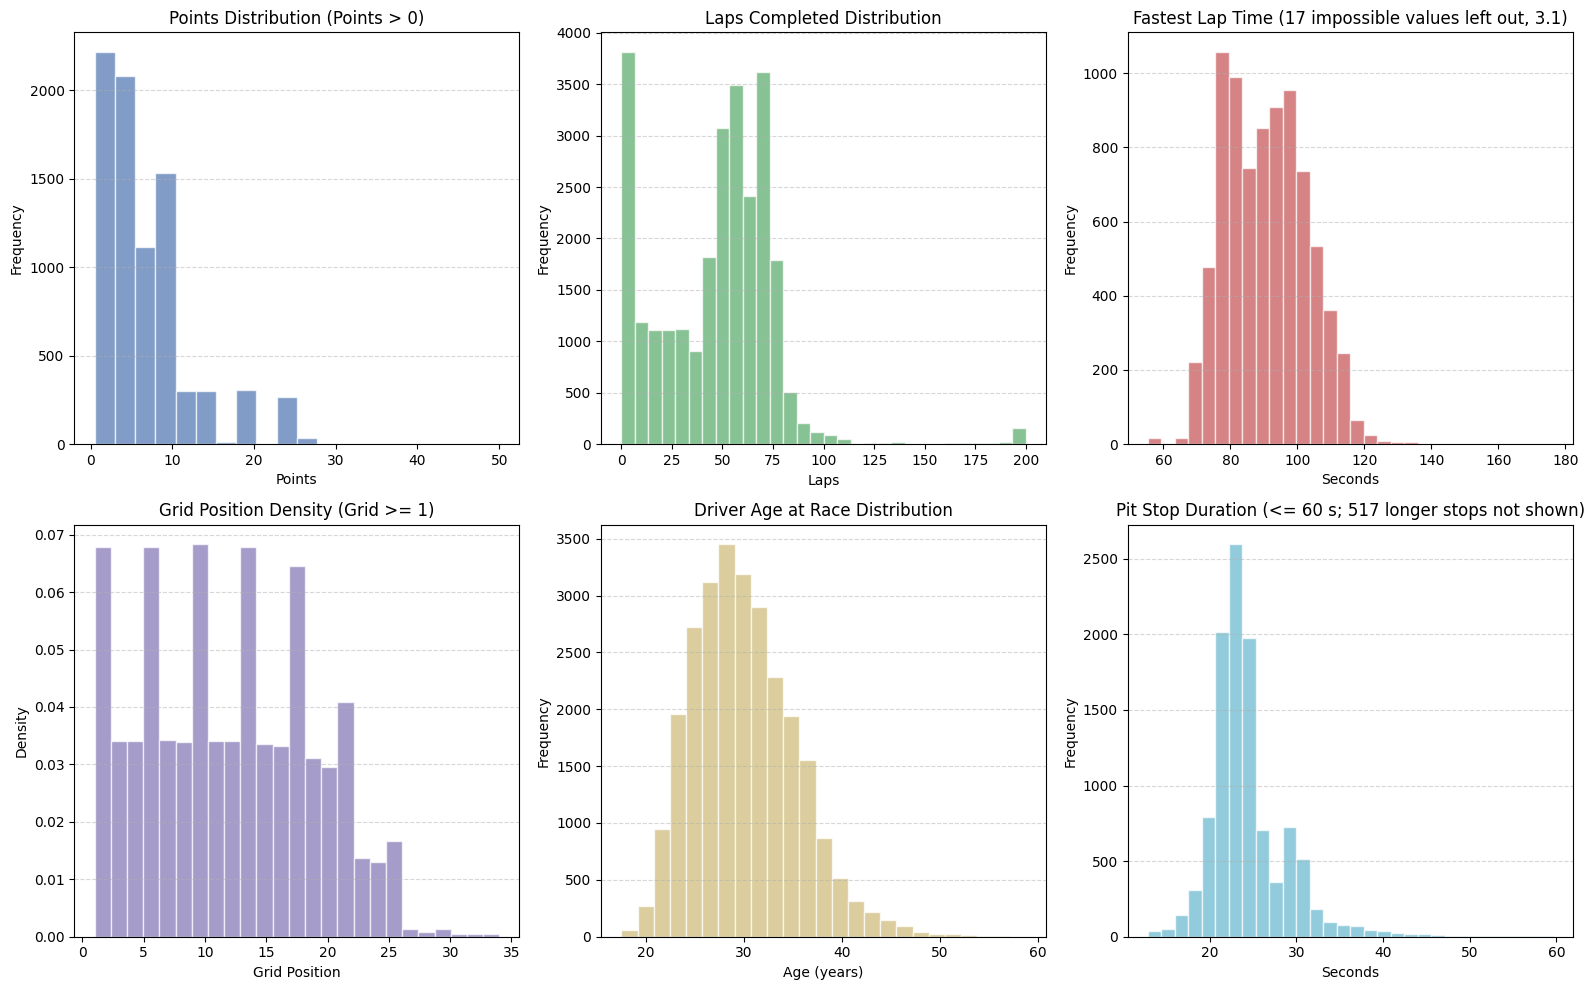

Pit stops: median 23.6 s; 517 of 11371 stops last over 60 s (longest 3069 s) and are left out of the histogram.
Laps chart, first bar (0-6 laps): 3813 entries: 1589 never started, 940 counted as starts but completed no lap, 1284 retired within 6 laps
Entries with a recorded fastest lap (fastest-lap chart): 30.9%
Fastest-lap chart: 17 impossible values left out (3.1); longest plotted lap 176.2 s


In [11]:
# Additional Histograms for Key Numeric Columns (Objective 1 EDA)
# Goal: Visualize distributions of key numeric variables to understand data shape

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# 1. Points distribution (excluding 0)
points_data = df_master_final[df_master_final['points'] > 0]['points']
axes[0].hist(points_data, bins=20, color='#4C72B0', alpha=0.7, edgecolor='white')
axes[0].set_title('Points Distribution (Points > 0)')
axes[0].set_xlabel('Points')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Laps completed distribution
laps_data = df_master_final['laps'].dropna()
axes[1].hist(laps_data, bins=30, color='#55A868', alpha=0.7, edgecolor='white')
axes[1].set_title('Laps Completed Distribution')
axes[1].set_xlabel('Laps')
axes[1].set_ylabel('Frequency')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 3. Fastest Lap Time (seconds) distribution
impossible = df_master_final['lap_check'] == 'impossible: slower than average lap'  # label from 3.1
flt_data = df_master_final.loc[~impossible, 'fastestLapTime'].dropna()
axes[2].hist(flt_data, bins=30, color='#C44E52', alpha=0.7, edgecolor='white')
axes[2].set_title(f'Fastest Lap Time ({impossible.sum()} impossible values left out, 3.1)')
axes[2].set_xlabel('Seconds')
axes[2].set_ylabel('Frequency')
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

# 4. Grid position distribution (already shown, but with density)
grid_data = df_master_final[df_master_final['grid'] >= 1]['grid']
axes[3].hist(grid_data, bins=25, color='#8172B3', alpha=0.7, edgecolor='white', density=True)
axes[3].set_title('Grid Position Density (Grid >= 1)')
axes[3].set_xlabel('Grid Position')
axes[3].set_ylabel('Density')
axes[3].grid(axis='y', linestyle='--', alpha=0.5)

# 5. Driver Age at Race distribution
df_master_final['age_at_race'] = (df_master_final['date'] - df_master_final['dob']).dt.days / 365.25
age_data = df_master_final['age_at_race'].dropna()
axes[4].hist(age_data, bins=25, color='#CCB974', alpha=0.7, edgecolor='white')
axes[4].set_title('Driver Age at Race Distribution')
axes[4].set_xlabel('Age (years)')
axes[4].set_ylabel('Frequency')
axes[4].grid(axis='y', linestyle='--', alpha=0.5)

# 6. Pit stop duration distribution (stops over 60 s are left out of the plot so the normal range is readable)
pit_dur = dfs_clean['pit_stops']['milliseconds'].dropna() / 1000.0
long_stops = pit_dur > 60
axes[5].hist(pit_dur[~long_stops], bins=30, color='#64B5CD', alpha=0.7, edgecolor='white')
axes[5].set_title(f'Pit Stop Duration (<= 60 s; {long_stops.sum()} longer stops not shown)')
axes[5].set_xlabel('Seconds')
axes[5].set_ylabel('Frequency')
axes[5].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Pit stops: median {pit_dur.median():.1f} s; {long_stops.sum()} of {len(pit_dur)} stops last over 60 s "
      f"(longest {pit_dur.max():.0f} s) and are left out of the histogram.")
few_laps = df_master_final[df_master_final['laps'] < 7]  # the first bar of the laps chart (0-6 laps)
print(f"Laps chart, first bar (0-6 laps): {len(few_laps)} entries: {(~took_the_start(few_laps)).sum()} never started, "
      f"{(took_the_start(few_laps) & (few_laps['laps'] == 0)).sum()} counted as starts but completed no lap, "
      f"{(took_the_start(few_laps) & (few_laps['laps'] > 0)).sum()} retired within 6 laps")
print(f"Entries with a recorded fastest lap (fastest-lap chart): {df_master_final['fastestLapTime'].notna().mean():.1%}")
print(f"Fastest-lap chart: {impossible.sum()} impossible values left out (3.1); longest plotted lap {flt_data.max():.1f} s")

**[OBSERVATION]:** The six distributions look as expected for F1 data, with a few things worth knowing before modelling:
- **What is plotted:** every entry in the master table, including the 1,590 that are not race starts (Section 4). Only 30.9% of entries have a recorded fastest lap, so that chart covers those entries only.
- **Points:** most point-scoring finishes earn under 10 points. The separate peaks (for example near 18 and 25 points) come from fixed points scales, and those scales changed over the decades, so raw points are not comparable across eras. This is why Section 6 uses a driver's *share of the leader's points* instead of raw points.
- **Laps completed:** most rows sit between about 45 and 78 laps, a normal race distance. The tall bar at the far left (0–6 laps) mixes three groups, because the charts include every entry: 1,589 entries that never started, 940 that count as starts but completed no lap, and 1,284 that retired within 6 laps. The small peak at 200 laps is the Indianapolis 500 (a 200-lap race), a different kind of event that Q1, Q2 and Section 6 leave out.
- **Fastest lap time:** mostly between about 70 and 115 seconds, because tracks differ in length, with a thin tail up to 176.2 seconds (the longest plotted lap, printed above). Section 3.1 found that some of these recorded times do not match the lap-by-lap data; the 17 impossible ones are left out of this chart (its title says so).
- **Grid position:** the alternating tall and short bars are a binning effect (some bars cover two grid positions), not a pattern in the data. A few grids go beyond 26 cars, up to about 34.
- **Age at race:** most drivers are between about 22 and 38, with the peak around 28–30.
- **Pit stops:** the median stop lasts 23.6 s (the time spent in the pit lane, not only standing still). 517 of the 11,371 stops last over 60 s; the longest, 3,069 s, is most likely a stop during a red-flag stoppage or a long repair. These are left out of the histogram so that the normal range stays readable.

## Section 5: Objective 2 - Data Engineering Questions

**[GOAL]:** Use the cleaned master table to answer the three data-engineering questions: front-row conversion by circuit (Q1), home-race advantage (Q2) and constructor mechanical-retirement rates (Q3).

**[LOGIC]:** Each question follows the same pattern: filter the relevant rows, aggregate, visualise, and test whether differences could be due to chance. Each one states its grain (what one row is), its missing data and, where relevant, the pre-race cutoff.

**[TEMPORAL GUARD]:** Q1–Q3 are descriptive analyses of past races, so they use race outcomes (finishing positions, retirement reasons) by design. That is allowed here because nothing in this section becomes a model feature. The pre-race cutoff applies to the modelling table in Objective 3, where only information available before the race starts may be used.

### Question 1: Front-Row → Podium Conversion

**[GOAL]:** Find which circuits most often turn a front-row start (starting 1st or 2nd) into a podium (finishing in the top 3), and whether that ranking changed after the 2014 hybrid era. Keep qualifying position separate from grid position, because grid penalties and pit-lane starts can move a driver away from where they qualified.

**[LOGIC]:**
1. Join `results` (grid, finishing order) → `races` (year) → `circuits` (circuit name), and `qualifying` (qualifying position) on `raceId` + `driverId`.
2. Front-row start = `grid` 1–2, among entries that took the start (`took_the_start`, Section 4). Rows with `grid = 0` have no grid slot (non-starters or pit-lane starts), so they are never front-row starts. The Indianapolis 500 (1950–1960) is left out, as in Q2: it was effectively a separate American event, and its grid had three cars per row, so "front row = grid 1–2" does not fit it. Podium = `positionOrder` ≤ 3.
3. Conversion rate per circuit = podiums ÷ front-row starters, with a 95% Wilson confidence interval. A circuit needs at least 8 distinct races in a period to be ranked, so circuits used only a few times can't top the list by luck.
4. Answer overall first (all years), including the first and last year each top circuit hosted a race. Then compare **before 2014 (1950–2013)** with **2014–2024**, as the question asks, and print the share of front-row starters who did not finish in each period.
5. Side check: also compare **2003–2013** with 2014–2024. Reliability improved a lot over the decades, and unevenly across circuits: Monaco's pre-2014 record goes back to 1950, while Bahrain's starts in 2004. A recent "before" period shows how much of the change belongs to the hybrid era itself. From 2003 on, every season has qualifying data for every race.
6. Qualifying vs grid: count how often a front-row grid slot differs from the qualifying position, then repeat the period comparison using qualifying position instead of grid (2003 onwards only).
7. Summarise each ranking change with a Spearman rank correlation (1 = same order in both periods, 0 = no relationship).

**[GRAIN / MISSINGNESS / CUTOFF]:** One row per front-row starter (two per race); sample sizes are reported as distinct races. Qualifying positions are missing before 1994 and patchy from 1994 to 2002 (coverage printed below), so qualifying-based results use 2003 onwards only. Grid and qualifying positions are both known before the race starts; the race result is only the outcome being measured.

Front-row entries left out: 26 (23 at the Indianapolis 500, 3 that never took the start)

Share of races with qualifying positions recorded:
span
1950-1993      0%
1994-2002     44%
2003-2024    100%

Front-row starters: 2217, of which 984 have a qualifying record
Grid differs from qualifying position: 49 of 984 (5.0%)
2003-2024: 38 of 854 front-row qualifiers (4.4%) did not start from the front row (grid penalty or pit-lane start)

=== OVERALL (1950-2024): front-row starters finish on the podium 60.4% of the time ===
Top 10 circuits (min 8 races), with the first and last year each circuit hosted a race:
                               rate ci_low ci_high  races  first_year  last_year
circuit_name                                                                    
Circuit of the Americas         83%    64%     93%     12        2012       2024
Sochi Autodrom                  81%    57%     93%      8        2014       2021
Circuit de Nevers Magny-Cours   81%    65%     90%     18       

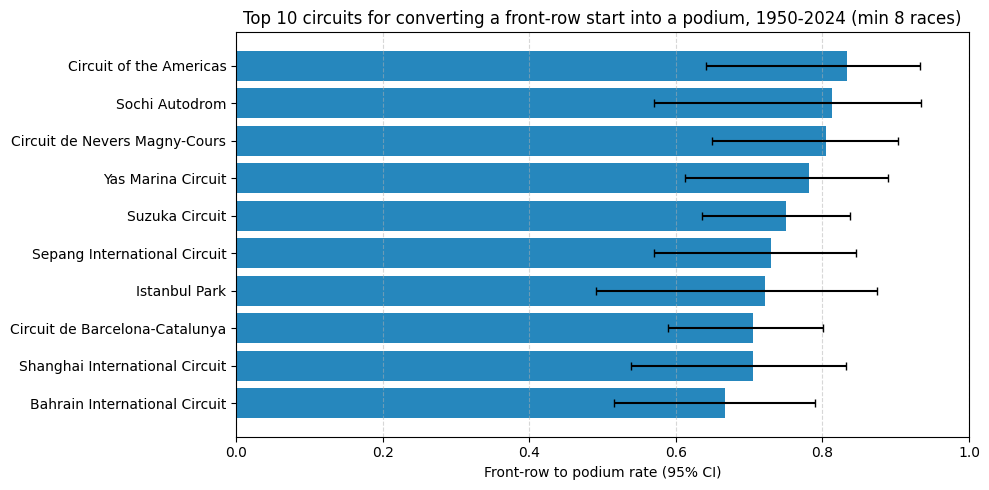

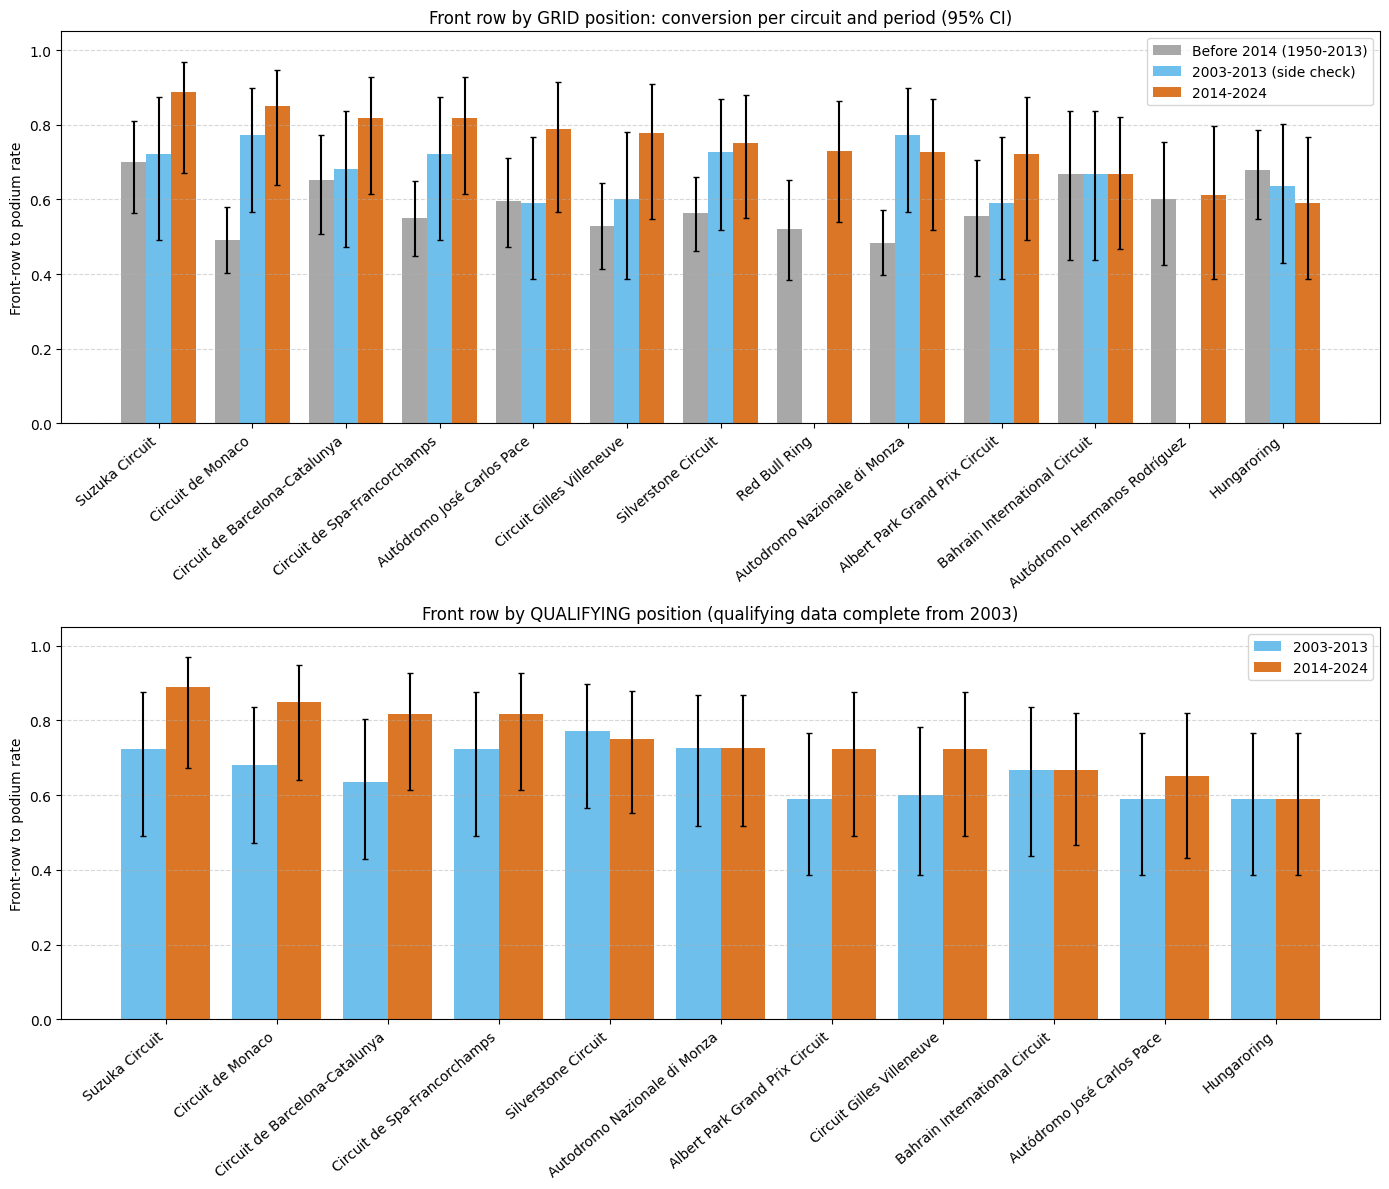

In [12]:
# Q1 Implementation: Front-Row to Podium Conversion
# Front-row start = grid 1 or 2. Podium = positionOrder <= 3.
# Grain: one row per front-row starter (two per race). Conversion rate = podiums / front-row starters;
# sample size is reported as distinct races.
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint

MIN_RACES = 8  # a circuit needs >= 8 distinct races in a period to be ranked (avoids one-off flukes)
PRE, MID, HYB = '1950-2013', '2003-2013', '2014-2024'
PERIODS = {PRE: (1950, 2013), MID: (2003, 2013), HYB: (2014, 2024)}

# Only entries that took the start; the Indianapolis 500 is left out as in Q2 (three cars per grid row)
q1_rows = took_the_start(df_master_final) & (df_master_final['race_name'] != 'Indianapolis 500')
front_left_out = df_master_final['grid'].between(1, 2) & ~q1_rows
print(f"Front-row entries left out: {front_left_out.sum()} "
      f"({(front_left_out & (df_master_final['race_name'] == 'Indianapolis 500')).sum()} at the Indianapolis 500, "
      f"{(front_left_out & ~took_the_start(df_master_final)).sum()} that never took the start)\n")

# Attach the qualifying position next to the starting grid position
q1_base = df_master_final[q1_rows].merge(
    dfs_clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
    on=['raceId', 'driverId'], how='left', validate='one_to_one')
q1_base['is_podium'] = q1_base['positionOrder'] <= 3

# 1. Qualifying coverage: which years can be analysed by qualifying position at all?
race_q = q1_base.groupby('raceId').agg(year=('year', 'first'),
                                       has_quali=('quali_pos', lambda s: s.notna().any()))
race_q['span'] = pd.cut(race_q['year'], [1949, 1993, 2002, 2024], labels=['1950-1993', '1994-2002', '2003-2024'])
print("Share of races with qualifying positions recorded:")
print(race_q.groupby('span', observed=True)['has_quali'].mean().map('{:.0%}'.format).to_string())

# 2. Grid vs qualifying: how often does a front-row grid slot differ from the qualifying position?
front_grid = q1_base[q1_base['grid'].between(1, 2)]
fg_q = front_grid.dropna(subset=['quali_pos'])
differs = fg_q['grid'] != fg_q['quali_pos']
print(f"\nFront-row starters: {len(front_grid)}, of which {len(fg_q)} have a qualifying record")
print(f"Grid differs from qualifying position: {differs.sum()} of {len(fg_q)} ({differs.mean():.1%})")
modern = q1_base[q1_base['year'] >= 2003]
front_q_modern = modern[modern['quali_pos'] <= 2]
lost = front_q_modern[~front_q_modern['grid'].between(1, 2)]
print(f"2003-2024: {len(lost)} of {len(front_q_modern)} front-row qualifiers ({len(lost)/len(front_q_modern):.1%}) "
      f"did not start from the front row (grid penalty or pit-lane start)")

# 3. Conversion rate per circuit within a period, with 95% Wilson confidence intervals
def conversion(df, pos_col, start, end):
    """Podium rate of front-row starters (pos_col in 1-2) per circuit between start and end (inclusive)."""
    sub = df[df['year'].between(start, end) & df[pos_col].between(1, 2)]
    out = sub.groupby('circuit_name').agg(podiums=('is_podium', 'sum'),
                                          starters=('is_podium', 'size'),
                                          races=('raceId', 'nunique'))
    out['rate'] = out['podiums'] / out['starters']
    out['ci_low'], out['ci_high'] = proportion_confint(out['podiums'], out['starters'], method='wilson')
    return out[out['races'] >= MIN_RACES]

def rank_change(before, after, name_before, name_after):
    """Rank circuits present in both periods; positive rank change = moved up in the later period."""
    t = pd.DataFrame({name_before: before['rate'], f'races {name_before}': before['races'],
                      name_after: after['rate'], f'races {name_after}': after['races']}).dropna()
    for c in [f'races {name_before}', f'races {name_after}']:
        t[c] = t[c].astype(int)
    t[f'rank {name_before}'] = t[name_before].rank(ascending=False, method='min').astype(int)
    t[f'rank {name_after}'] = t[name_after].rank(ascending=False, method='min').astype(int)
    t['rank change'] = t[f'rank {name_before}'] - t[f'rank {name_after}']
    rho, p = spearmanr(t[name_before], t[name_after])
    return t.sort_values(name_after, ascending=False, kind='stable'), rho, p  # ties stay alphabetical

def show(t):
    out = t.copy()
    for c in out.columns:
        if not c.startswith(('rank', 'races')):
            out[c] = out[c].map('{:.0%}'.format)
    print(out.to_string())

# 4. Overall answer (all years)
front_all = q1_base[q1_base['grid'].between(1, 2)]
overall = conversion(q1_base, 'grid', 1950, 2024).sort_values('rate', ascending=False, kind='stable')  # ties stay alphabetical
print(f"\n=== OVERALL (1950-2024): front-row starters finish on the podium {front_all['is_podium'].mean():.1%} of the time ===")
print(f"Top 10 circuits (min {MIN_RACES} races), with the first and last year each circuit hosted a race:")
hosted = q1_base.groupby('circuit_name')['year'].agg(first_year='min', last_year='max')
top10 = overall.head(10).join(hosted)[['rate', 'ci_low', 'ci_high', 'races', 'first_year', 'last_year']]
print(top10.assign(**{c: top10[c].map('{:.0%}'.format) for c in ['rate', 'ci_low', 'ci_high']}).to_string())

# Finished = 'Finished' or classified laps down ('+1 Lap', '+2 Laps', ...); anything else is a retirement/DSQ
front_all_finished = front_all['status_description'].str.match(r'^(Finished|\+\d+ Laps?)$')
print("\nFront-row conversion by period (all circuits), and share of front-row starters who did not finish:")
for label, (start, end) in PERIODS.items():
    in_period = front_all['year'].between(start, end)
    s = front_all[in_period]
    print(f"  {label}: podium {s['is_podium'].mean():.1%}, did not finish {1 - front_all_finished[in_period].mean():.1%} "
          f"({s['raceId'].nunique()} races)")

# 5. Did the ranking change after 2014? (grid-based)
grid_rates = {label: conversion(q1_base, 'grid', s, e) for label, (s, e) in PERIODS.items()}
tab_pre, rho_pre, p_pre = rank_change(grid_rates[PRE], grid_rates[HYB], PRE, HYB)
tab_mid, rho_mid, p_mid = rank_change(grid_rates[MID], grid_rates[HYB], MID, HYB)
print(f"\n=== RANKING CHANGE, before 2014 ({PRE}) vs 2014+ : {len(tab_pre)} circuits, "
      f"Spearman rho = {rho_pre:.2f} (p = {p_pre:.2f}) ===")
show(tab_pre)
hyb_ranked = grid_rates[HYB].loc[tab_pre.index]
half_width = (hyb_ranked['ci_high'] - hyb_ranked['ci_low']) / 2
print(f"Uncertainty in {HYB}: {hyb_ranked['races'].min()}-{hyb_ranked['races'].max()} races per circuit, "
      f"95% CI half-width {half_width.min():.0%}-{half_width.max():.0%} (each rate is uncertain by roughly that much either way)")
print(f"\n=== SIDE CHECK, {MID} vs 2014+ : {len(tab_mid)} circuits, Spearman rho = {rho_mid:.2f} (p = {p_mid:.2f}) ===")
show(tab_mid)

# 6. Same comparison by qualifying position instead of grid (qualifying is complete only from 2003)
q_rates = {label: conversion(q1_base, 'quali_pos', *PERIODS[label]) for label in (MID, HYB)}
tab_q, rho_q, p_q = rank_change(q_rates[MID], q_rates[HYB], MID, HYB)
print(f"\n=== BY QUALIFYING POSITION, {MID} vs 2014+ : {len(tab_q)} circuits, "
      f"Spearman rho = {rho_q:.2f} (p = {p_q:.2f}) ===")
show(tab_q)
print("\nOverall conversion, front row by grid vs by qualifying:")
for label in (MID, HYB):
    span = q1_base[q1_base['year'].between(*PERIODS[label])]
    by_grid = span[span['grid'].between(1, 2)]['is_podium'].mean()
    by_quali = span[span['quali_pos'].between(1, 2)]['is_podium'].mean()
    print(f"  {label}: by grid {by_grid:.1%}, by qualifying {by_quali:.1%}")

# 7. Visualisations
def grouped_bars(ax, tables, labels, colors, order):
    x = np.arange(len(order))
    width = 0.8 / len(tables)
    for k, (t, label, color) in enumerate(zip(tables, labels, colors)):
        t = t.reindex(order)
        ax.bar(x + (k - (len(tables) - 1) / 2) * width, t['rate'], width, color=color, label=label,
               yerr=[t['rate'] - t['ci_low'], t['ci_high'] - t['rate']], capsize=2, alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=40, ha='right')
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Front-row to podium rate')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend()

fig, ax = plt.subplots(figsize=(10, 5))
t = top10.iloc[::-1]
ax.barh(t.index, t['rate'], xerr=[t['rate'] - t['ci_low'], t['ci_high'] - t['rate']],
        color='#0072B2', alpha=0.85, capsize=3)
ax.set_xlim(0, 1)
ax.set_xlabel('Front-row to podium rate (95% CI)')
ax.set_title(f'Top 10 circuits for converting a front-row start into a podium, 1950-2024 (min {MIN_RACES} races)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(14, 12))
order = tab_pre.index.tolist()
grouped_bars(axes[0], [grid_rates[PRE], grid_rates[MID], grid_rates[HYB]],
             ['Before 2014 (1950-2013)', '2003-2013 (side check)', '2014-2024'],
             ['#999999', '#56B4E9', '#D55E00'], order)
axes[0].set_title('Front row by GRID position: conversion per circuit and period (95% CI)')
order_q = tab_q.index.tolist()
grouped_bars(axes[1], [q_rates[MID], q_rates[HYB]], ['2003-2013', '2014-2024'], ['#56B4E9', '#D55E00'], order_q)
axes[1].set_title('Front row by QUALIFYING position (qualifying data complete from 2003)')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Rows used:** 26 front-row entries are left out: 23 at the Indianapolis 500 and 3 that never took the start.
- **Overall (1950–2024):** a front-row starter finishes on the podium **60.4%** of the time. The all-years top 10 is led by Circuit of the Americas (83%), Sochi (81%), Magny-Cours (81%), Yas Marina (78%) and Suzuka (75%). All ten first hosted a race in 1987 or later, so their records come only from the more recent decades, when front-row starters retired far less often (did-not-finish shares below). The all-years ranking therefore partly reflects *when* a circuit was raced, not just the circuit itself. That is why the period comparison matters.
- **Before 2014 vs 2014+:** conversion rose from **56.4%** (1950–2013) to **76.0%** (2014–2024). Over the same split, the share of front-row starters who did not finish fell from 29.8% to 8.4%. Among the 13 circuits with at least 8 races in both periods, the ranking changed a lot (Spearman ρ = −0.13, i.e. almost no relationship between the two orders). Suzuka is 1st in both. Monaco rose from 12th to 2nd (49% → 85%) and Spa from 9th to 3rd. Hungaroring fell from 2nd to 13th (68% → 59%) and Bahrain from 3rd to 11th.
- **Side check (2003–2013 vs 2014+):** with a recent "before" period, conversion still rises (68.3% → 76.0%), but most of the reshuffle disappears. Monaco was already 1st in 2003–2013 (77%), and the rank correlation becomes positive (ρ = 0.37 by grid; ρ = 0.65 by qualifying, p = 0.03). Much of the "before vs after 2014" ranking change therefore comes from the older decades. Front-row starters failed to finish 29.8% of the time across 1950–2013, against 12.1% in 2003–2013. Circuits with long histories carry many of those older races (Monaco 60 and Monza 62 races before 2014). It is not purely a hybrid-era effect. What does hold after 2014: Suzuka, Monaco, Spa and Barcelona convert best (82–89%), and Hungaroring is at the bottom under both the grid and the qualifying definition.
- **Qualifying vs grid:** 49 of the 984 front-row starters with a qualifying record (**5.0%**) started from a different slot than they qualified, mainly due to grid penalties and pit-lane starts. From 2003, 38 of 854 front-row qualifiers (4.4%) did not start from the front row. Defining the front row by qualifying gives a slightly lower conversion (73.7% vs 76.0% in 2014–2024), because it includes those drivers who were pushed back. The circuit ranking is similar either way.
- **Caution:** each circuit has only 9–13 races since 2014, so each rate is uncertain by roughly 15–21 percentage points either way (95% CI half-width). Small rank differences (e.g. Suzuka vs Monaco) are within noise. Red Bull Ring and Autódromo Hermanos Rodríguez have no 2003–2013 bar because they hosted fewer than 8 races in that period.

### Question 2: Home Race Advantage (Controlled)

**[GOAL]:** Determine whether drivers podium more often at a circuit in their home country than elsewhere, after controlling for starting position. That means comparing home and away drivers who started from the same grid position, so the answer isn't driven by where home drivers happen to start.

**[LOGIC]:**
1. Define "home race" by mapping `drivers.nationality` (demonyms such as "British", "German") to `circuits.country` (country names such as "UK", "Germany") with a mapping dictionary; "United States" and "USA" are unified. Join path: `results` → `drivers` (nationality) and `results` → `races` → `circuits` (country).
2. Exclude the Indianapolis 500 (1950–1960). It counted for the championship but was effectively a separate American event entered almost only by American drivers.
3. Keep entries with `grid` ≥ 1 that took the start (`took_the_start`, Section 4): a few entries received a grid slot but never started, for example because they withdrew before the race. Grid 0 = no grid slot: non-starters or pit-lane starts. Podium = `positionOrder` ≤ 3.
4. Show the raw (uncontrolled) home vs away podium rates and mean grid positions, to see whether home drivers start from different positions.
5. Control for starting position: within each grid position (1–20, with 21+ grouped), compare home and away podium rates, then combine all grid positions into one answer with a Cochran–Mantel–Haenszel test. Its pooled odds ratio is 1.0 when there is no home advantage.
6. Visualise the podium rate by grid position for home and away drivers.
7. Per-track view: for each track, compare the podiums home drivers actually scored with the number expected from their starting positions (benchmark: how often away drivers starting from the same grid slot reach the podium). A simulation checks whether each track's gap could be luck.

**[GRAIN / MISSINGNESS / CUTOFF]:** One row per race start (one driver in one race). Every driver nationality maps to a country (0 unmapped), so the home flag has no missing values. Grid position and nationality are both known before the race starts; the result is only the outcome being measured.

Total nationalities: 43, unmapped: []
Nationalities equal to a circuit country without the mapping: 0 (so a mapping is needed)
Home-race entries (all rows): 2491 / 26668 (9.34%)
Indianapolis 500 entries removed: 381 (380 of them home-race entries)
Entries with a grid slot that never took the start (removed): 81
Analysed: 24571 entries, of which 1932 home-race entries (7.86%)

Raw podium rate - Home: 11.9%, Away: 13.8%
Mean grid position - Home: 12.69, Away: 11.70
Entries by drivers with fewer than 10 career starts - Home: 17.0%, Away: 2.9%

Controlled for grid position (21 grid slots compared):
  Pooled odds ratio, home vs away = 0.97 (95% CI 0.81-1.15), p = 0.71
  (1.0 = no difference; above 1 = home drivers podium more often than away drivers starting from the same slot)

Podium rate by grid bucket:
            Home rate  Home n Away rate  Away n
grid_bucket                                    
1-5             48.7%     372     45.2%    5182
6-10             8.7%     416     11.3%    

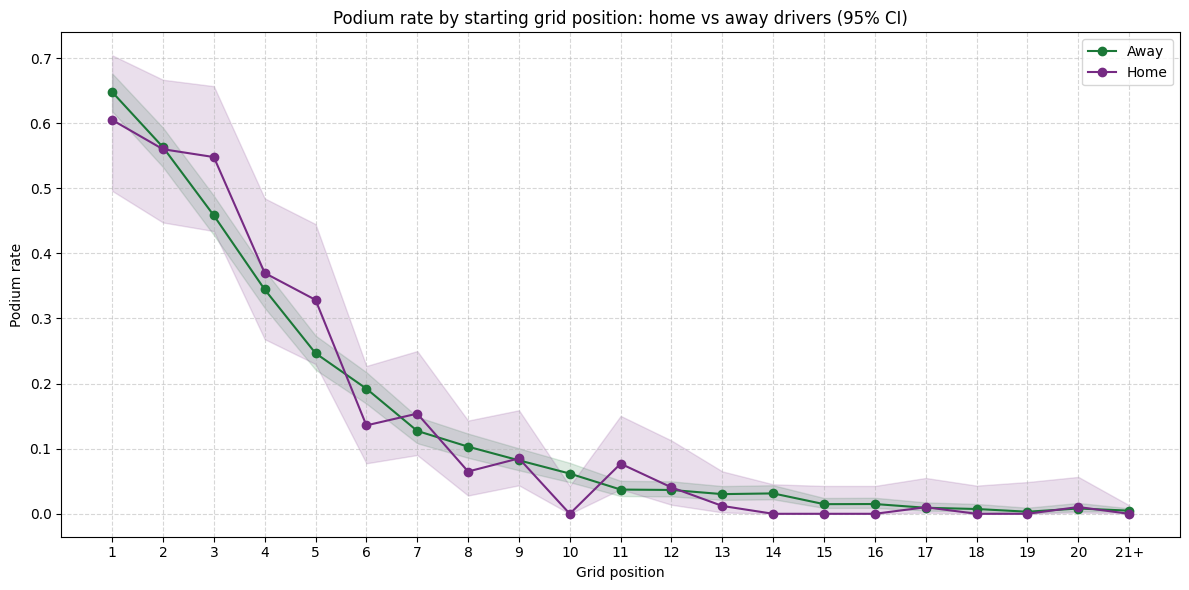


Benchmark - away drivers' podium rate by grid slot:
  1: 64.8%, 2: 56.3%, 3: 45.8%, 4: 34.5%, 5: 24.7%, 6: 19.2%, 7: 12.7%, 8: 10.3%, 9: 8.2%, 10: 6.2%, 11: 3.7%, 12: 3.7%, 13: 3.0%, 14: 3.1%, 15: 1.5%, 16: 1.5%, 17: 0.9%, 18: 0.7%, 19: 0.3%, 20: 0.8%, 21+: 0.5%

All home entries: 230 actual podiums vs 234.7 expected from their grid slots (1932 entries)

Tracks with >= 10 races involving home drivers: 22
                                       races  home_entries  actual  expected  actual / expected  p (chance)
circuit_name                                                                                               
Silverstone Circuit                       59           307      50      44.1               1.13       0.259
Autodromo Nazionale di Monza              62           258      20      22.8               0.88       0.533
Autodromo Enzo e Dino Ferrari             29           136      10       9.9               1.01       1.000
Nürburgring                               36       

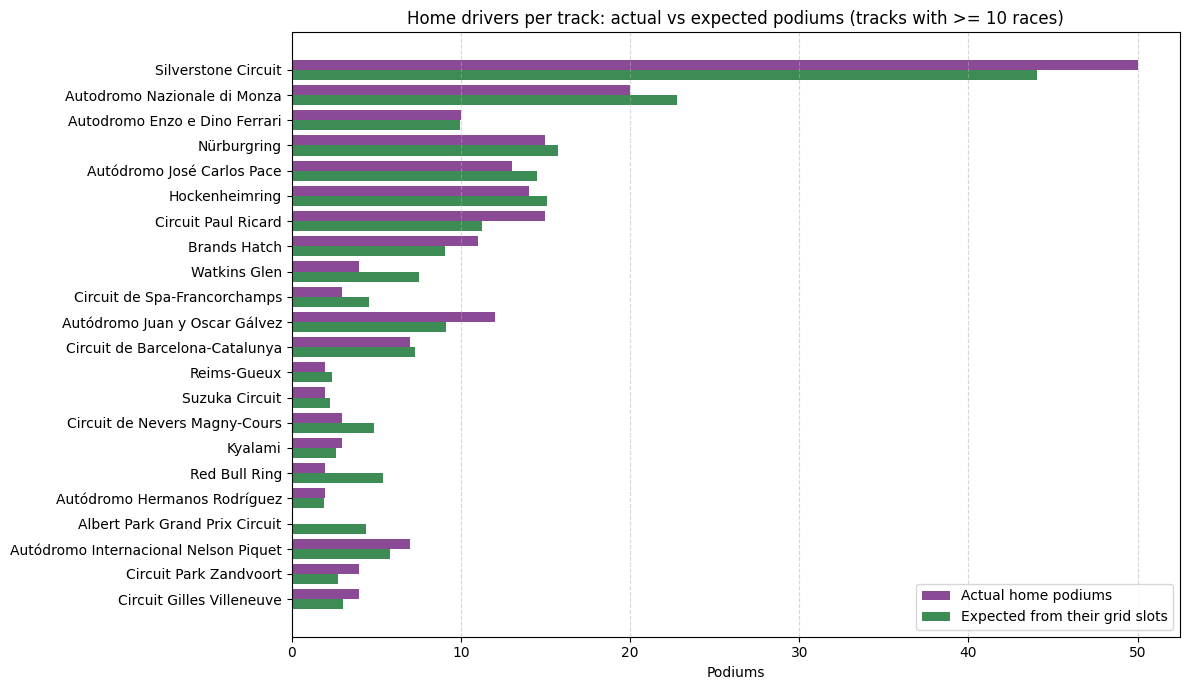

In [13]:
# Q2 Implementation: Home Race Advantage (controlled for starting position)
# Home race = the driver's nationality maps to the circuit's country (demonym -> country mapping below).
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

# 1. Define demonym -> country mapping (covers all nationalities in drivers.csv)
nationality_to_country = {
    # UK variants
    'British': 'UK', 'English': 'UK', 'Scottish': 'UK', 'Welsh': 'UK',
    # Germany variants
    'German': 'Germany', 'East German': 'Germany', 'West German': 'Germany',
    # Direct mappings
    'Italian': 'Italy',
    'French': 'France',
    'Spanish': 'Spain',
    'Brazilian': 'Brazil',
    'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Argentine-Italian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'Finnish': 'Finland',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Irish': 'Ireland',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'American': 'USA', 'American-Italian': 'USA',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela',
    'Chinese': 'China',
    'Indonesian': 'Indonesia',
    'Korean': 'Korea',  # circuits.csv spells it 'Korea'
}

# 2. Apply mapping (.str.strip() handles trailing spaces such as 'Argentinian ')
q2_df = df_master_final.copy()
q2_df['nationality_clean'] = q2_df['nationality'].astype(str).str.strip()
q2_df['driver_country'] = q2_df['nationality_clean'].map(nationality_to_country)
q2_df['circuit_country'] = q2_df['circuit_country'].replace({'United States': 'USA'})  # circuits use both spellings
q2_df['is_home_race'] = q2_df['driver_country'] == q2_df['circuit_country']

all_nationalities = df_master_final['nationality'].unique()
unmapped = [n for n in all_nationalities if n.strip() not in nationality_to_country]
print(f"Total nationalities: {len(all_nationalities)}, unmapped: {unmapped}")
direct = set(df_master_final['nationality'].str.strip()) & set(df_master_final['circuit_country'])
print(f"Nationalities equal to a circuit country without the mapping: {len(direct)} (so a mapping is needed)")
print(f"Home-race entries (all rows): {q2_df['is_home_race'].sum()} / {len(q2_df)} ({q2_df['is_home_race'].mean():.2%})")
assert q2_df['is_home_race'].sum() > 0, "Nationality mapping failed - no home races detected!"

# 3. Exclude the Indianapolis 500 (1950-1960): it counted for the championship but was effectively a separate
#    American event entered almost only by American drivers, so nearly every entry would count as a home race
indy = q2_df['race_name'] == 'Indianapolis 500'
print(f"Indianapolis 500 entries removed: {indy.sum()} ({q2_df.loc[indy, 'is_home_race'].sum()} of them home-race entries)")
q2_df = q2_df[~indy]

# 4. Keep entries with a grid slot that took the start (grid = 0 means a non-starter or a pit-lane start)
no_start = (q2_df['grid'] >= 1) & ~took_the_start(q2_df)
print(f"Entries with a grid slot that never took the start (removed): {no_start.sum()}")
q2_df = q2_df[(q2_df['grid'] >= 1) & took_the_start(q2_df)].copy()
q2_df['is_podium'] = (q2_df['positionOrder'] <= 3).astype(int)
home = q2_df['is_home_race']
print(f"Analysed: {len(q2_df)} entries, of which {home.sum()} home-race entries ({home.mean():.2%})")

# 5. Uncontrolled comparison: do home drivers start from different grid positions?
print(f"\nRaw podium rate - Home: {q2_df.loc[home, 'is_podium'].mean():.1%}, Away: {q2_df.loc[~home, 'is_podium'].mean():.1%}")
print(f"Mean grid position - Home: {q2_df.loc[home, 'grid'].mean():.2f}, Away: {q2_df.loc[~home, 'grid'].mean():.2f}")
career_starts = q2_df.groupby('driverId').size()
few_starts = q2_df['driverId'].map(career_starts) < 10
print(f"Entries by drivers with fewer than 10 career starts - Home: {few_starts[home].mean():.1%}, Away: {few_starts[~home].mean():.1%}")

# 6. Controlled comparison: home vs away drivers who started from the SAME grid position (21+ grouped),
#    combined into one answer with a Cochran-Mantel-Haenszel test
q2_df['grid_slot'] = q2_df['grid'].clip(upper=21).astype(int)
tables = []
for _, slot_df in q2_df.groupby('grid_slot'):
    t = pd.crosstab(slot_df['is_home_race'], slot_df['is_podium']).reindex(index=[True, False], columns=[1, 0], fill_value=0).values
    if (t.sum(axis=1) > 0).all():  # the slot needs both home and away drivers to be compared
        tables.append(t)
cmh = StratifiedTable(tables)
odds_ratio, p_value = cmh.oddsratio_pooled, cmh.test_null_odds().pvalue
or_low, or_high = cmh.oddsratio_pooled_confint()
print(f"\nControlled for grid position ({len(tables)} grid slots compared):")
print(f"  Pooled odds ratio, home vs away = {odds_ratio:.2f} (95% CI {or_low:.2f}-{or_high:.2f}), p = {p_value:.2f}")
print("  (1.0 = no difference; above 1 = home drivers podium more often than away drivers starting from the same slot)")

# 7. Descriptive view by grid bucket (no separate tests: the single test above is the answer)
def get_grid_bucket(grid):
    if grid <= 5: return '1-5'
    elif grid <= 10: return '6-10'
    elif grid <= 20: return '11-20'
    else: return '21+'

q2_df['grid_bucket'] = q2_df['grid'].apply(get_grid_bucket)
summary = (q2_df.groupby(['grid_bucket', 'is_home_race'])['is_podium'].agg(['mean', 'size'])
           .unstack('is_home_race').reindex(['1-5', '6-10', '11-20', '21+']))
summary = pd.DataFrame({'Home rate': summary[('mean', True)].map('{:.1%}'.format),
                        'Home n': summary[('size', True)],
                        'Away rate': summary[('mean', False)].map('{:.1%}'.format),
                        'Away n': summary[('size', False)]})
print("\nPodium rate by grid bucket:")
print(summary.to_string())

# 8. Visualisation: podium rate by grid position, home vs away
rates = q2_df.groupby(['grid_slot', 'is_home_race'])['is_podium'].agg(['sum', 'size']).reset_index()
rates['rate'] = rates['sum'] / rates['size']
rates['ci_low'], rates['ci_high'] = proportion_confint(rates['sum'], rates['size'], method='wilson')
fig, ax = plt.subplots(figsize=(12, 6))
for is_home, label, color in [(False, 'Away', '#1B7837'), (True, 'Home', '#762A83')]:
    d = rates[rates['is_home_race'] == is_home]
    ax.plot(d['grid_slot'], d['rate'], marker='o', label=label, color=color)
    ax.fill_between(d['grid_slot'], d['ci_low'], d['ci_high'], color=color, alpha=0.15)
ax.set_xticks(range(1, 22))
ax.set_xticklabels([str(i) for i in range(1, 21)] + ['21+'])
ax.set_xlabel('Grid position')
ax.set_ylabel('Podium rate')
ax.set_title('Podium rate by starting grid position: home vs away drivers (95% CI)')
ax.legend()
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 9. Per-track view: actual vs expected podiums for home drivers.
#    Expected chance for each home entry = podium rate of AWAY drivers who started from the same grid slot
#    (pooled over all tracks and years, because per-track samples are too small for their own benchmark).
MIN_HOME_RACES = 10  # a track needs >= 10 races with at least one home driver to be listed
away_rate_by_slot = q2_df[~home].groupby('grid_slot')['is_podium'].mean()
print("\nBenchmark - away drivers' podium rate by grid slot:")
print('  ' + ', '.join(f"{'21+' if s == 21 else s}: {r:.1%}" for s, r in away_rate_by_slot.items()))

home_entries = q2_df[home].copy()
home_entries['expected'] = home_entries['grid_slot'].map(away_rate_by_slot)
print(f"\nAll home entries: {int(home_entries['is_podium'].sum())} actual podiums vs "
      f"{home_entries['expected'].sum():.1f} expected from their grid slots ({len(home_entries)} entries)")

track = home_entries.groupby('circuit_name').agg(races=('raceId', 'nunique'), home_entries=('is_podium', 'size'),
                                                 actual=('is_podium', 'sum'), expected=('expected', 'sum'))
track = track[track['races'] >= MIN_HOME_RACES].sort_values('home_entries', ascending=False, kind='stable')  # fixed order: the simulation below draws track by track
track['actual / expected'] = track['actual'] / track['expected']

# Chance check by simulation: if being at home made no difference, each home entry gets a podium with its
# expected chance. Simulate that 10,000 times per track and count how often luck alone lands at least as far
# from expected as the actual result (two-sided p-value).
rng = np.random.default_rng(42)
def chance_p(chances, actual, n_sims=10_000):
    sims = (rng.random((n_sims, len(chances))) < chances).sum(axis=1)
    return np.mean(np.abs(sims - chances.sum()) >= abs(actual - chances.sum()))
track['p (chance)'] = [chance_p(home_entries.loc[home_entries['circuit_name'] == c, 'expected'].to_numpy(), a)
                       for c, a in zip(track.index, track['actual'])]
print(f"\nTracks with >= {MIN_HOME_RACES} races involving home drivers: {len(track)}")
print(track.assign(expected=track['expected'].round(1), **{'actual / expected': track['actual / expected'].round(2),
                                                            'p (chance)': track['p (chance)'].round(3)}).to_string())
print(f"Tracks with p < 0.05: {(track['p (chance)'] < 0.05).sum()} of {len(track)} "
      f"(about {0.05 * len(track):.1f} would be expected by luck alone)")

fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(track))[::-1]
ax.barh(y + 0.2, track['actual'], 0.4, label='Actual home podiums', color='#762A83', alpha=0.85)
ax.barh(y - 0.2, track['expected'], 0.4, label='Expected from their grid slots', color='#1B7837', alpha=0.85)
ax.set_yticks(y)
ax.set_yticklabels(track.index)
ax.set_xlabel('Podiums')
ax.set_title(f'Home drivers per track: actual vs expected podiums (tracks with >= {MIN_HOME_RACES} races)')
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**[OBSERVATION]:** **No, there is no evidence of a home-race advantage once starting position is taken into account, overall or at any single track.**
- **Data used:** 24,571 entries with a grid slot, 1,932 of them home-race entries (7.9%). This is after removing the 381 Indianapolis 500 entries (380 of which were American drivers at an American race) and 81 entries that held a grid slot but never took the start.
- **Why a mapping is needed:** no nationality is spelled like a circuit country (0 direct matches, printed above), so `nationality_to_country` maps all 43 nationalities first.
- **Raw comparison:** home drivers actually podium *less* often (11.9% vs 13.8%) and start *further back* on average (grid 12.69 vs 11.70). A large part of this comes from one-off local entries at home races. 17.0% of home entries come from drivers with fewer than 10 career starts, against 2.9% of away entries. This is exactly why the comparison has to be made between drivers who started from the same position.
- **Controlled comparison:** comparing home and away drivers grid slot by grid slot and combining the 21 slots, the pooled odds ratio is **0.97** (95% CI 0.81–1.15, p = 0.71). A value of 1.0 would mean no difference. The interval includes 1.0, so there is no evidence that home and away drivers who start from the same position podium at different rates. The interval also rules out a large effect in either direction, although no test can prove an effect is exactly zero. The line chart shows the two lines on top of each other at every grid position.
- **By bucket (descriptive):** grid 1–5: home 48.7% vs away 45.2%. Grid 6–10: 8.7% vs 11.3%. Grid 11–20: 1.5% vs 2.0%. Grid 21+: 0.0% vs 0.5%. The small differences go in both directions.

**Per track: actual vs expected home podiums**
- **What "expected" means:** for each home-driver entry at a track, we take their starting grid slot and look up how often *away* drivers starting from that same slot finished on the podium (the printed benchmark). That share is the entry's expected chance of a podium. Example: a British driver starting 3rd at Silverstone adds 0.458 to Silverstone's expected count, because away drivers starting 3rd reach the podium 45.8% of the time. Adding these chances over all home entries at a track gives the number of podiums home drivers would be expected to score *if being at home made no difference*. Actual above expected means home drivers did better than their starting positions suggest.
- **Is the gap just luck?** For each track we simulated the "no home effect" scenario 10,000 times: every home entry gets a podium with its expected chance. The p-value is the share of simulations that land at least as far from expected as the real result. A small p-value means luck alone rarely produces such a gap.
- **Results:** across all 1,932 home entries, home drivers scored **230 podiums vs 234.7 expected**, almost exactly what their starting positions predict. Of the 22 tracks with at least 10 races involving home drivers, the biggest gaps apart from Albert Park (below) are Silverstone (50 vs 44.1, p = 0.26), Paul Ricard (15 vs 11.2, p = 0.17), Watkins Glen (4 vs 7.5, p = 0.11) and Red Bull Ring (2 vs 5.4, p = 0.058). Only one track falls below p = 0.05: Albert Park, where Australian drivers scored **0 home podiums against 4.4 expected** (p = 0.013). With 22 tracks checked, about one such result (1.1) is expected from luck alone.
- **Reading this correctly:** the per-track numbers are interesting individual findings (e.g. Australian drivers' empty record in Melbourne), but they are what chance variation looks like across 22 tracks. They agree with the overall result: there is no evidence that racing at home helps drivers reach the podium.
- **Limits:** the benchmark is pooled across all tracks and years, because per-track samples are too small for their own benchmark. Simulation p-values use a fixed random seed (42), so they are reproducible.

### Question 3: Mechanical Retirement Rate (Era Comparison)

**[GOAL]:** Find which constructors have the highest mechanical-retirement rate in 2014–2021 and in 2022–2024, and compare the two eras. A mechanical retirement is a race start that ended early because a component of the car failed. It excludes crashes, driver errors and regulation decisions.

**[LOGIC]:**
1. Join `results` → `status` (race-ending reason), `races` (year) and `constructors` (team name).
2. Classify **every** race-ending reason that occurs in 2014–2024 as *Mechanical*, *Not mechanical* or *Did not start*. The full table, with counts, is printed below, so the classification can be checked reason by reason. Classified finishers ("Finished", "+1 Lap", ...) are not retirements.
3. Borderline reasons were decided on evidence:
   - **"Wheel" and "Tyre" were checked case by case** (table below). Most were pit-stop errors or debris, so both reasons count as *not mechanical*. The two cases that were real part failures (both suspension) count as mechanical.
   - "Wheel nut" (pit-stop error), "Puncture" (debris/contact), "Out of fuel" (fuel planning), "Seat" (unclear single case) and "Retired" (no reason recorded) count as *not mechanical*.
   - "Front wing" and "Rear wing" count as *mechanical*: crash damage is recorded separately as "Collision damage".
4. Denominator = race starts, using the shared rule `took_the_start` (Section 4). "Withdrew" entries that completed no laps never started, so they are removed. The few that completed laps did start and were retired during the race: they are relabelled "Withdrew during the race" and count as *not mechanical*, because no reason is recorded (the same as "Retired").
5. Teams that raced under different names are merged (e.g. Toro Rosso → AlphaTauri → RB; Lotus F1 → Renault → Alpine); the merge is printed.
6. Rate per team and era = mechanical retirements ÷ race starts, with a 95% Wilson confidence interval. A team needs at least 20 starts in an era to be ranked. Every team is ranked within its own era, so teams that only raced in one era (e.g. Caterham) are not hidden.
7. Show the top 5 for each era, and a **top 5 across both eras**: the team-era rates from the two era tables sorted together, not a recalculation over 2014–2024.
8. Test whether each team's rate changed between eras (Fisher's exact test, with a Holm correction because many teams are tested at once), and whether the overall rate changed (two-proportion z-test).
9. Borderline check: re-run with the borderline reasons classified the other way, to see whether the top 5s change.

**Checked "Wheel" and "Tyre" retirements (2014–2024)**

| Race | Driver | Recorded as | What happened | Counted as |
|---|---|---|---|---|
| Australia 2015 | Räikkönen | Wheel | Rear wheel not fastened at the pit stop ([F1](https://www.formula1.com/en/latest/features/2015/3/winners-and-losers---the-australian-grand-prix.html)) | Not mechanical |
| USA 2016 | Räikkönen | Wheel | Released with the wheel gun attached, wheel not secure ([Eurosport](https://www.eurosport.com/formula-1/ferrari-fined-for-raikkonen-unsafe-release_sto5924179/story.shtml)) | Not mechanical |
| Japan 2017 | Stroll | Wheel | Front-right suspension failure ([FIA](https://www.fia.com/news/f1-hamilton-holds-verstappen-win-japan-vettel-forced-retire)) | **Mechanical** |
| Abu Dhabi 2017 | Sainz | Wheel | Front-left wheel not secured at the pit stop ([Sainz](https://carlossainz.es/en/carlos-sainz-retires-from-the-abu-dhabi-gp-after-an-issue-in-pits.html)) | Not mechanical |
| Australia 2018 | Grosjean | Wheel | Wheel nut cross-threaded at the pit stop ([Crash](https://crash.net/f1/news/892445/1/haas-explains-cause-unbelievable-double-pit-stop-failure)) | Not mechanical |
| Australia 2018 | Magnussen | Wheel | Wheel nut cross-threaded at the pit stop ([ESPN](https://africa.espn.com/f1/story/_/id/22905101/heartbreaking-haas-retirements-human-error)) | Not mechanical |
| Bahrain 2018 | Räikkönen | Wheel | Released before the tyre change was finished ([F1](https://www.formula1.com/en/latest/headlines/2018/4/ferrari-explain-pit-stop-error-that-led-to-mechanic-injury.html)) | Not mechanical |
| France 2018 | Alonso | Wheel | Suspension part broke ([motor.es](https://www.motor.es/formula-1/tercer-abandono-consecutivo-alonso-f1-venia-rueda-mirando-cuenca-201847747.html)) | **Mechanical** |
| Australia 2019 | Grosjean | Wheel | Wheel nut damaged while forcing the wheel on at the pit stop ([Motorsport](https://www.motorsport.com/f1/news/haas-grosjean-wheelnut-damaged-australia/4354724/)) | Not mechanical |
| Italy 2019 | Sainz | Wheel | Front-right wheel not tightened at the pit stop ([F1](https://www.formula1.com/en/latest/article/sainz-ready-to-bounce-back-after-intense-italian-gp-pit-stop.1Q3kRdBHL7IDlNA9FFnVUI)) | Not mechanical |
| Austria 2020 | Räikkönen | Wheel | Wheel nut cross-threaded at the pit stop ([F1](https://www.formula1.com/en/latest/article/watch-sparks-fly-as-raikkonen-loses-a-wheel-late-in-austrian-gp.Bb7FF7uci9HvwolR4bwG5)) | Not mechanical |
| Belgium 2015 | Vettel | Tyre | Debris cut on a worn tyre, no structural fault (Pirelli) ([F1](https://www.formula1.com/en/latest/headlines/2015/9/findings-of-pirellis-vettel-tyre-investigation-revealed.html)) | Not mechanical |
| Singapore 2015 | Grosjean | Tyre | Parked as a precaution (gearbox concerns), nothing failed ([Lotus](https://www.lotusdriversguide.com/Press/Lotus_F1_Team_Singapore_2015.php)) | Not mechanical |
| Austria 2016 | Vettel | Tyre | Debris, no structural fault (Pirelli) ([Tyrepress](https://tyrepress.com/2016/07/pirelli-on-vettel-tyre-failure-no-signs-of-fatigue-or-structural-failure)) | Not mechanical |
| Britain 2018 | Leclerc | Tyre | Front wheel not fitted properly at the pit stop ([F1](https://www.formula1.com/en/latest/article/leclerc-very-happy-with-sauber-progress-despite-hungary-disappointment.6gFtjPvj1eiKo46AQkesqw)) | Not mechanical |

**[GRAIN / MISSINGNESS / CUTOFF]:** One row per driver per race start. Every 2014–2024 entry has a recorded status; the code stops if any race-ending reason is left unclassified. "Retired" entries have no recorded reason and cannot be classified as mechanical, so they are a known limitation (the count is printed). This is a historical, post-race analysis, so the pre-race cutoff does not apply.

=== EVERY RACE-ENDING REASON IN 2014-2024 (58 reasons, 801 entries) ===
era                             category                                                   why  2014-2021  2022-2024  total
status_description                                                                                                         
Withdrew                   Did not start                                         never started          7          4     11
Engine                        Mechanical                                 car component failure         59         22     81
Brakes                        Mechanical                                 car component failure         45          4     49
Gearbox                       Mechanical                                 car component failure         33          9     42
Power Unit                    Mechanical                                 car component failure         35          7     42
Suspension                    Mechanical                    

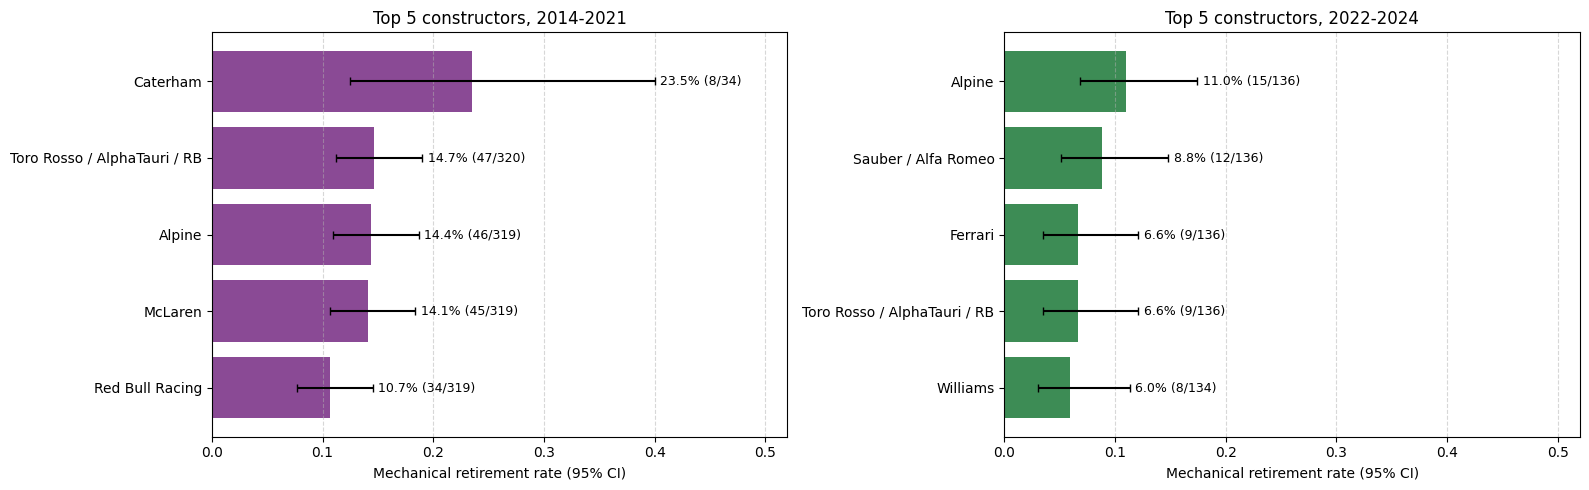

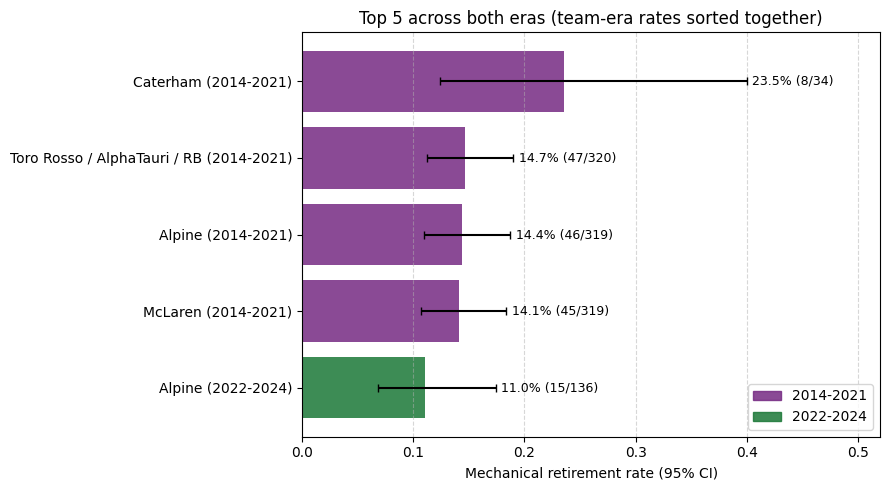

In [14]:
# Q3 Implementation: Mechanical Retirement Rate by Constructor (2014-2021 vs 2022-2024)
# Mechanical retirement = a race start that ended because a car component failed
# (not crashes, driver errors, pit-stop errors or regulation decisions).
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact

ERAS = ['2014-2021', '2022-2024']
MIN_STARTS = 20  # a constructor needs >= 20 starts in an era to be ranked

# 1. Classify every race-ending reason (status) that occurs in 2014-2024
MECHANICAL = [
    # Power unit & electrics
    'Engine', 'Power Unit', 'Power loss', 'Turbo', 'ERS', 'Battery', 'Electrical', 'Electronics', 'Spark plugs',
    # Transmission
    'Gearbox', 'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential',
    # Brakes, suspension, steering, bodywork
    'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Undertray', 'Front wing', 'Rear wing',
    # Fluids, fuel & cooling
    'Hydraulics', 'Oil leak', 'Oil pressure', 'Water pressure', 'Water leak', 'Water pump', 'Overheating',
    'Radiator', 'Cooling system', 'Fuel pressure', 'Fuel leak', 'Fuel system', 'Fuel pump', 'Exhaust', 'Throttle',
    # Generic failure labels
    'Mechanical', 'Technical', 'Vibrations',
]
NOT_MECHANICAL = {
    'Collision': 'crash or contact', 'Accident': 'crash or contact', 'Collision damage': 'crash or contact',
    'Damage': 'crash or contact', 'Spun off': 'driver error', 'Debris': 'debris on track',
    'Puncture': 'debris or contact', 'Disqualified': 'regulation decision', 'Excluded': 'regulation decision',
    'Illness': 'driver health', 'Wheel': 'checked case by case: mostly pit-stop errors',
    'Wheel nut': 'pit-stop error', 'Tyre': 'checked case by case: debris, pit stop or precaution',
    'Out of fuel': 'fuel planning, not a part failure', 'Seat': 'unclear, single case',
    'Retired': 'no reason recorded', 'Withdrew during the race': 'started, then retired; no reason recorded',
}
DID_NOT_START = {'Withdrew', 'Did not qualify', 'Did not prequalify', '107% Rule'}
# 'Wheel' retirements that were checked and turned out to be real part failures (sources in the markdown above)
MECHANICAL_EXCEPTIONS = [(2017, 'Japanese Grand Prix', 'stroll'), (2018, 'French Grand Prix', 'alonso')]

q3_df = df_master_final[df_master_final['year'].between(2014, 2024)].copy()
# 'Withdrew' after completing laps = the car started and was retired during the race (no reason recorded)
q3_df.loc[(q3_df['status_description'] == 'Withdrew') & took_the_start(q3_df), 'status_description'] = 'Withdrew during the race'
q3_df['era'] = np.where(q3_df['year'] <= 2021, '2014-2021', '2022-2024')
status = q3_df['status_description']
finished = status.str.match(r'^(Finished|\+\d+ Laps?)$')  # classified finishers, including laps down
unclassified = set(status[~finished]) - set(MECHANICAL) - set(NOT_MECHANICAL) - DID_NOT_START
assert not unclassified, f"Unclassified statuses: {unclassified}"

q3_df['category'] = np.select([finished, status.isin(MECHANICAL), status.isin(DID_NOT_START)],
                              ['Finished', 'Mechanical', 'Did not start'], default='Not mechanical')
for year, race, driver in MECHANICAL_EXCEPTIONS:
    hit = (q3_df['year'] == year) & (q3_df['race_name'] == race) & (q3_df['driverRef'] == driver)
    assert hit.sum() == 1, f"Exception not found exactly once: {year} {race} {driver}"
    q3_df.loc[hit, 'category'] = 'Mechanical'

non_finish = q3_df[q3_df['category'] != 'Finished']
class_table = non_finish.groupby(['status_description', 'era']).size().unstack(fill_value=0)
class_table['total'] = class_table.sum(axis=1)
class_table['category'] = ['Mechanical' if s in MECHANICAL else 'Did not start' if s in DID_NOT_START
                           else 'Not mechanical' for s in class_table.index]
class_table['why'] = [NOT_MECHANICAL.get(s, 'car component failure' if s in MECHANICAL else 'never started')
                      for s in class_table.index]
class_table = class_table.sort_values(['category', 'total'], ascending=[True, False])
print(f"=== EVERY RACE-ENDING REASON IN 2014-2024 ({len(class_table)} reasons, {len(non_finish)} entries) ===")
print(class_table[['category', 'why'] + ERAS + ['total']].to_string())
print("\nChecked 'Wheel' exceptions counted as mechanical: "
      + '; '.join(f"{d.capitalize()}, {r} {y}" for y, r, d in MECHANICAL_EXCEPTIONS))
print("\nEntries by category and era:")
print(q3_df.groupby(['category', 'era']).size().unstack(fill_value=0).to_string())

# 2. Merge constructors that raced under different names (same team, renamed)
TEAM_NAMES = {
    'Red Bull': 'Red Bull Racing',
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB', 'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB F1 Team': 'Toro Rosso / AlphaTauri / RB',
    'Lotus F1': 'Alpine', 'Renault': 'Alpine', 'Alpine F1 Team': 'Alpine',
    'Force India': 'Aston Martin', 'Racing Point': 'Aston Martin',
    'Sauber': 'Sauber / Alfa Romeo', 'Alfa Romeo': 'Sauber / Alfa Romeo',
    'Haas F1 Team': 'Haas',
    'Marussia': 'Marussia / Manor', 'Manor Marussia': 'Marussia / Manor',
}
q3_df['team'] = q3_df['constructor_name'].map(TEAM_NAMES).fillna(q3_df['constructor_name'])
print("\nConstructor names in the data -> team used here:")
for team, names in q3_df.groupby('team')['constructor_name'].unique().items():
    if len(names) > 1 or names[0] != team:
        print(f"  {team}: {', '.join(sorted(names))}")

# 3. Mechanical retirement rate per team and era = mechanical retirements / race starts
starts = q3_df[q3_df['category'] != 'Did not start'].copy()
starts['is_mech'] = starts['category'] == 'Mechanical'

def team_rates(is_mech):
    r = starts.assign(is_mech=is_mech).groupby(['era', 'team'])['is_mech'].agg(mech='sum', starts='size').reset_index()
    r['rate'] = r['mech'] / r['starts']
    r['ci_low'], r['ci_high'] = proportion_confint(r['mech'], r['starts'], method='wilson')
    return r[r['starts'] >= MIN_STARTS]

ranked = team_rates(starts['is_mech'])
overall = starts.groupby('era')['is_mech'].agg(mech='sum', starts='size')
overall_p = proportions_ztest(overall['mech'].to_numpy(), overall['starts'].to_numpy())[1]
print(f"\n=== OVERALL MECHANICAL RETIREMENT RATE (race starts only) ===")
for era in ERAS:
    print(f"  {era}: {overall.loc[era, 'mech']} / {overall.loc[era, 'starts']} = "
          f"{overall.loc[era, 'mech'] / overall.loc[era, 'starts']:.2%}")
print(f"  Difference between eras: two-proportion z-test p = {overall_p:.5f}")

def fmt(t):
    out = t.assign(rate=t['rate'].map('{:.1%}'.format),
                   **{'95% CI': [f"{lo:.1%} - {hi:.1%}" for lo, hi in zip(t['ci_low'], t['ci_high'])]})
    out = out[['team', 'mech', 'starts', 'rate', '95% CI']].reset_index(drop=True)
    out.index += 1
    return out

top5 = {}
for era in ERAS:
    t = ranked[ranked['era'] == era].sort_values('rate', ascending=False, kind='stable')  # ties stay alphabetical
    top5[era] = t.head(5)
    print(f"\n=== {era}: ALL CONSTRUCTORS RANKED (min {MIN_STARTS} starts) ===")
    print(fmt(t).to_string())

# 4. Top 5 across both eras: the team-era rates from the two tables above, sorted together (no recalculation)
combined = ranked.assign(team=ranked['team'] + ' (' + ranked['era'] + ')').sort_values('rate', ascending=False, kind='stable')
top5_combined = combined.head(5)
print("\n=== TOP 5 ACROSS BOTH ERAS (team-era rates sorted together) ===")
print(fmt(top5_combined).to_string())

# 5. Did each team's rate change between eras? Fisher's exact test, Holm correction for testing many teams
both = ranked.pivot(index='team', columns='era', values=['mech', 'starts', 'rate']).dropna()
p_raw = [fisher_exact([[int(r[('mech', a)]), int(r[('starts', a)] - r[('mech', a)])]
                       for a in ERAS])[1] for _, r in both.iterrows()]
change = pd.DataFrame({'2014-2021': both[('rate', '2014-2021')], '2022-2024': both[('rate', '2022-2024')]})
change['change (pp)'] = (change['2022-2024'] - change['2014-2021']) * 100
change['p'] = p_raw
change['p (Holm)'] = multipletests(p_raw, method='holm')[1]
change = change.sort_values('change (pp)')
print(f"\n=== CHANGE BETWEEN ERAS ({len(change)} teams in both eras) ===")
print(change.assign(**{e: change[e].map('{:.1%}'.format) for e in ERAS}).round(3).to_string())
sig = change.index[change['p (Holm)'] < 0.05].tolist()
sig_raw = change.index[(change['p'] < 0.05) & (change['p (Holm)'] >= 0.05)].tolist()
print(f"Significant after Holm correction: {sig if sig else 'none'}")
print(f"Significant only before correction: {sig_raw if sig_raw else 'none'}")

# 6. Borderline check: classify the borderline reasons the other way and see if the top 5s change
TO_MECH = ['Wheel', 'Wheel nut', 'Tyre', 'Puncture', 'Out of fuel', 'Seat']
TO_NOT = ['Front wing', 'Rear wing']
alt_is_mech = (starts['is_mech'] | starts['status_description'].isin(TO_MECH)) & ~starts['status_description'].isin(TO_NOT)
alt = team_rates(alt_is_mech)
alt_overall = starts.assign(m=alt_is_mech).groupby('era')['m'].mean()
print(f"\n=== BORDERLINE CHECK: {TO_MECH} counted as mechanical, {TO_NOT} as not ===")
print(f"  Overall: 2014-2021 {alt_overall['2014-2021']:.2%}, 2022-2024 {alt_overall['2022-2024']:.2%}")
for era in ERAS:
    alt_top = alt[alt['era'] == era].sort_values('rate', ascending=False, kind='stable').head(5)
    same = set(alt_top['team']) == set(top5[era]['team'])
    print(f"  {era} top 5: {', '.join(f'{t} {r:.1%}' for t, r in zip(alt_top['team'], alt_top['rate']))}"
          f"  -> same five teams as the main answer: {same}")

# 7. Visualisations
ERA_COLORS = {'2014-2021': '#762A83', '2022-2024': '#1B7837'}
xmax = max(top5[e]['ci_high'].max() for e in ERAS) + 0.12  # room for the labels right of the error bars

def hbars(ax, t, colors, title):
    t = t.iloc[::-1]
    ax.barh(t['team'], t['rate'], xerr=[t['rate'] - t['ci_low'], t['ci_high'] - t['rate']],
            color=colors, alpha=0.85, capsize=3)
    for y, (rate, mech, n, hi) in enumerate(zip(t['rate'], t['mech'], t['starts'], t['ci_high'])):
        ax.text(hi + 0.005, y, f"{rate:.1%} ({mech}/{n})", va='center', fontsize=9)
    ax.set_xlim(0, xmax)
    ax.set_xlabel('Mechanical retirement rate (95% CI)')
    ax.set_title(title)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, era in zip(axes, ERAS):
    hbars(ax, top5[era], ERA_COLORS[era], f'Top 5 constructors, {era}')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
hbars(ax, top5_combined, [ERA_COLORS[e] for e in top5_combined['era'].iloc[::-1]],
      'Top 5 across both eras (team-era rates sorted together)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.85) for c in ERA_COLORS.values()],
          labels=list(ERA_COLORS), loc='lower right')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Classification:** 58 race-ending reasons appear in 2014–2024 (801 non-finishing entries), counting "Withdrew during the race" as its own reason. The table above shows how each one was classified. 11 "Withdrew" entries never started and are removed from the race starts. The other 3 withdrew after completing laps: they started and were retired during the race, so they count as starts (not mechanical, as no reason is recorded). 50 "Retired" entries (38 in 2014–2021, 12 in 2022–2024) have no recorded reason, so they cannot be counted as mechanical; this is a known limitation.
- **Overall:** the mechanical retirement rate fell from **9.39%** (306 of 3,260 starts) in 2014–2021 to **6.13%** (83 of 1,355) in 2022–2024. The drop is statistically significant (two-proportion z-test, p = 0.00028): cars became more reliable.
- **Highest in 2014–2021:**
  1. Caterham, 23.5%
  2. Toro Rosso / AlphaTauri / RB, 14.7%
  3. Alpine, 14.4% (Lotus F1 / Renault / Alpine)
  4. McLaren, 14.1%
  5. Red Bull Racing, 10.7%

  Caterham's rate comes from only 34 starts, so its interval is very wide (12.4%–40.0%). Places 2–4 are within 0.6 percentage points of each other, effectively tied. Mercedes had the lowest rate (3.8%).
- **Highest in 2022–2024:**
  1. Alpine, 11.0%
  2. Sauber / Alfa Romeo, 8.8%
  3. Ferrari, 6.6% (tied with Toro Rosso / AlphaTauri / RB at 9 of 136 starts each)
  4. Toro Rosso / AlphaTauri / RB, 6.6%
  5. Williams, 6.0%

  McLaren and Red Bull Racing had the lowest rate (3.7%).
- **Top 5 across both eras:** four of the five entries are from 2014–2021 (Caterham, Toro Rosso / AlphaTauri / RB, Alpine, McLaren). The only 2022–2024 entry is Alpine at 11.0%, in 5th. The worst reliability records belong to the earlier era. Alpine and Toro Rosso / AlphaTauri / RB are in the top 5 of both eras.
- **Which teams really changed:** McLaren's drop from 14.1% to 3.7% is the only change that stays significant after correcting for testing 10 teams (p = 0.001, Holm-adjusted p = 0.009). Toro Rosso / AlphaTauri / RB (−8.1 points, p = 0.019) and Red Bull Racing (−7.0 points, p = 0.016) are significant on their own but not after the correction (Holm-adjusted p ≈ 0.15), so their improvement is suggestive rather than proven. The other teams' changes are small and go in both directions (e.g. Ferrari +1.3 points, Mercedes +0.7).
- **Borderline check:** counting Wheel, Wheel nut, Tyre, Puncture, Out of fuel and Seat as mechanical, and both wings as not mechanical, changes the overall rates only slightly (2014–2021: 9.39% → 10.03%; 2022–2024: 6.13% → 5.98%). The **same five teams** make up the top 5 of each era, so the answer does not depend on the borderline decisions.

## Section 6: Objective 3 - Feature Selection, Engineering and Data Split

**[GOAL]:** Build the table that every model in Objectives 4–6 uses: one row per driver per race, with the target (podium yes/no) and 19 features that are all known **after qualifying and before the race starts**. Then split it into training, validation and test seasons, and back every feature choice with evidence.

**[LOGIC]:** A feature is allowed only if it would really be available at prediction time. These are therefore **never** features (using them would be data leakage):
- the race's own result: finishing position, points, laps, time, status, fastest lap;
- the race's pit stops and lap times;
- the championship standings stored for the same race (they already include that race's points);
- any average that includes the race being predicted;
- any number learned from the validation or test seasons.

The section runs in order: 6.1 modelling table → 6.2 split → 6.3 features → 6.4 evidence → 6.5 filling blanks and rescaling → 6.6 experiments → 6.7 hand-off → 6.8 known limitations.

### 6.1 Modelling table

**[GOAL]:** Decide which rows the models learn from, and from which seasons.

**[LOGIC]:**
- **Rows:** one row per driver per race, taken from `df_master` (Section 4). It already has exactly one row per (raceId, driverId) after the duplicate resolution in 2.3.
- **Race starters only,** using the shared rule `took_the_start` from Section 4. Entries that did not qualify, did not pre-qualify, failed the 107% rule or withdrew before completing a lap are removed: they never take the start, so they can never finish on the podium. A driver recorded as "Withdrew" after completing laps did start (the car was retired during the race), so that row stays. A car that broke down on the way to the grid also stays: at the prediction moment it was expected to start, so its race counts as a non-podium, like an early retirement. The Indianapolis 500 (1950–1960) is removed for the same reason as in Q1 and Q2: it was effectively a separate American event.
- **Pit-lane starters are kept.** They do start the race (from the back), so they are real predictions.
- **Target:** `podium` = 1 if `positionOrder` ≤ 3, otherwise 0. `dnf` (did not finish) is also stored, but only to build the retirement-rate features from *earlier* races.
- **Seasons:** the models use 2003–2024. Earlier seasons stay in the table only as *history*: a driver's form at the start of 2003 needs their races from late 2002. The two outputs below show why 2003 is the starting point.

In [15]:
# 6.1 Modelling table: one row per driver per race (race starters only)
FIRST_YEAR = 2003  # from 2003 on, every race of every season has qualifying data (see the chart below)

is_starter = took_the_start(df_master)  # Section 4: drops entries that never took the start
not_indy = df_master['race_name'] != 'Indianapolis 500'  # separate American event, excluded as in Q1 and Q2
starts = df_master.loc[is_starter & not_indy, [
    'raceId', 'year', 'round', 'date', 'race_name', 'circuitId', 'circuit_country',
    'driverId', 'driverRef', 'dob', 'nationality', 'constructorId', 'constructor_name',
    'grid', 'positionOrder', 'status_description']].copy()
starts['podium'] = (starts['positionOrder'] <= 3).astype(int)  # the target
# did not finish = not classified as a finisher (same rule as Q3: 'Finished' or '+N Lap(s)' count as finished)
starts['dnf'] = (~starts['status_description'].str.match(r'^(Finished|\+\d+ Laps?)$')).astype(int)
starts = starts.sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)

modern = starts[starts['year'] >= FIRST_YEAR]
print(f"Race starters 1950-2024 (kept as history): {len(starts)} rows in {starts['raceId'].nunique()} races")
print(f"Modelling rows {FIRST_YEAR}-2024: {len(modern)} rows in {modern['raceId'].nunique()} races, "
      f"podium rate {modern['podium'].mean():.1%}")

Race starters 1950-2024 (kept as history): 24697 rows in 1114 races
Modelling rows 2003-2024: 8939 rows in 428 races, podium rate 14.4%


Share of races with qualifying data (%), 1990-2005:
year
1990      0.0
1991      0.0
1992      0.0
1993      0.0
1994     94.0
1995    100.0
1996     44.0
1997     59.0
1998     44.0
1999     19.0
2000     24.0
2001      6.0
2002     12.0
2003    100.0
2004    100.0
2005    100.0


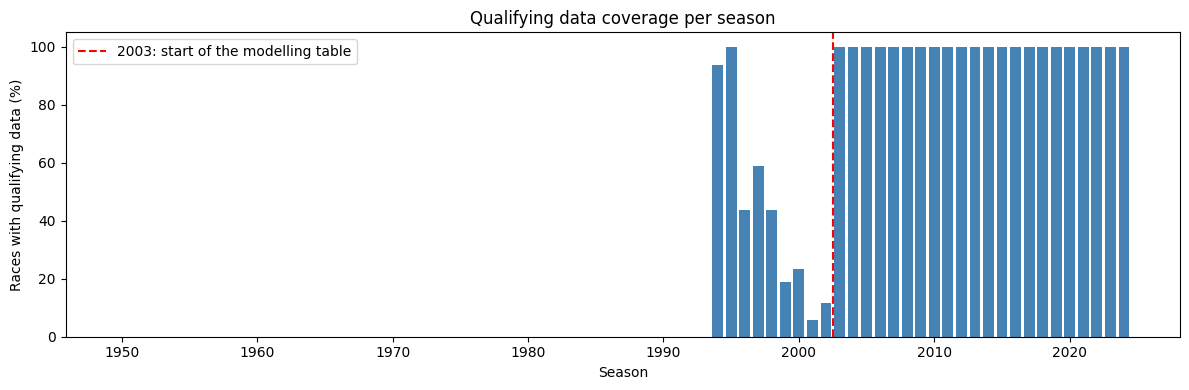


Podium chance (%) by starting grid slot and era:
era   1950-1979  1980-2002  2003-2019  2020-2021
grid                                            
1          52.2       57.5       80.3       74.4
2          49.0       52.2       62.7       74.4
3          38.4       48.0       51.6       59.0
4          34.8       36.9       31.9       28.2
5          30.2       26.0       20.9       15.4
6          21.9       20.9       15.6       10.3


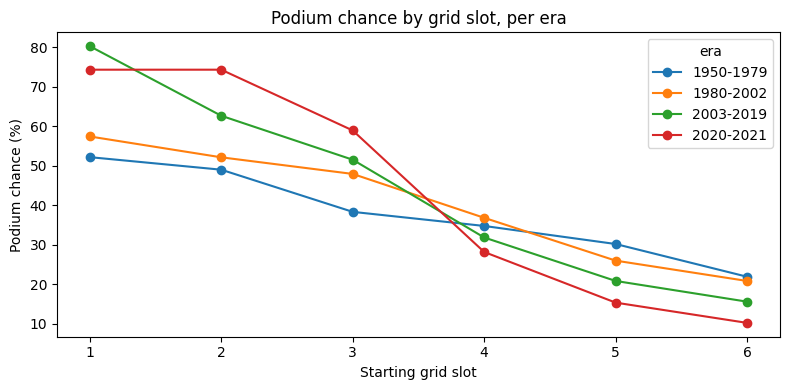

In [16]:
# 6.1 Why start in 2003: (a) qualifying data coverage, (b) how much a front-row start was worth in each era
race_list = starts.drop_duplicates('raceId')[['raceId', 'year']].copy()
race_list['has_qualifying'] = race_list['raceId'].isin(dfs_clean['qualifying']['raceId'])
coverage = race_list.groupby('year')['has_qualifying'].mean() * 100
print("Share of races with qualifying data (%), 1990-2005:")
print(coverage.loc[1990:2005].round(0).to_string())

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(coverage.index, coverage.values, color='steelblue')
ax.axvline(FIRST_YEAR - 0.5, color='red', linestyle='--', label=f'{FIRST_YEAR}: start of the modelling table')
ax.set_xlabel('Season')
ax.set_ylabel('Races with qualifying data (%)')
ax.set_title('Qualifying data coverage per season')
ax.legend()
plt.tight_layout()
plt.show()

# Podium chance from grid slots 1-6 per era (test seasons 2022-2024 left out)
ERA_EDGES = [1949, 1979, 2002, 2019, 2021]
ERA_NAMES = ['1950-1979', '1980-2002', '2003-2019', '2020-2021']
front = starts[starts['grid'].between(1, 6) & (starts['year'] <= 2021)].copy()
front['era'] = pd.cut(front['year'], bins=ERA_EDGES, labels=ERA_NAMES)
grid_by_era = front.pivot_table(index='grid', columns='era', values='podium', aggfunc='mean', observed=True) * 100
print("\nPodium chance (%) by starting grid slot and era:")
print(grid_by_era.round(1).to_string())

ax = grid_by_era.plot(marker='o', figsize=(8, 4))
ax.set_xlabel('Starting grid slot')
ax.set_ylabel('Podium chance (%)')
ax.set_title('Podium chance by grid slot, per era')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Rows:** 24,697 race starters in 1,114 races (1950–2024) are kept as history. The modelling rows are the **8,939 starters in 428 races from 2003 to 2024**; 14.4% of them finished on the podium.
- **Qualifying coverage:** the chart shows no qualifying data at all before 1994. From 1994 to 2002 coverage is patchy: 94–100% of races in 1994–1995, but only 6–59% in 1996–2002. **From 2003, every race has qualifying data.** Starting earlier would mean making up the qualifying features for most older rows.
- **Older eras behave differently:** starting from pole led to a podium 52.2% of the time in 1950–1979 and 57.5% in 1980–2002, against 80.3% in 2003–2019 and 74.4% in 2020–2021 (only 39 races). Grid slot 2 follows the same pattern: 49.0% and 52.2% before 2003, against 62.7% and 74.4% after. Q1 showed why: front-row starters failed to finish far more often in the older decades. Training on those eras would teach the model a weaker link between grid position and podium than modern F1 has.
- Whether adding older seasons would still help the model is tested directly in 6.6.

### 6.2 Split by season

**[GOAL]:** Split the modelling rows into training, validation and test sets, and justify the choice.

**[LOGIC]:** The split uses **whole seasons in time order**: train 2003–2019, validation 2020–2021, test 2022–2024. These are the boundaries the course introduction gives. Their cost is a small validation set: 2020 had only 17 races (a season shortened by COVID) and 2021 had 22 (printed below), so validation has 39 races, and its scores are noisier (the 95% intervals in 7.6 and 8.1 show how much). A random split of rows would be wrong here, for these reasons:
1. **Drivers in the same race compete against each other** (only three can finish on the podium), so one race must never be spread over two sets.
2. **No learning from the future.** A model trained on 2023 races and tested on 2010 races would use information that did not exist yet.
3. **It matches real use:** the model is meant to predict upcoming races from past seasons.
4. **Each set has one job.** Training seasons fit the models and provide all feature evidence. Validation seasons are used for every choice and comparison. No choice is made from the test seasons: they give the final scores in Objective 4 (7.6–7.7), and later sections show them only as a check or as examples.
5. **The test set is the current car rules.** 2022–2024 is the era of the 2022 regulations, so the final score shows how well the model does on the most recent F1.

In [17]:
# 6.2 Split by whole seasons: train 2003-2019, validation 2020-2021, test 2022-2024 (the course introduction's boundaries)
def split_name(year):
    if year < FIRST_YEAR:
        return 'history only'  # used only to compute form for later races (and the older-years test in 6.6)
    if year <= 2019:
        return 'train'
    if year <= 2021:
        return 'validation'
    return 'test'


starts['split'] = starts['year'].apply(split_name)

sizes = (starts[starts['year'] >= FIRST_YEAR].groupby('split', sort=False)
         .agg(seasons=('year', lambda y: f"{y.min()}-{y.max()}"), rows=('raceId', 'size'),
              races=('raceId', 'nunique'), podium_rate=('podium', 'mean')))
print(sizes.round(3).to_string())
print("Validation races per season:", starts[starts['split'] == 'validation'].groupby('year')['raceId'].nunique().to_dict())

# Check: no race is split between two sets (all drivers of one race stay together)
assert starts.groupby('raceId')['split'].nunique().max() == 1
print("Check passed: every race belongs to exactly one split")

              seasons  rows  races  podium_rate
split                                          
train       2003-2019  6804    321        0.142
validation  2020-2021   780     39        0.150
test        2022-2024  1355     68        0.151
Validation races per season: {2020: 17, 2021: 22}
Check passed: every race belongs to exactly one split


**[OBSERVATION]:**
- **Training (2003–2019):** 6,804 rows in 321 races, podium rate 14.2%.
- **Validation (2020–2021):** 780 rows in 39 races, podium rate 15.0%.
- **Test (2022–2024):** 1,355 rows in 68 races, podium rate 15.1%.

The podium rate is similar in all three sets, so they are comparable: a score difference between them will not come from a different share of podium finishers. The check confirms that every race belongs to exactly one set.


### 6.3 Features

**[GOAL]:** Build 19 features in six groups, each one known before the race starts. The groups are also the feature groups for the ablation in Objective 5; grid and qualifying are kept apart, as in the spec's own example.

| Group | Feature | Meaning | Why it is known before the race |
|---|---|---|---|
| Grid | `grid_pos` | Starting position; a pit-lane start counts as the back of the field | The starting grid is published before the start |
| Grid | `pit_lane_start` | 1 if the driver starts from the pit lane | Same |
| Qualifying | `quali_pos` | Qualifying position | Qualifying happens before the race |
| Qualifying | `quali_gap_pct` | How much slower (%) the driver's best qualifying lap was than the fastest one, capped at 7% | Same |
| Standings | `drv_points_share` | Driver's championship points ÷ the leader's points (1 = leading) | From the standings after the **previous** race |
| Standings | `drv_champ_pos` | Driver's championship position | Same |
| Standings | `team_points_share` | Team's points ÷ the leading team's points | Same |
| Standings | `team_champ_pos` | Team's championship position | Same |
| Standings | `first_race_of_season` | 1 at round 1, where the standings are last season's final standings | Known from the calendar |
| Driver form | `drv_form_podium_rate` | Share of podiums in the driver's last N races | Earlier races only |
| Driver form | `drv_form_avg_finish` | Average finishing position in the last N races | Same |
| Driver form | `drv_form_dnf_rate` | Share of the last N races the driver did not finish | Same |
| Driver form | `is_rookie` | 1 for a driver's first race (no form exists yet) | Known from the driver's history |
| Team form | `team_form_podiums_per_race` | Podiums per race in the team's last N races | Earlier races only |
| Team form | `team_form_avg_best_finish` | Average finish of the team's best car in the last N races | Same |
| Team form | `team_form_dnf_rate` | Share of the team's cars that did not finish in the last N races | Same |
| Extras | `career_starts` | Number of races the driver started before this one | Earlier races only |
| Extras | `circuit_podium_rate` | Driver's podium rate in all earlier visits to this circuit | Same |
| Extras | `first_visit_circuit` | 1 if the driver has never raced at this circuit before | Known from the driver's history |

**[LOGIC]:** How "earlier races only" is guaranteed:
- **Form averages:** `past_average` first moves every value down by one race (`shift(1)`), so a row only sees the races before it, and then averages the last N of them. A driver's first race therefore has no form (blank); the checks below test this. N starts at 5 here; 6.4 compares 3, 5 and 10 and keeps the best.
- **Standings:** the standings stored for a race already include that race's points (worked example 2 below), so every standings feature comes from the race before it on the calendar. For round 1 that is last season's final standings, which is what `first_race_of_season` flags. A driver or team with no standing yet (a newcomer or a stand-in) gets points share 0 and a position behind everyone in that race who has one.
- **Renamed teams start a new history.** A team that changes its name gets a new `constructorId` (e.g. Toro Rosso → AlphaTauri in 2020). Team form and team standings follow `constructorId`, as the course introduction asks, so after a rename the team has no team form for its first race (filled in 6.5) and, at round 1, no standing from last season (points share 0, placed behind everyone with a standing). The data also reuses a few ids decades apart (for example Mercedes in 1955 and again from 2010), so an id that comes back after more than a season away starts a new history as well. Q3 merges renamed teams on purpose, because it compares a team across two eras; the model does not.
- **The 7% cap:** a few qualifying gaps are extreme. The 107% rule, used in 1996–2002 and again since 2011, normally stops a car more than 7% slower than the fastest qualifier from starting, so 7% is a natural ceiling: larger gaps carry no extra meaning and are capped at 7%.
- **Flags for filled-in values:** `is_rookie` and `first_visit_circuit` mark rows whose form or circuit record is blank. 6.5 fills blanks with a typical value, and without the flags a newcomer would look like an average driver.

In [18]:
# 6.3 Features: every value uses only races BEFORE the race being predicted
FORM_WINDOW = 5   # how many past races the form features average over (6.4 compares 3, 5 and 10)
GAP_CAP = 7.0     # gap to the fastest qualifier is capped at 7% (the 107% rule, used in most seasons: slower cars normally may not start)


def past_average(df, group_cols, value_col, window):
    """Average of value_col over the previous `window` races of each group. The current race is never included.
    window=None averages over all previous races. df must be sorted by date."""
    def one_group(values):
        before = values.shift(1)  # move every value down one race, so a row only sees earlier races
        if window is None:
            return before.expanding().mean()
        return before.rolling(window, min_periods=1).mean()
    return df.groupby(group_cols)[value_col].transform(one_group)


def add_grid_features(df):
    field_size = df.groupby('raceId')['driverId'].transform('size')
    df['pit_lane_start'] = (df['grid'] == 0).astype(int)
    df['grid_pos'] = df['grid'].where(df['grid'] > 0, field_size)  # a pit-lane start = back of the field
    return df


def add_qualifying_features(df):
    q = dfs_clean['qualifying'][['raceId', 'driverId', 'position', 'q1', 'q2', 'q3']].copy()
    q['best_lap'] = q[['q1', 'q2', 'q3']].min(axis=1)                      # driver's best lap in any session
    q['fastest_lap'] = q.groupby('raceId')['best_lap'].transform('min')     # fastest lap of the whole qualifying
    q['quali_gap_uncapped'] = (q['best_lap'] / q['fastest_lap'] - 1) * 100  # % slower than the fastest
    q = q.rename(columns={'position': 'quali_pos'})
    df = df.merge(q[['raceId', 'driverId', 'quali_pos', 'quali_gap_uncapped']], on=['raceId', 'driverId'], how='left')
    df['quali_gap_pct'] = df['quali_gap_uncapped'].clip(upper=GAP_CAP)
    return df


def add_standings_features(df):
    # The standings stored for a race already include that race's points, so use the PREVIOUS race on the calendar.
    # For round 1 that is the last race of the previous season, i.e. last season's final standings.
    calendar = dfs_clean['races'][['raceId', 'year', 'round', 'date']].sort_values(['year', 'round'])
    calendar['prev_raceId'] = calendar['raceId'].shift(1)
    calendar['prev_date'] = calendar['date'].shift(1)
    df = df.merge(calendar[['raceId', 'prev_raceId', 'prev_date']], on='raceId', how='left')

    drv = dfs_clean['driver_standings'][['raceId', 'driverId', 'points', 'position']].copy()
    drv['drv_points_share'] = drv['points'] / drv.groupby('raceId')['points'].transform('max')  # 1 = the leader
    drv = drv.rename(columns={'raceId': 'prev_raceId', 'position': 'drv_champ_pos'})
    df = df.merge(drv[['prev_raceId', 'driverId', 'drv_points_share', 'drv_champ_pos']],
                  on=['prev_raceId', 'driverId'], how='left')

    # Team standings by constructorId: a renamed team is a new constructorId, so its standing starts again
    team = dfs_clean['constructor_standings'][['raceId', 'constructorId', 'points', 'position']].copy()
    team['team_points_share'] = team['points'] / team.groupby('raceId')['points'].transform('max')
    team = team.rename(columns={'raceId': 'prev_raceId', 'position': 'team_champ_pos'})
    df = df.merge(team[['prev_raceId', 'constructorId', 'team_points_share', 'team_champ_pos']],
                  on=['prev_raceId', 'constructorId'], how='left')

    # No standing yet (newcomer, renamed team or stand-in) = no points so far, placed behind everyone in the race who has a standing
    df[['drv_points_share', 'team_points_share']] = df[['drv_points_share', 'team_points_share']].fillna(0)
    df['drv_champ_pos'] = df['drv_champ_pos'].fillna(df.groupby('raceId')['drv_champ_pos'].transform('max') + 1)
    df['team_champ_pos'] = df['team_champ_pos'].fillna(df.groupby('raceId')['team_champ_pos'].transform('max') + 1)
    df['first_race_of_season'] = (df['round'] == 1).astype(int)  # standings then come from last season
    return df


def add_driver_form(df, window):
    df['drv_form_podium_rate'] = past_average(df, 'driverId', 'podium', window)
    df['drv_form_avg_finish'] = past_average(df, 'driverId', 'positionOrder', window)
    df['drv_form_dnf_rate'] = past_average(df, 'driverId', 'dnf', window)
    df['career_starts'] = df.groupby('driverId').cumcount()  # starts before this one
    df['is_rookie'] = (df['career_starts'] == 0).astype(int)  # first race: the form values above are blank
    return df


def add_team_form(df, window):
    # one row per team per race: podiums, best finish, share of its cars that did not finish
    per_race = (df.groupby(['raceId', 'team'])
                  .agg(date=('date', 'first'), podiums=('podium', 'sum'), best=('positionOrder', 'min'), dnf=('dnf', 'mean'))
                  .reset_index().sort_values(['date', 'raceId']))
    per_race['team_form_podiums_per_race'] = past_average(per_race, 'team', 'podiums', window)
    per_race['team_form_avg_best_finish'] = past_average(per_race, 'team', 'best', window)
    per_race['team_form_dnf_rate'] = past_average(per_race, 'team', 'dnf', window)
    team_cols = ['team_form_podiums_per_race', 'team_form_avg_best_finish', 'team_form_dnf_rate']
    return df.merge(per_race[['raceId', 'team'] + team_cols], on=['raceId', 'team'], how='left')


def add_circuit_features(df):
    df['circuit_podium_rate'] = past_average(df, ['driverId', 'circuitId'], 'podium', None)  # all earlier visits
    df['first_visit_circuit'] = df['circuit_podium_rate'].isna().astype(int)
    return df


def build_table(rows, window=None):
    """Add every feature to the race-starter rows, using only races before each row's race.
    window = how many past races the form features use; by default the current FORM_WINDOW (10 after 6.4)."""
    if window is None:
        window = FORM_WINDOW
    df = rows.sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)
    # One team = one constructorId, so a renamed team starts a new history. Ergast also reuses a few ids decades apart
    # (e.g. Mercedes 1955 -> 2010), so an id that comes back after more than a season away starts a new history as well.
    team_races = df[['constructorId', 'raceId', 'date']].drop_duplicates(['constructorId', 'raceId'])
    away = team_races.groupby('constructorId')['date'].diff() > pd.Timedelta(days=365)
    team_races['stint'] = away.groupby(team_races['constructorId']).cumsum()
    df = df.merge(team_races[['constructorId', 'raceId', 'stint']], on=['constructorId', 'raceId'], how='left')
    df['team'] = df['constructorId'].astype(str) + '-' + df['stint'].astype(str)
    df = add_grid_features(df)
    df = add_qualifying_features(df)
    df = add_standings_features(df)
    df = add_driver_form(df, window)
    df = add_team_form(df, window)
    df = add_circuit_features(df)
    return df


FEATURE_GROUPS = {
    'grid': ['grid_pos', 'pit_lane_start'],
    'qualifying': ['quali_pos', 'quali_gap_pct'],
    'standings': ['drv_points_share', 'drv_champ_pos', 'team_points_share', 'team_champ_pos', 'first_race_of_season'],
    'driver form': ['drv_form_podium_rate', 'drv_form_avg_finish', 'drv_form_dnf_rate', 'is_rookie'],
    'team form': ['team_form_podiums_per_race', 'team_form_avg_best_finish', 'team_form_dnf_rate'],
    'extras': ['career_starts', 'circuit_podium_rate', 'first_visit_circuit'],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

table = build_table(starts)
print(f"{len(FEATURES)} features in {len(FEATURE_GROUPS)} groups; table: {len(table)} rows")
print(table.loc[table['year'] >= FIRST_YEAR, FEATURES].describe().T.round(2).to_string())

19 features in 6 groups; table: 24697 rows
                             count    mean    std  min    25%    50%     75%    max
grid_pos                    8939.0   11.04   6.14  1.0   6.00  11.00   16.00   24.0
pit_lane_start              8939.0    0.01   0.09  0.0   0.00   0.00    0.00    1.0
quali_pos                   8916.0   11.00   6.12  1.0   6.00  11.00   16.00   24.0
quali_gap_pct               8792.0    2.12   1.73  0.0   0.83   1.72    2.87    7.0
drv_points_share            8939.0    0.25   0.30  0.0   0.01   0.11    0.41    1.0
drv_champ_pos               8939.0   11.32   6.47  1.0   6.00  11.00   17.00   28.0
team_points_share           8939.0    0.30   0.34  0.0   0.03   0.15    0.52    1.0
team_champ_pos              8939.0    5.78   3.07  1.0   3.00   6.00    8.00   12.0
first_race_of_season        8939.0    0.05   0.22  0.0   0.00   0.00    0.00    1.0
drv_form_podium_rate        8850.0    0.14   0.26  0.0   0.00   0.00    0.20    1.0
drv_form_avg_finish         8850.

Training rows with a gap above 7.0%: 232 of 6804 (largest gap 37.8%)
Races with the most capped gaps:
year  race_name            
2011  Belgian Grand Prix       13
2013  Australian Grand Prix    12
2010  Brazilian Grand Prix     10
2014  British Grand Prix        8
2016  Hungarian Grand Prix      8


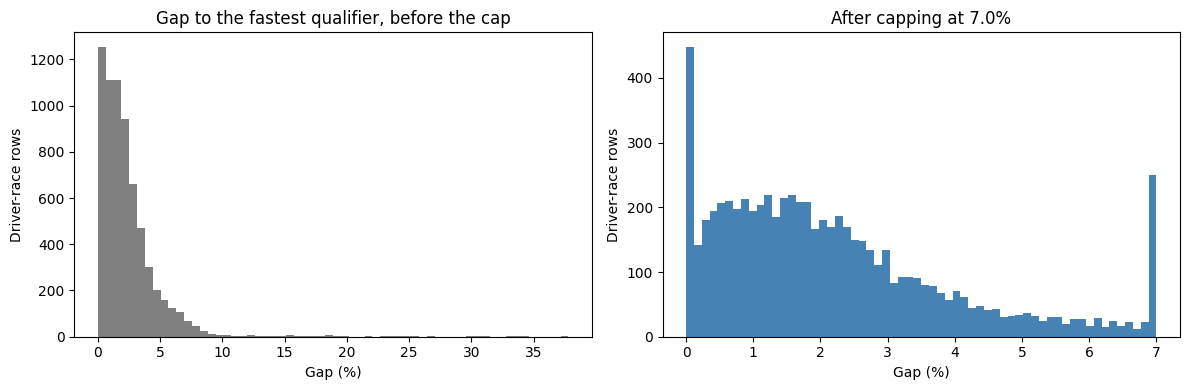

In [19]:
# 6.3 Effect of capping the qualifying gap at 7% (training seasons)
train_rows = table[table['split'] == 'train']
over = train_rows['quali_gap_uncapped'] > GAP_CAP
print(f"Training rows with a gap above {GAP_CAP}%: {over.sum()} of {len(train_rows)} "
      f"(largest gap {train_rows['quali_gap_uncapped'].max():.1f}%)")
print("Races with the most capped gaps:")
print(train_rows[over].groupby(['year', 'race_name']).size().sort_values(ascending=False, kind='stable').head(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_rows['quali_gap_uncapped'].dropna(), bins=60, color='grey')
axes[0].set_title('Gap to the fastest qualifier, before the cap')
axes[1].hist(train_rows['quali_gap_pct'].dropna(), bins=60, color='steelblue')
axes[1].set_title(f'After capping at {GAP_CAP}%')
for ax in axes:
    ax.set_xlabel('Gap (%)')
    ax.set_ylabel('Driver-race rows')
plt.tight_layout()
plt.show()

In [20]:
# 6.3 Worked example 1: a form value is the average of the driver's previous races, never the current one
row = table[(table['driverRef'] == 'hamilton') & (table['year'] == 2018) & (table['round'] == 10)].iloc[0]
earlier = table[(table['driverId'] == row['driverId']) & (table['date'] < row['date'])].tail(FORM_WINDOW)
print(f"Hamilton before the {row['year']} {row['race_name']} - his previous {FORM_WINDOW} races:")
print(earlier[['year', 'race_name', 'positionOrder', 'podium']].to_string(index=False))
print(f"Average finish of these races: {earlier['positionOrder'].mean():.2f} -> drv_form_avg_finish in the table: {row['drv_form_avg_finish']:.2f}")
print(f"Podium rate of these races:    {earlier['podium'].mean():.2f} -> drv_form_podium_rate in the table: {row['drv_form_podium_rate']:.2f}")

# Worked example 2: the dataset's standings for a race ALREADY include that race, so we use the previous race's
winner = table[(table['raceId'] == row['raceId']) & (table['positionOrder'] == 1)].iloc[0]
ds = dfs_clean['driver_standings']
points_stored = ds.loc[(ds['raceId'] == winner['raceId']) & (ds['driverId'] == winner['driverId']), 'points'].iloc[0]
points_before = ds.loc[(ds['raceId'] == winner['prev_raceId']) & (ds['driverId'] == winner['driverId']), 'points'].iloc[0]
print(f"\nWinner of that race: {winner['driverRef']}")
print(f"Points stored for this race: {points_stored:.0f} (already includes this win)")
print(f"Points after the previous race: {points_before:.0f} <- what the feature uses")

# Three checks
assert not table.duplicated(['raceId', 'driverId']).any()                           # one row per driver per race
assert table.loc[table['career_starts'] == 0, 'drv_form_avg_finish'].isna().all()   # a first race has no form: the race itself is never used
assert (table['prev_date'].isna() | (table['prev_date'] < table['date'])).all()     # standings always come from an earlier race
print("\nAll 3 checks passed")

# Grid 0 = no grid slot. Among the starters kept here it is almost always a pit-lane start, but a car that failed before
# the start (no lap completed) is also recorded with grid 0, so pit_lane_start marks it too
grid0 = table[(table['year'] >= FIRST_YEAR) & (table['grid'] == 0)].merge(df_master[['raceId', 'driverId', 'laps']],
                                                                            on=['raceId', 'driverId'])
print(f"Grid 0 in the modelling rows: {len(grid0)} (podiums: {grid0['podium'].sum()}), of which {(grid0['laps'] == 0).sum()} "
      f"completed no lap (the car failed before the start); pit_lane_start marks all {len(grid0)}")

Hamilton before the 2018 British Grand Prix - his previous 5 races:
 year           race_name  positionOrder  podium
 2018  Spanish Grand Prix              1       1
 2018   Monaco Grand Prix              3       1
 2018 Canadian Grand Prix              5       0
 2018   French Grand Prix              1       1
 2018 Austrian Grand Prix             16       0
Average finish of these races: 5.20 -> drv_form_avg_finish in the table: 5.20
Podium rate of these races:    0.60 -> drv_form_podium_rate in the table: 0.60

Winner of that race: vettel
Points stored for this race: 171 (already includes this win)
Points after the previous race: 146 <- what the feature uses

All 3 checks passed
Grid 0 in the modelling rows: 77 (podiums: 0), of which 5 completed no lap (the car failed before the start); pit_lane_start marks all 77


**[OBSERVATION]:**
- **19 features in 6 groups** were built for all 24,697 starters. In the 8,939 modelling rows (2003–2024):
  - Grid and standings features are never blank (count 8,939): a driver or team with no standing yet already has points share 0 and a place behind the field (the rule above).
  - Some features are blank for a known reason: qualifying position (8,916 filled), qualifying gap (8,792), driver form (8,850, blank for a driver's first race), team form (8,883, blank for the first race of a new or renamed team, or of a team id back after more than a season) and circuit podium rate (6,930, blank on a driver's first visit to a circuit). 6.5 fills these.
- **Gap cap:** 232 of the 6,804 training rows had a qualifying gap above 7%, the largest 37.8%.
  - After the cap those rows sit at exactly 7%, which makes the tall bar at the right edge of the second chart; every other value is unchanged. The second chart spans only 0–7%, so its bars are narrower than in the first one.
  - The capped rows cluster in a few races: 13 in the 2011 Belgian GP, 12 in the 2013 Australian GP and 10 in the 2010 Brazilian GP, then 8 each in the 2014 British and 2016 Hungarian GPs. Large gaps in only a handful of races point to something about those sessions, such as conditions changing during qualifying, rather than to slow cars; the dataset has no weather data to confirm the cause.
- **Worked example 1 (form uses only earlier races):** before the 2018 British Grand Prix, Hamilton's previous 5 races were the Spanish, Monaco, Canadian, French and Austrian GPs, with finishes 1, 3, 5, 1 and 16.
  - Their average is 5.20 and the podium rate 0.60, exactly the values in the table.
  - The British GP itself is not in the list, so its result cannot leak into its own prediction.
  - At this point the table uses the starting window of 5 races; 6.4 then compares 3, 5 and 10 races and keeps 10. `shift(1)` works the same way for every window, so the final 10-race features are just as leakage-free (Section 10 rebuilds a whole race and gets exactly the final table's values).
- **Worked example 2 (the standings trap):** Vettel won that race.
  - The standings stored for that race give him 171 points, which already includes the win.
  - After the previous race he had 146. The feature uses the previous race's standings, so it only knows what was known before the start.
- **The three checks passed:**
  - one row per driver per race;
  - a driver's first race has no form value, so a race is never part of its own average;
  - every standings value comes from an earlier race.
- **Grid 0:** 77 modelling rows have grid 0, and none reached the podium. 5 of them completed no lap: the car failed before the start, and the data records that with grid 0 too, so `pit_lane_start` marks them as well (a limitation, 6.8). The others are pit-lane starts.

### 6.4 Evidence for the features

**[GOAL]:** Show, with numbers and plots, that each kept feature is worth using and each left-out candidate is not.

**[LOGIC]:**
- **The score:** for one feature on its own, the ROC-AUC. It is the chance that a random podium finisher has a "better" value of that feature than a random non-podium finisher: 0.5 means no better than a coin flip, 1.0 means perfect. If lower values mean more podiums (e.g. grid position), the score is flipped so that it always lies between 0.5 and 1. Blank values are skipped.
- **Training seasons only.** All evidence uses 2003–2019, so no choice is based on validation or test results.
- **Form window:** the table is built three times (form over the last 3, 5 and 10 races), and the window whose form features have the best average score is kept; its table becomes the final one. This is the trial-and-error route the spec allows, so all three attempts stay visible, and 6.6 also compares the three with the complete pipeline.
- **Left-out candidates are scored too:** age, round, year and home race. Q2 found no home advantage once the starting position is known; this table checks the other three the same way.
- **Which candidates are kept (one rule for all of them):** a feature that carries a value is kept if it scores at least 0.6 on its own, clearly better than a coin flip. A 0/1 flag is kept only if it marks rows where another kept feature was filled in or means something different (a rookie's form, a first visit's circuit record, a pit-lane grid slot, round-1 standings); such flags are rare, so their own score stays near 0.5 whatever they are worth. The code applies the rule to every candidate, checks that it gives exactly the 19 features, and plots every score.
- **Plots:** the podium rate across each feature's values, a correlation map (which features carry the same information), and the share of blank values per split. Blank shares describe data availability only, so all three splits are shown.

In [21]:
# 6.4 Evidence (training seasons only). First: how many past races should the form features look back?
from sklearn.metrics import roc_auc_score


def single_feature_score(values, podium):
    """How well ONE feature on its own separates podium finishers from the rest (ROC-AUC: 0.5 = coin flip, 1 = perfect).
    Blank rows are skipped. If lower values mean more podiums (e.g. grid position) the score is flipped, so it is >= 0.5."""
    known = values.notna()
    auc = roc_auc_score(podium[known], values[known])
    return max(auc, 1 - auc), ('higher' if auc >= 0.5 else 'lower')


# the six form features whose values depend on the window (is_rookie does not)
FORM_FEATURES = ['drv_form_podium_rate', 'drv_form_avg_finish', 'drv_form_dnf_rate',
                 'team_form_podiums_per_race', 'team_form_avg_best_finish', 'team_form_dnf_rate']
window_scores = {}
window_tables = {}  # the three trial tables are kept: 6.6 also compares them with the complete pipeline
for window in (3, 5, 10):
    trial = build_table(starts, window)
    window_tables[window] = trial
    trial_train = trial[trial['split'] == 'train']
    window_scores[window] = {f: single_feature_score(trial_train[f], trial_train['podium'])[0] for f in FORM_FEATURES}
window_table = pd.DataFrame(window_scores)  # one column per window: 3, 5, 10
window_table.loc['average'] = window_table.mean()
print("Score of each form feature when it looks back 3, 5 or 10 races (training seasons):")
print(window_table.round(3).to_string())

FORM_WINDOW = int(window_table.loc['average'].idxmax())  # keep the window with the best average score
print(f"\nChosen window: last {FORM_WINDOW} races")

table = window_tables[FORM_WINDOW]  # the trial table built with the chosen window becomes the final table
assert not table.duplicated(['raceId', 'driverId']).any()  # the final table still has one row per driver per race
model_df = table[table['year'] >= FIRST_YEAR].reset_index(drop=True)
train = model_df[model_df['split'] == 'train'].copy()

Score of each form feature when it looks back 3, 5 or 10 races (training seasons):
                               3      5      10
drv_form_podium_rate        0.823  0.856  0.876
drv_form_avg_finish         0.845  0.865  0.877
drv_form_dnf_rate           0.601  0.628  0.666
team_form_podiums_per_race  0.859  0.875  0.883
team_form_avg_best_finish   0.882  0.888  0.890
team_form_dnf_rate          0.618  0.662  0.696
average                     0.771  0.796  0.814

Chosen window: last 10 races


                   feature  kept  score more podiums when value is  available (%)
                 quali_pos  True  0.910                      lower           99.7
                  grid_pos  True  0.909                      lower          100.0
             quali_gap_pct  True  0.896                      lower           98.2
         team_points_share  True  0.891                     higher          100.0
 team_form_avg_best_finish  True  0.890                      lower           99.3
             drv_champ_pos  True  0.888                      lower          100.0
          drv_points_share  True  0.886                     higher          100.0
team_form_podiums_per_race  True  0.883                     higher           99.3
       drv_form_avg_finish  True  0.877                      lower           98.9
      drv_form_podium_rate  True  0.876                     higher           98.9
            team_champ_pos  True  0.866                      lower          100.0
       circuit_p

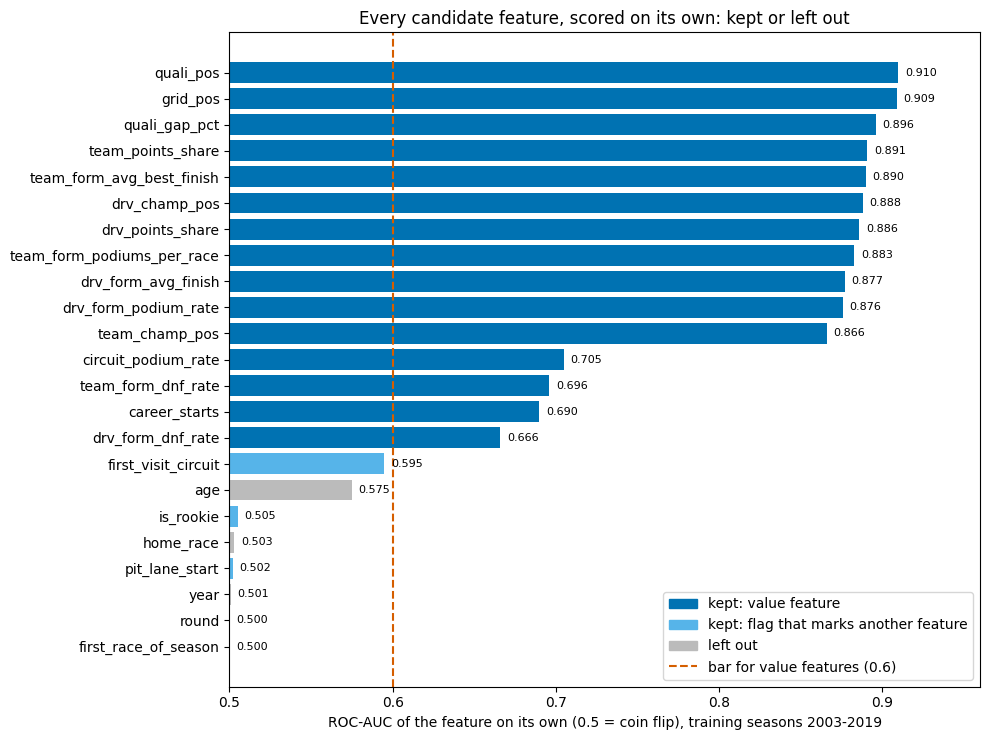

In [22]:
# 6.4 One score per feature: the 19 kept features AND the candidates left out, then the rule that picks the 19
train['age'] = (train['date'] - train['dob']).dt.days / 365.25
home_country = train['nationality'].str.strip().map(nationality_to_country)  # Q2's mapping
train['home_race'] = (home_country == train['circuit_country'].replace({'United States': 'USA'})).astype(int)
LEFT_OUT = ['age', 'round', 'year', 'home_race']

score_rows = []
for f in FEATURES + LEFT_OUT:
    score, direction = single_feature_score(train[f], train['podium'])
    score_rows.append({'feature': f, 'kept': f in FEATURES, 'score': round(score, 3),
                       'more podiums when value is': direction,
                       'available (%)': round(train[f].notna().mean() * 100, 1)})
score_table = pd.DataFrame(score_rows).sort_values('score', ascending=False, kind='stable')  # ties keep the feature order
print(score_table.to_string(index=False))

# Sprint races exist only in the latest seasons, so a sprint feature would be blank for every training row
sprint_races = dfs_clean['races'][dfs_clean['races']['raceId'].isin(dfs_clean['sprint_results']['raceId'])]
print(f"\nSprint races in the data (not used as a feature): {len(sprint_races)}, "
      f"seasons {sprint_races['year'].min()}-{sprint_races['year'].max()}")

# Which candidates are kept: one rule, applied to every candidate in the table above (training seasons only)
#   - a feature that carries a value (a position, share, rate, count or year) is kept if it scores at least MIN_SCORE
#     on its own, i.e. clearly better than a coin flip (0.5)
#   - a 0/1 flag is kept only if it marks rows where another kept feature was filled in or means something different;
#     such flags are rare, so their own score stays near 0.5 whatever they are worth
MIN_SCORE = 0.6
FLAG_ROLE = {'is_rookie': "first race: the three driver-form values are blank and get filled in (6.5)",
             'first_visit_circuit': "first visit: circuit_podium_rate is blank and gets filled in (6.5)",
             'pit_lane_start': "grid_pos is the back of the field because the car has no grid slot",
             'first_race_of_season': "round 1: the standings are last season's final standings"}
selection = score_table[['feature', 'score', 'kept']].copy()
selection['kind'] = ['flag' if set(train[f].dropna().unique()) <= {0, 1} else 'value' for f in selection['feature']]


def decide(feature, kind, score):
    if kind == 'flag' and feature in FLAG_ROLE:
        return 'kept', 'flag: ' + FLAG_ROLE[feature]
    if kind == 'flag':
        return 'left out', f"flag that marks no other feature; on its own {score:.3f} < {MIN_SCORE}"
    if score >= MIN_SCORE:
        return 'kept', f"{score:.3f} >= {MIN_SCORE}"
    return 'left out', f"{score:.3f} < {MIN_SCORE}"


decided = [decide(f, k, s) for f, k, s in zip(selection['feature'], selection['kind'], selection['score'])]
selection['decision'] = [d for d, _ in decided]
selection['reason'] = [r for _, r in decided]
assert (selection['decision'] == 'kept').equals(selection['kept'])                       # the rule gives the kept column,
assert set(selection.loc[selection['decision'] == 'kept', 'feature']) == set(FEATURES)  # i.e. exactly the 19 features
print(f"\nSelection rule: a value feature is kept at a score of {MIN_SCORE} or more; a 0/1 flag only if it marks rows "
      "where another kept feature was filled in or means something different")
with pd.option_context('display.max_colwidth', 100, 'display.width', 200):
    width = selection['reason'].str.len().max()  # pad the reasons so they read left-aligned
    print(selection[['feature', 'kind', 'score', 'decision', 'reason']].to_string(
        index=False, justify='left', formatters={'reason': lambda r: r.ljust(width)}))
values = selection[selection['kind'] == 'value']
low_kept = values[values['decision'] == 'kept'].nsmallest(1, 'score').iloc[0]
high_out = values[values['decision'] == 'left out'].nlargest(1, 'score').iloc[0]
print(f"Kept: {(selection['decision'] == 'kept').sum()} of {len(selection)} candidates. No value feature scores between "
      f"{high_out['score']:.3f} ({high_out['feature']}, left out) and {low_kept['score']:.3f} ({low_kept['feature']}, kept), "
      f"so any bar in that gap gives the same {len(FEATURES)} features")
print("Not scored, and why: sprint results (no training season has a sprint race), driver or team identity "
      "(the model would memorise names), anything from the race itself (known only after the start: leakage)")

plot_df = selection.sort_values('score', kind='stable')
COLOURS = {('kept', 'value'): '#0072B2', ('kept', 'flag'): '#56B4E9',
           ('left out', 'value'): '#BBBBBB', ('left out', 'flag'): '#BBBBBB'}
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(plot_df['feature'], plot_df['score'] - 0.5, left=0.5,
        color=[COLOURS[(d, k)] for d, k in zip(plot_df['decision'], plot_df['kind'])])
for y, s in enumerate(plot_df['score']):
    ax.text(s + 0.004, y, f"{s:.3f}", va='center', fontsize=8)
ax.axvline(MIN_SCORE, color='#D55E00', linestyle='--')
ax.set_xlim(0.5, 0.96)
ax.set_xlabel('ROC-AUC of the feature on its own (0.5 = coin flip), training seasons 2003-2019')
ax.set_title('Every candidate feature, scored on its own: kept or left out')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ('#0072B2', '#56B4E9', '#BBBBBB')]
          + [plt.Line2D([0], [0], color='#D55E00', linestyle='--')],
          labels=['kept: value feature', 'kept: flag that marks another feature', 'left out',
                  f'bar for value features ({MIN_SCORE})'], loc='lower right')
plt.tight_layout()
plt.show()

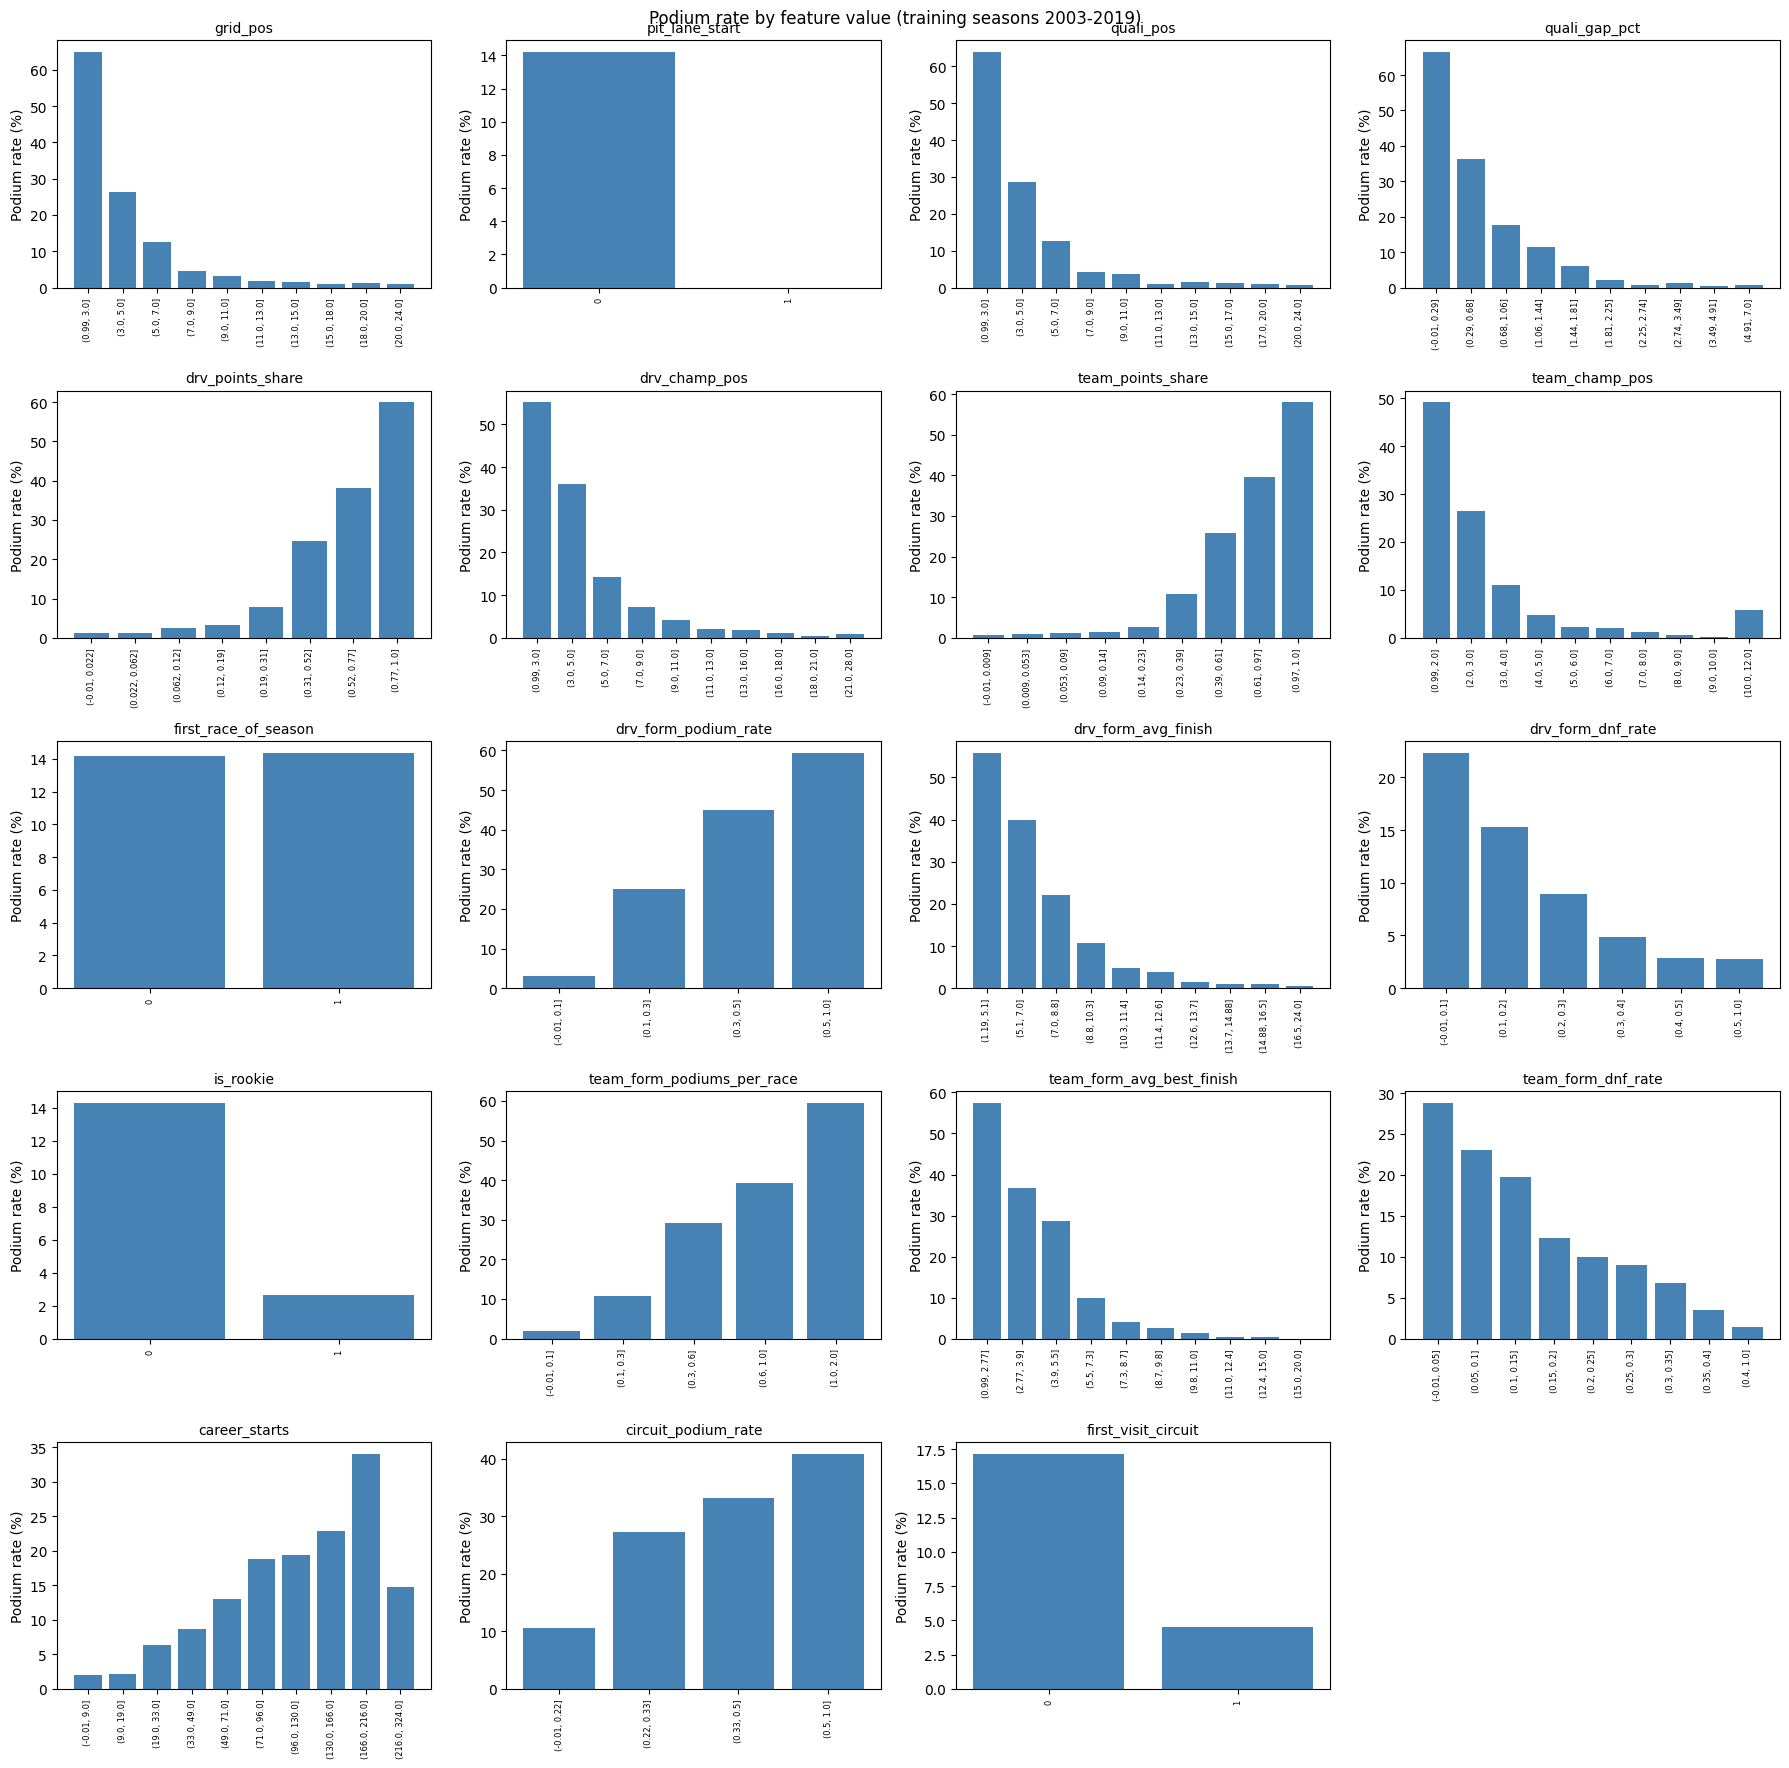

In [23]:
# 6.4 Podium rate across each feature's values (training seasons): one small chart per feature
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
for ax, f in zip(axes.flat, FEATURES):
    values = train[f]
    # few distinct values (flags): one bar per value; otherwise 10 equal-sized groups from low to high
    groups = values if values.nunique() <= 10 else pd.qcut(values, 10, duplicates='drop', precision=2)
    rate = train.groupby(groups, observed=True)['podium'].mean() * 100
    ax.bar(range(len(rate)), rate.values, color='steelblue')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([str(i) for i in rate.index], rotation=90, fontsize=6)
    ax.set_title(f, fontsize=10)
    ax.set_ylabel('Podium rate (%)')
for ax in axes.flat[len(FEATURES):]:
    ax.axis('off')  # unused panels
plt.suptitle('Podium rate by feature value (training seasons 2003-2019)')
plt.tight_layout()
plt.show()

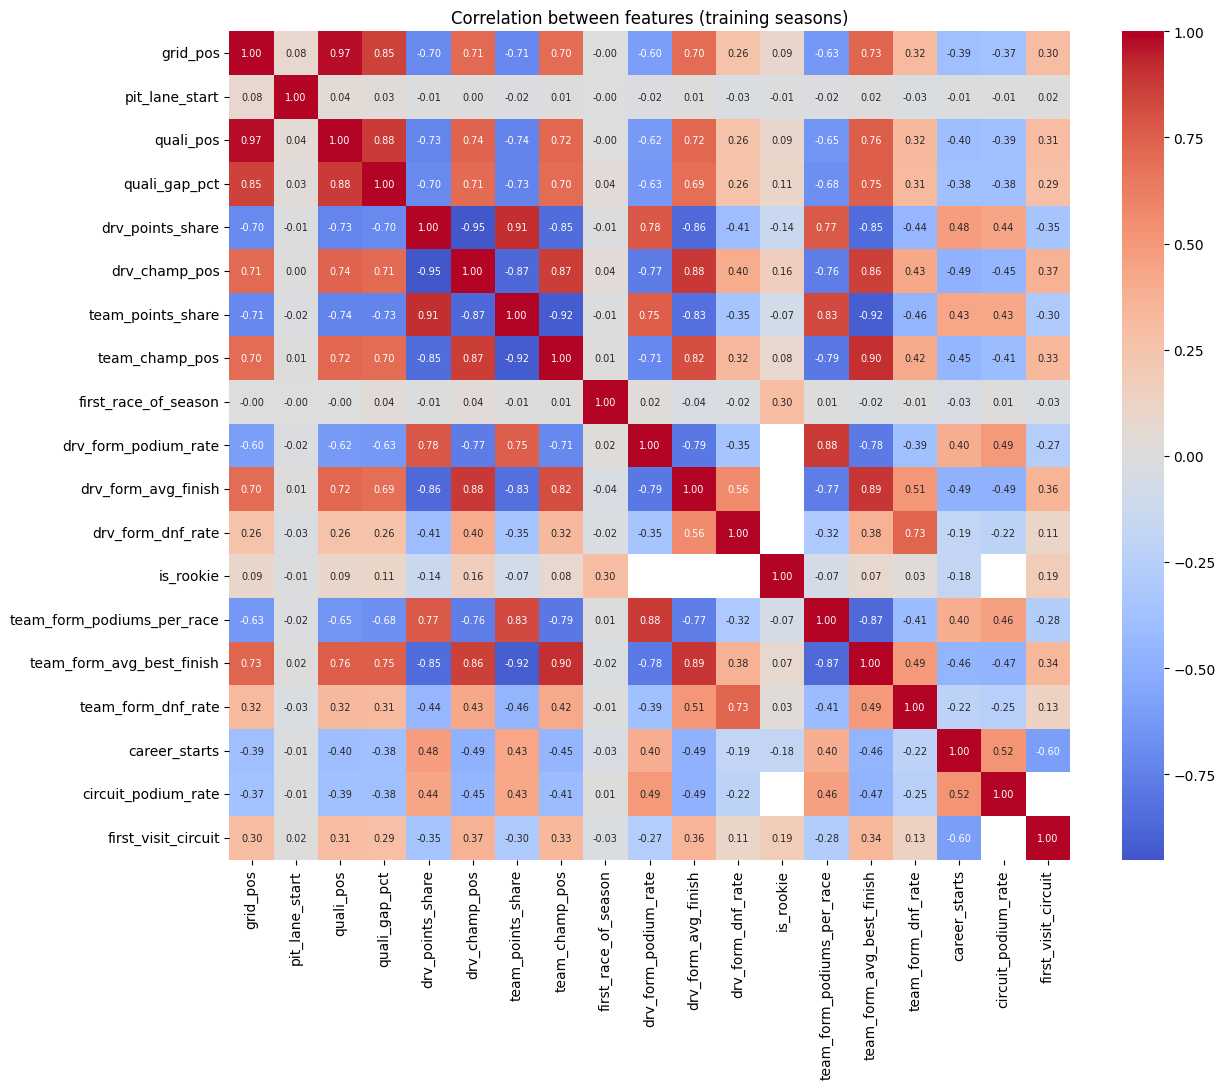

Driver championship position vs driver points share: -0.95
Team championship position vs team points share: -0.92
Grid position vs qualifying position: 0.97

Blank values (%) per split:
split                       train  validation  test
grid_pos                      0.0         0.0   0.0
pit_lane_start                0.0         0.0   0.0
quali_pos                     0.3         0.1   0.0
quali_gap_pct                 1.8         1.2   1.0
drv_points_share              0.0         0.0   0.0
drv_champ_pos                 0.0         0.0   0.0
team_points_share             0.0         0.0   0.0
team_champ_pos                0.0         0.0   0.0
first_race_of_season          0.0         0.0   0.0
drv_form_podium_rate          1.1         0.8   0.6
drv_form_avg_finish           1.1         0.8   0.6
drv_form_dnf_rate             1.1         0.8   0.6
is_rookie                     0.0         0.0   0.0
team_form_podiums_per_race    0.7         0.8   0.3
team_form_avg_best_finish     0.7 

In [24]:
# 6.4 Which features carry the same information? (Spearman = correlation of the rankings)
corr = train[FEATURES].corr(method='spearman')
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation between features (training seasons)')
plt.tight_layout()
plt.show()
print(f"Driver championship position vs driver points share: {corr.loc['drv_champ_pos', 'drv_points_share']:.2f}")
print(f"Team championship position vs team points share: {corr.loc['team_champ_pos', 'team_points_share']:.2f}")
print(f"Grid position vs qualifying position: {corr.loc['grid_pos', 'quali_pos']:.2f}")

# Blank values per feature and split (data availability only, no results)
blanks = model_df[FEATURES].isna().groupby(model_df['split']).mean().T * 100
print("\nBlank values (%) per split:")
print(blanks[['train', 'validation', 'test']].round(1).to_string())

**[OBSERVATION]:**
- **Form window: 10 races.**
  - The average score of the six form features rises with the window: 0.771 (last 3), 0.796 (last 5), 0.814 (last 10).
  - All six form features score higher with 10 races than with 5. For example, driver podium rate is 0.876 vs 0.856, and the retirement rates are 0.666 vs 0.628 (driver) and 0.696 vs 0.662 (team).
  - A longer window gives a steadier picture of how strong a driver or team is. The table built with 10 races is the final one; 6.6 checks this choice with the complete pipeline.
- **Strongest single features:** qualifying position (0.910), grid position (0.909), qualifying gap (0.896), team points share (0.891), team form best finish (0.890), driver championship position (0.888) and driver points share (0.886). The podium-rate charts show the same: the podium rate changes steadily from one value group to the next.
- **Useful but weaker:** circuit podium rate (0.705), team retirement rate (0.696), career starts (0.690), driver retirement rate (0.666) and the first-visit flag (0.595).
- **Flags close to 0.5:** rookie (0.505), pit-lane start (0.502) and first race of the season (0.500).
  - This is expected. The flags are rare (the 6.3 summary shows means of 0.01, 0.01 and 0.05), so the score cannot rise far above 0.5 even when the flag matters. The charts show what the score hides: rookies reach the podium far less often than other drivers, and pit-lane starters never did in the training seasons (empty bar). Only the first race of the season looks like any other race.
  - They tell the model *how to read other values*: a rookie's form is a filled-in value (6.5); a pit-lane starter's grid number came from the pit lane, not from qualifying; round-1 standings are last season's.
  - Whether they add anything after training is measured by the group ablation in Objective 5.
- **Left out:** age (0.575), home race (0.503), year (0.501) and round (0.500).
  - Home race confirms Q2: no advantage on its own.
  - Age is the strongest of the four, but career starts (0.690) captures experience better, and age has no "how to read other values" role like the flags.
  - Sprint results are not used either: the data holds only 18 sprint races, all in 2021–2024, so the feature would be blank for every training row (2003–2019).
- **Selection (the rule above, applied to all 23 candidates):** the kept value features score 0.666 or more, and the left-out ones 0.575 or less (age, year, round), so no value feature lies between 0.575 and 0.666: any bar in that gap gives the same 19 features. The flags kept (first visit 0.595, rookie 0.505, pit-lane start 0.502, first race of the season 0.500) each mark another feature; home race (0.503) marks nothing and is left out. The code checks that the rule gives exactly the 19 features, and the bar chart shows every candidate against the 0.6 bar.
- **Overlapping features (correlation map):**
  - Championship position and points share carry almost the same information: Spearman −0.95 (driver) and −0.92 (team). Both are kept, because both are legitimate pre-race information and both score highly (driver position 0.888 vs share 0.886; team 0.866 vs 0.891). They sit in the same ablation group, so the ablation is not confused by the overlap.
  - Grid and qualifying position correlate at 0.97. They stay in separate groups, as in the spec's example, so removing only one of them in the ablation may cost little, because the other carries the same information.
- **Links to Objective 2:** Q2's "no home advantage" is why home race is left out; Q3's reliability differences between teams are why the two retirement-rate features are in.
- **Blank values:** in the training rows, circuit podium rate is blank in 23.8% (first visits), the qualifying gap in 1.8%, driver form in 1.1% and team form in 0.7% (new, renamed and returning teams); standings, grid and flags are never blank (a missing standing is already set by the 6.3 rule). Validation looks similar (circuit podium rate 28.2%); the test seasons have fewer blank circuit records (12.3%). 6.5 fills them.


### 6.5 Filling blanks and rescaling

**[GOAL]:** Make the features usable by every model: no blank values, and comparable ranges.

**[LOGIC]:**
- **Filling blanks.** Some features are blank for a good reason: a driver's first race has no form, a first visit to a circuit has no record there, and a few drivers have no qualifying time. Models cannot handle blanks, so each blank gets the feature's **median** (its middle value), which is not pulled around by a few extreme values. The `is_rookie` and `first_visit_circuit` flags (6.3) tell the model when a value was filled in.
- **Rescaling.** The features come in very different ranges (the table below shows each one's minimum and maximum). Logistic regression and neural networks work badly when ranges differ this much, so every feature is rescaled to mean 0 and spread (standard deviation) 1.
- **Learned from the training seasons only.** The medians, means and spreads are learned from 2003–2019 and then applied unchanged to validation and test, exactly as they would be applied to a future race. 6.6 tests the opposite order.
- **Two plain functions:** `learn_preparation` learns the numbers, and `prepare` applies them.
- **Reference model.** A small logistic regression on all features, scored on the validation seasons, is used in 6.6 to compare options. It is only a measuring tool; the real models are built in Objective 4. Two scores are reported: ROC-AUC (as in 6.4, but for the whole model) and PR-AUC, which focuses on how well the rare podium finishers are ranked at the top.

Effect on the training rows:
                            blanks before  min before  max before  blanks after  min after  max after  mean after  std after
grid_pos                                0         1.0        24.0             0      -1.63       2.05        -0.0        1.0
pit_lane_start                          0         0.0         1.0             0      -0.06      17.56        -0.0        1.0
quali_pos                              22         1.0        24.0             0      -1.64       2.07         0.0        1.0
quali_gap_pct                         125         0.0         7.0             0      -1.25       2.70        -0.0        1.0
drv_points_share                        0         0.0         1.0             0      -0.82       2.48        -0.0        1.0
drv_champ_pos                           0         1.0        28.0             0      -1.59       2.50         0.0        1.0
team_points_share                       0         0.0         1.0             0      -0.89      

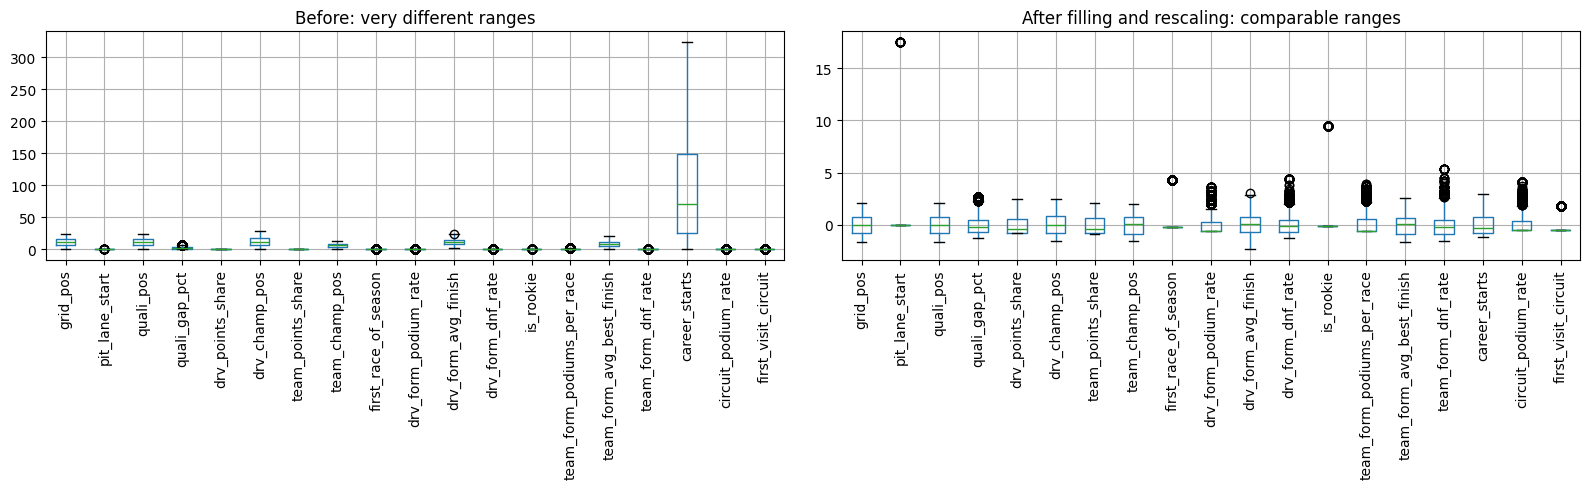


Reference model, all 19 features, validation seasons: ROC-AUC 0.931, PR-AUC 0.726


In [25]:
# 6.5 Filling blanks and rescaling (numbers learned from the training seasons only)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score


def learn_preparation(X_fit):
    """Learn the numbers used to fill blanks and rescale, from the given rows (normally the training seasons)."""
    medians = X_fit.median()
    filled = X_fit.fillna(medians)
    return medians, filled.mean(), filled.std()


def prepare(X, medians, means, stds):
    """Fill each blank with the feature's median, then rescale every feature to mean 0 and spread (std) 1."""
    return (X.fillna(medians) - means) / stds


is_train = model_df['split'] == 'train'
is_val = model_df['split'] == 'validation'
is_test = model_df['split'] == 'test'
TRAIN_STATS = learn_preparation(model_df.loc[is_train, FEATURES])
X_ready = prepare(model_df[FEATURES], *TRAIN_STATS)
y = model_df['podium']

before = model_df.loc[is_train, FEATURES]
after = X_ready[is_train]
effect = pd.DataFrame({'blanks before': before.isna().sum(), 'min before': before.min(), 'max before': before.max(),
                       'blanks after': after.isna().sum(), 'min after': after.min(), 'max after': after.max(),
                       'mean after': after.mean(), 'std after': after.std()})
print("Effect on the training rows:")
print(effect.round(2).to_string())
print(f"\nBlank values left after preparing all splits: {int(X_ready.isna().sum().sum())}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
before.boxplot(ax=axes[0], rot=90)
axes[0].set_title('Before: very different ranges')
after.boxplot(ax=axes[1], rot=90)
axes[1].set_title('After filling and rescaling: comparable ranges')
plt.tight_layout()
plt.show()


def reference_scores(X_train, y_train, X_eval, y_eval):
    """Small reference model (logistic regression), used only to compare options on the validation seasons.
    The real models are built in Objective 4."""
    model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return round(roc_auc_score(y_eval, p), 3), round(average_precision_score(y_eval, p), 3)


auc, pr = reference_scores(X_ready[is_train], y[is_train], X_ready[is_val], y[is_val])
print(f"\nReference model, all {len(FEATURES)} features, validation seasons: ROC-AUC {auc}, PR-AUC {pr}")

**[OBSERVATION]:**
- **Before:** the training rows had blanks in circuit podium rate (1,622), qualifying gap (125), the three driver-form features (75 each), the three team-form features (46 each) and qualifying position (22). The ranges were very different: 0–1 for shares, rates and flags, 1–28 for driver championship position, and 0–324 for career starts.
- **After:**
  - **No blanks are left in any split** (0 after preparing train, validation and test).
  - Every feature has mean 0 and standard deviation 1 on the training rows, so all features are on the same scale. The box plots show this.
  - Rare flags get large values after rescaling (pit-lane start up to 17.56, rookie up to 9.47), because a rare 1 lies far from an average close to 0. This is normal and does not change the order of the values.
- **Reference model:** a logistic regression on all 19 prepared features scores **ROC-AUC 0.931 and PR-AUC 0.726** on the validation seasons. This is the baseline the experiments in 6.6 are compared with.


### 6.6 Experiments: preprocessing order and older seasons

**[GOAL]:** Test whether the order of the preparation steps matters (the spec asks for at least two such experiments), and whether training on more seasons would help.

**[LOGIC]:** Each experiment changes one thing and keeps everything else the same. It reports both the effect on the data and the reference model's validation scores (ROC-AUC and PR-AUC, from 6.5).
1. **Order experiment 1: fill/rescale numbers learned after vs before splitting.** The correct order is to split first and learn the numbers from the training seasons only. Learning them before splitting (training + validation together) lets the validation seasons influence their own preparation, which is leakage. The test seasons stay locked away in both versions.
2. **Order experiment 2: history features built before vs after splitting.** Form, career starts and circuit records are built on the full timeline (6.3), so the first validation races can use the end of the training seasons as history. Building them separately inside each split throws that history away: every split starts as if nobody had raced before.
3. **Older seasons:** train on seasons from 1950, 1980, 1994 or 2003 up to 2019, and score on the validation seasons. Before 2003, qualifying data is mostly missing (6.1), so those rows get the filled-in median.
4. **Form window with the complete pipeline:** 6.4 chose the window (3, 5 or 10 races) from single-feature scores on the training seasons. Here the three tables also go through the whole pipeline (filling, rescaling, reference model) and are scored on the validation seasons, as a before/after check of that choice.

In [26]:
# 6.6 Order experiment 1: learn the fill/rescale numbers AFTER splitting (training seasons only)
#                          vs BEFORE splitting (training + validation together; test seasons stay locked away)
fit_options = {'after splitting: training seasons only': is_train,
               'before splitting: training + validation': model_df['split'] != 'test'}
SHOW = ['quali_gap_pct', 'drv_points_share', 'drv_form_avg_finish', 'circuit_podium_rate']
rows = []
for name, fit_rows in fit_options.items():
    medians, means, stds = learn_preparation(model_df.loc[fit_rows, FEATURES])
    X = prepare(model_df[FEATURES], medians, means, stds)
    auc, pr = reference_scores(X[is_train], y[is_train], X[is_val], y[is_val])
    rows.append({'order': name,
                 **{f'median {f}': round(medians[f], 3) for f in SHOW},
                 **{f'mean {f}': round(means[f], 3) for f in SHOW},
                 'validation ROC-AUC': auc, 'validation PR-AUC': pr})
print(pd.DataFrame(rows).set_index('order').T.to_string())

order                       after splitting: training seasons only  before splitting: training + validation
median quali_gap_pct                                         1.809                                    1.793
median drv_points_share                                      0.115                                    0.119
median drv_form_avg_finish                                  11.400                                   11.400
median circuit_podium_rate                                   0.000                                    0.000
mean quali_gap_pct                                           2.213                                    2.183
mean drv_points_share                                        0.249                                    0.250
mean drv_form_avg_finish                                    11.115                                   11.056
mean circuit_podium_rate                                     0.118                                    0.118
validation ROC-AUC          

In [27]:
# 6.6 Order experiment 2: build the history features BEFORE splitting (on the full timeline, as in 6.3)
#                          vs AFTER splitting (inside each split separately, so each split starts with no history)
built_inside = pd.concat([build_table(starts[starts['split'] == s], FORM_WINDOW) for s in ('train', 'validation')],
                         ignore_index=True)
versions = {'before splitting (full timeline)': model_df[model_df['split'] != 'test'],
            'after splitting (inside each split)': built_inside}
rows = []
for name, df in versions.items():
    tr = df[df['split'] == 'train']
    va = df[df['split'] == 'validation']
    stats = learn_preparation(tr[FEATURES])
    auc, pr = reference_scores(prepare(tr[FEATURES], *stats), tr['podium'], prepare(va[FEATURES], *stats), va['podium'])
    rows.append({'order': name,
                 'validation rows with blank driver form (%)': round(va['drv_form_avg_finish'].isna().mean() * 100, 1),
                 'validation rows marked rookie (%)': round(va['is_rookie'].mean() * 100, 1),
                 'validation rows marked first visit (%)': round(va['first_visit_circuit'].mean() * 100, 1),
                 'validation mean career starts': round(va['career_starts'].mean(), 1),
                 'validation ROC-AUC': auc, 'validation PR-AUC': pr})
print(pd.DataFrame(rows).set_index('order').T.to_string())

order                                       before splitting (full timeline)  after splitting (inside each split)
validation rows with blank driver form (%)                             0.800                                3.600
validation rows marked rookie (%)                                      0.800                                3.600
validation rows marked first visit (%)                                28.200                               65.600
validation mean career starts                                        120.800                               16.800
validation ROC-AUC                                                     0.931                                0.930
validation PR-AUC                                                      0.726                                0.726


In [28]:
# 6.6 Older-years test: does training on seasons before 2003 help? (validation seasons 2020-2021)
rows = []
for first_year in (1950, 1980, 1994, FIRST_YEAR):
    data = table[table['year'].between(first_year, 2021)]
    fit = data['year'] <= 2019  # training rows; the rest are the validation seasons
    stats = learn_preparation(data.loc[fit, FEATURES])
    X = prepare(data[FEATURES], *stats)
    auc, pr = reference_scores(X[fit], data.loc[fit, 'podium'], X[~fit], data.loc[~fit, 'podium'])
    rows.append({'training from': first_year, 'training rows': int(fit.sum()),
                 'rows without qualifying (%)': round(data.loc[fit, 'quali_pos'].isna().mean() * 100, 1),
                 'validation ROC-AUC': auc, 'validation PR-AUC': pr})
print(pd.DataFrame(rows).to_string(index=False))

 training from  training rows  rows without qualifying (%)  validation ROC-AUC  validation PR-AUC
          1950          22562                         63.1               0.929              0.724
          1980          15732                         47.1               0.930              0.725
          1994          10139                         17.9               0.930              0.717
          2003           6804                          0.3               0.931              0.726


In [29]:
# 6.6 Form window with the complete pipeline: each of the three 6.4 tables (last 3, 5, 10 races) is filled,
#     rescaled and scored with the reference model on the validation seasons
rows = []
for window, trial in window_tables.items():
    trial_df = trial[trial['year'] >= FIRST_YEAR]
    tr = trial_df[trial_df['split'] == 'train']
    va = trial_df[trial_df['split'] == 'validation']
    stats = learn_preparation(tr[FEATURES])
    auc, pr = reference_scores(prepare(tr[FEATURES], *stats), tr['podium'], prepare(va[FEATURES], *stats), va['podium'])
    rows.append({'form window': f'last {window} races', 'validation ROC-AUC': auc, 'validation PR-AUC': pr})
print(pd.DataFrame(rows).to_string(index=False))

  form window  validation ROC-AUC  validation PR-AUC
 last 3 races               0.927              0.724
 last 5 races               0.930              0.727
last 10 races               0.931              0.726


**[OBSERVATION]:**
- **Order experiment 1 (fill/rescale numbers learned after vs before splitting):**
  - The learned numbers barely move. The median qualifying gap goes from 1.809 to 1.793 and the median driver points share from 0.115 to 0.119; the other two medians shown are unchanged. The means shift slightly (qualifying gap 2.213 → 2.183, driver average finish 11.115 → 11.056).
  - The validation scores are the same: ROC-AUC 0.931 and PR-AUC 0.726 in both.
  - The leak has no visible effect here because adding two seasons to seventeen hardly changes a median or a mean.
  - Training-only is still the order used, because it is the only one in which validation seasons are treated as unseen data. With a smaller training set the leak would matter more.
- **Order experiment 2 (history features built before vs after splitting):**
  - Building them inside each split changes the data a lot. In the validation seasons, blank driver form rises from 0.8% to 3.6% of rows (and the rookie flag with it). First visits to a circuit rise from 28.2% to 65.6%. Average career starts fall from 120.8 to 16.8. Experienced drivers suddenly look like newcomers.
  - The scores hardly move: ROC-AUC 0.931 vs 0.930, PR-AUC 0.726 in both. So this experiment does **not** show that the full-timeline order predicts better.
  - The full-timeline order is kept because it describes the drivers correctly: a driver's whole history really is known before the race. The strongest features (grid, qualifying, standings) are not built from these histories at all, which is probably why the score barely changes.
- **Older seasons:**
  - Training from 1950 uses 22,562 rows, of which 63.1% have no qualifying data; it scores ROC-AUC 0.929 and PR-AUC 0.724.
  - Starting in 1980 gives 0.930 and 0.725; starting in 1994 gives 0.930 and 0.717.
  - Starting in 2003 uses only 6,804 rows (0.3% without qualifying) and scores 0.931 and 0.726, the best of the four on both scores.
  - Three times more rows does not help, so 2003 stays the starting season (6.1): it also avoids making up the qualifying features for most rows.
- **Form window with the complete pipeline:**
  - ROC-AUC is highest with 10 races (0.931, against 0.930 with 5 and 0.927 with 3).
  - PR-AUC is highest with 5 races (0.727, against 0.726 with 10 and 0.724 with 3).
  - The two scores point in opposite directions, and every difference is 0.005 or less, so the complete pipeline does not clearly prefer any window. The window stays at 10, chosen by the rule set in advance on the training seasons (6.4), rather than switching on a difference this small in 39 validation races.


### 6.7 Hand-off to Objectives 4–6

**[GOAL]:** Give the modelling, ablation and explanation steps one consistent dataset.

**[LOGIC]:**
- **The same data for every model** (the spec asks for the same rows and the same features): `X_train`, `X_val`, `X_test` have blanks filled and features rescaled with the training-season numbers; `y_train`, `y_val`, `y_test` are podium 1/0.
- **Validation for every choice** (thresholds, hyperparameters); **test only for the final scores.**
- **Ablation (Objective 5):** remove one entry of `FEATURE_GROUPS` at a time and retrain. Championship position and points share overlap strongly (6.4). Because they sit in the same group, the ablation is not confused by that, but permutation importance and SHAP (Objective 6) may split the credit between them.
- **Raw values:** `model_df` keeps the original (unfilled, unscaled) feature values plus the race, driver and team names, for tables and explanations.
- **Inference function (deliverable 7):** to score a new race:
  1. add the race to `dfs_clean['races']` (raceId, year, round, date, circuitId);
  2. add one row per starter to `starts`, with its `constructorId` (the team key for team form and standings) and the result columns (`positionOrder`, `podium`, `dnf`) left empty. Add the whole field, because a pit-lane starter's grid position is the number of cars in the race;
  3. add the qualifying results to `dfs_clean['qualifying']` if they are known;
  4. run `build_table(rows)` (it uses the chosen form window, `FORM_WINDOW`) and take the new race's rows;
  5. call `prepare(new_rows[FEATURES], *TRAIN_STATS)`.

  A missing value, for example no qualifying time, is filled with the training median, so a partially-missing record still works. Section 10 turns these steps into the inference function.

In [30]:
# 6.7 Hand-off to Objectives 4-6
X_train, y_train = X_ready[is_train], y[is_train]
X_val, y_val = X_ready[is_val], y[is_val]
X_test, y_test = X_ready[is_test], y[is_test]  # no choice is made from these (final scores in 7.6-7.7)

summary = pd.DataFrame({'rows': [len(X_train), len(X_val), len(X_test)],
                        'features': [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
                        'podium rate': [y_train.mean(), y_val.mean(), y_test.mean()]},
                       index=['train 2003-2019', 'validation 2020-2021', 'test 2022-2024'])
print(summary.round(3).to_string())

print("\nFeature groups for the ablation (Objective 5):")
for group, cols in FEATURE_GROUPS.items():
    print(f"  {group}: {', '.join(cols)}")

medians, means, stds = TRAIN_STATS
print("\nNumbers learned from the training seasons (used to prepare any new record):")
print(pd.DataFrame({'median (fills blanks)': medians, 'mean': means, 'std': stds}).round(3).to_string())

                      rows  features  podium rate
train 2003-2019       6804        19        0.142
validation 2020-2021   780        19        0.150
test 2022-2024        1355        19        0.151

Feature groups for the ablation (Objective 5):
  grid: grid_pos, pit_lane_start
  qualifying: quali_pos, quali_gap_pct
  standings: drv_points_share, drv_champ_pos, team_points_share, team_champ_pos, first_race_of_season
  driver form: drv_form_podium_rate, drv_form_avg_finish, drv_form_dnf_rate, is_rookie
  team form: team_form_podiums_per_race, team_form_avg_best_finish, team_form_dnf_rate
  extras: career_starts, circuit_podium_rate, first_visit_circuit

Numbers learned from the training seasons (used to prepare any new record):
                            median (fills blanks)    mean     std
grid_pos                                   11.000  11.196   6.238
pit_lane_start                              0.000   0.003   0.057
quali_pos                                  11.000  11.159   6.2

**[OBSERVATION]:**
- **The data handed to Objectives 4–6:**
  - training: 6,804 rows × 19 features (podium rate 14.2%);
  - validation: 780 × 19 (15.0%);
  - test: 1,355 × 19 (15.1%).
- **Six feature groups** are ready for the ablation.
- **The numbers learned from the training seasons** (median for filling, mean and standard deviation for rescaling) are printed above. They are the only numbers needed to prepare a new record the same way, including a partially-missing one.


### 6.8 Known limitations and what was not used

**[GOAL]:** State plainly what this modelling table cannot capture, so the results of Objectives 4–6 are read correctly.

**Known limitations:**
- **Qualifying data drifts over time.** There is no qualifying data before 1994 and it is patchy until 2002 (6.1), so the models only learn from 2003 onwards.
- **Era sensitivity.** The car rules change every few years, and the test seasons (2022–2024) are a new car era (6.2). At the start of a season, the standings and much of the form still come from the previous one. Older eras also behaved differently: a pole position led to a podium 52.2% and 57.5% of the time in the two eras before 2003, against 80.3% (2003–2019) and 74.4% (2020–2021) after (6.1).
- **Conditions in qualifying.** The qualifying gap compares a driver's best lap with the fastest lap of the whole session, so anything that changes between sessions (for example rain, which the dataset does not record) stretches the gap. The capped rows cluster in a few races (6.3), and the 7% cap limits their effect.
- **Renamed and new teams start over.** Team form and standings follow `constructorId` (6.3), as the course introduction asks, so after a rename, at a new team's start, or when a team id comes back after more than a season away, there is no team form yet (it gets the median, 6.5) and no standing at round 1. Team form is blank in 0.7% of training rows, 0.8% of validation rows and 0.3% of test rows (6.4).
- **Grid 0 is not always a pit-lane start.** 5 of the 77 grid-0 modelling rows are cars that failed before the start and completed no lap (6.3). Right after qualifying they still held their qualifying slot, so for them `grid_pos` (back of the field) and `pit_lane_start` carry information from after qualifying. None reached the podium, and they are 5 of 8,939 rows, so the effect on the scores is negligible.
- **A small validation set.** Validation has 39 races (6.2), so differences of a few thousandths between options (6.6) should not be over-read.

**Not used, and why:**
- **Driver or team identity** (names or ids): the model would memorise names instead of learning what makes a driver competitive. Form and standings already measure how strong a driver and a team are, and they also work for newcomers.
- **Sprint results:** only 18 sprint races, all in 2021–2024 (6.4), so the feature would be blank for every training row.
- **Pit stops, lap times and anything from the race itself:** they happen during the race, so using them would be leakage (see the rules at the top of Section 6).
- **Weather, tyre choice and practice pace:** not in the dataset.

## Section 7: Objective 4 - Predictive Modelling

**[GOAL]:** Train and compare a baseline, several statistical models and a shallow neural network on the **same** modelling table (same rows, same 19 features), and report ROC-AUC, PR-AUC, F1, precision and recall on the training, validation and unseen test seasons.

**[LOGIC]:**
- **Same data for every model:** `X_train`, `X_val`, `X_test` from 6.7 (blanks filled, features rescaled with training-season numbers), so the scores are directly comparable.
- **Test seasons stay locked.** Every choice (hyperparameters, early stopping, the probability threshold, which model is "best") uses **training and validation only**. The test seasons are scored in 7.6 and drawn in 7.7, after all choices are made. Later sections show test-season numbers only as a check (8.1) or use test races as examples (9.3, Section 10); no choice is made from them.
- **Order of the work:** 7.1 helpers → 7.2 baseline → 7.3 statistical models → 7.4 shallow neural network → 7.5 how each model works and its limits → 7.6 comparison table → 7.7 curves and confusion matrices → 7.8 metric choice and hand-off.
- **Primary metric: PR-AUC. Secondary: ROC-AUC.** Only about 14% of rows are podiums, so PR-AUC (which ignores the many easy true negatives) is the more honest score. The reasoning is in 7.8. F1, precision and recall are reported at one probability threshold per model, chosen on the validation seasons.

### 7.1 Helpers: metrics, threshold rule and model registry

**[GOAL]:** Define the one set of functions that every model is scored with.

**[LOGIC]:**
- **ROC-AUC and PR-AUC** use the predicted probability directly and need no threshold.
- **F1, precision and recall** need a yes/no decision. The threshold is the probability that gives the **highest F1 on the validation seasons**, found once per model and then reused unchanged on the training and test seasons. The default 0.5 would be a poor choice with only ~14% podiums.
- **Is a difference real or chance?** `race_resamples` draws the races of a set again with replacement, 1,000 times (whole races, because drivers in one race compete with each other). Recomputing a score on every resample gives a 95% interval: if it includes 0, the difference could be chance. Used in 7.6 (each model against the baseline) and 8.1 (the ablation).
- Every model is stored in `models` and every configuration tried is stored in `tuning_log`, so each before/after comparison is visible and can be shown at the evaluation.

In [31]:
# 7.1 Helpers: metrics, threshold rule and model registry
import random
from itertools import product
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

SPLITS = {'train': (X_train, y_train), 'validation': (X_val, y_val), 'test': (X_test, y_test)}
models = {}       # name -> fitted model with .predict_proba(X)[:, 1]
tuning_log = []   # every configuration tried, scored on the VALIDATION seasons only


def proba(model, X):
    return model.predict_proba(X)[:, 1]


def pr_auc(y_true, p):
    return average_precision_score(y_true, p)


def best_f1_threshold(y_true, p):
    # Probability threshold with the highest F1. Called on VALIDATION data only.
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])


def all_metrics(y_true, p, thr):
    pred = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, p), 'PR-AUC': pr_auc(y_true, p),
            'F1': f1_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred)}


def race_resamples(X, n=1000):
    # n resamples of the races in X, drawn with replacement (whole races, because drivers in one race compete with
    # each other). Each resample is a list of row positions. Used for the 95% intervals in 7.6 and 8.1.
    races = model_df.loc[X.index, 'raceId'].to_numpy()
    race_ids = np.unique(races)
    rows_of_race = {r: np.flatnonzero(races == r) for r in race_ids}
    rng = np.random.default_rng(SEED)
    return [np.concatenate([rows_of_race[r] for r in rng.choice(race_ids, size=len(race_ids))]) for _ in range(n)]


def tune(name, make_model, grid):
    # Try every combination in grid, keep the one with the best validation PR-AUC, register it in models.
    best = None
    for values in product(*grid.values()):
        params = dict(zip(grid.keys(), values))
        m = make_model(**params).fit(X_train, y_train)
        v = pr_auc(y_val, proba(m, X_val))
        tuning_log.append({'model': name, **params, 'validation PR-AUC': round(v, 4)})
        if best is None or v > best[0]:
            best = (v, params, m)
    models[name] = best[2]
    return best[1], best[0]


print(f"Training {len(X_train)} rows | validation {len(X_val)} | test {len(X_test)} (test is not touched until 7.6)")

Training 6804 rows | validation 780 | test 1355 (test is not touched until 7.6)


### 7.2 Baseline

**[GOAL]:** Set the reference every other model has to beat, so we can tell whether extra complexity is earning its place.

**[LOGIC]:**
- **Baseline model: logistic regression with default settings** on all 19 features (the spec allows a statistical model as the baseline).
- **Naive reference (not a trained model):** rank drivers by starting position alone (`1 / grid_pos`). EDA in 6.4 showed grid position is one of the strongest single features (ROC-AUC 0.909), so this shows how far "just look at the grid" already goes.

In [32]:
# 7.2 Baseline: default logistic regression, plus a no-model reference that ranks by grid position only
from sklearn.linear_model import LogisticRegression


class GridRule:
    # No learning: the lower the grid position, the higher the 'podium score' (1 / grid_pos).
    def fit(self, X, y):
        return self

    def predict_proba(self, X):
        s = 1.0 / model_df.loc[X.index, 'grid_pos'].clip(lower=1).to_numpy()
        return np.column_stack([1 - s, s])


models['Reference: grid position only'] = GridRule()
models['Baseline: Logistic Regression'] = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train, y_train)

for name in ('Reference: grid position only', 'Baseline: Logistic Regression'):
    print(f"{name}: validation ROC-AUC {roc_auc_score(y_val, proba(models[name], X_val)):.3f}, "
          f"PR-AUC {pr_auc(y_val, proba(models[name], X_val)):.3f}")

Reference: grid position only: validation ROC-AUC 0.909, PR-AUC 0.639
Baseline: Logistic Regression: validation ROC-AUC 0.931, PR-AUC 0.726


### 7.3 Statistical models

**[GOAL]:** Try three statistical model families, each with a small hyperparameter grid, and keep the best setting of each.

**[LOGIC]:**
- **Logistic regression (tuned):** regularisation strength `C`. Several features overlap strongly (grid vs qualifying position correlate at 0.97, 6.4), so a stronger penalty may help.
- **Random forest:** many decision trees on random samples of rows and features, averaged. It can capture non-linear effects and interactions. Depth and leaf size limit overfitting, which matters with only 321 training races.
- **Gradient boosting (HistGradientBoosting):** small trees added one after another, each correcting the errors of the previous ones. Learning rate, depth and L2 penalty are tuned.
- **Selection rule:** the setting with the highest **validation PR-AUC**. The test seasons are not used.

Logistic Regression (tuned): best {'C': 0.1} -> validation PR-AUC 0.729
Random Forest: best {'max_depth': 5, 'min_samples_leaf': 50} -> validation PR-AUC 0.740
Gradient Boosting: best {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 300, 'l2_regularization': 0.0} -> validation PR-AUC 0.739


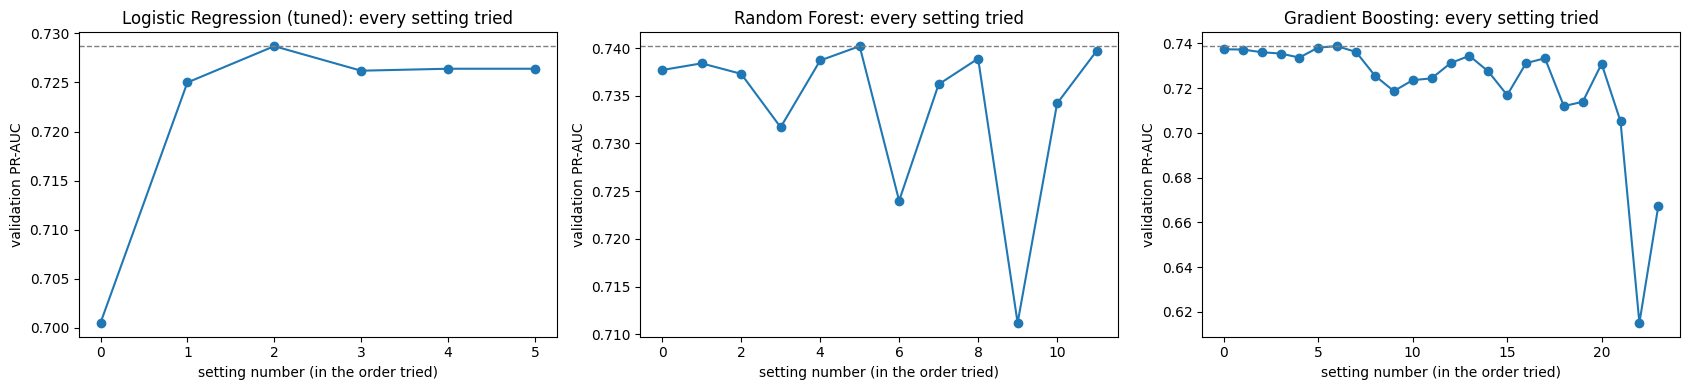

In [33]:
# 7.3 Statistical models: small grids, selected on validation PR-AUC only
best_lr, v_lr = tune('Logistic Regression (tuned)',
                     lambda C: LogisticRegression(C=C, max_iter=2000, random_state=SEED),
                     {'C': [0.001, 0.01, 0.1, 1, 10, 100]})

best_rf, v_rf = tune('Random Forest',
                     lambda max_depth, min_samples_leaf: RandomForestClassifier(
                         n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                         n_jobs=-1, random_state=SEED),
                     {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [5, 20, 50]})

best_gb, v_gb = tune('Gradient Boosting',
                     lambda learning_rate, max_depth, max_iter, l2_regularization: HistGradientBoostingClassifier(
                         learning_rate=learning_rate, max_depth=max_depth, max_iter=max_iter,
                         l2_regularization=l2_regularization, random_state=SEED),
                     {'learning_rate': [0.03, 0.1], 'max_depth': [2, 3, 5], 'max_iter': [100, 300],
                      'l2_regularization': [0.0, 1.0]})

log = pd.DataFrame(tuning_log)
for name, best, v in (('Logistic Regression (tuned)', best_lr, v_lr), ('Random Forest', best_rf, v_rf),
                      ('Gradient Boosting', best_gb, v_gb)):
    print(f"{name}: best {best} -> validation PR-AUC {v:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, ('Logistic Regression (tuned)', 'Random Forest', 'Gradient Boosting')):
    d = log[log['model'] == name].reset_index(drop=True)
    ax.plot(d.index, d['validation PR-AUC'], marker='o')
    ax.axhline(d['validation PR-AUC'].max(), color='gray', linestyle='--', linewidth=1)
    ax.set_title(f'{name}: every setting tried')
    ax.set_xlabel('setting number (in the order tried)')
    ax.set_ylabel('validation PR-AUC')
plt.tight_layout()
plt.show()

### 7.4 Shallow neural network

**[GOAL]:** Train a feed-forward neural network with one or two hidden layers on the same data.

**[LOGIC]:**
- **Library:** PyTorch (the training loop is the standard one; no custom algorithm).
- **Architecture:** inputs (19) → 1 or 2 hidden layers (ReLU, dropout) → 1 output (podium logit). Loss: binary cross-entropy.
- **Regularisation:** dropout and a small weight decay, because the network has many more parameters than a logistic regression and the training set is small.
- **Early stopping** on the validation loss (stop after 15 epochs without improvement, keep the best weights), so the number of epochs is chosen on validation, not by guessing.
- **Architecture choice:** four layouts x two dropout rates, selected on validation PR-AUC.
- **No class weights:** the probability threshold in 7.6 handles the 14% / 86% imbalance, and unweighted training keeps the probabilities closer to real podium chances.

  hidden  dropout  best epoch (weights kept)  validation PR-AUC
   (16,)      0.1                         67             0.7260
   (16,)      0.3                         67             0.7344
   (32,)      0.1                         42             0.7236
   (32,)      0.3                         58             0.7350
(32, 16)      0.1                         20             0.7362
(32, 16)      0.3                         27             0.7386
(64, 32)      0.1                         21             0.7128
(64, 32)      0.3                         19             0.7144

Best: {'hidden': (32, 16), 'dropout': 0.3}, weights kept from epoch 27, validation PR-AUC 0.739


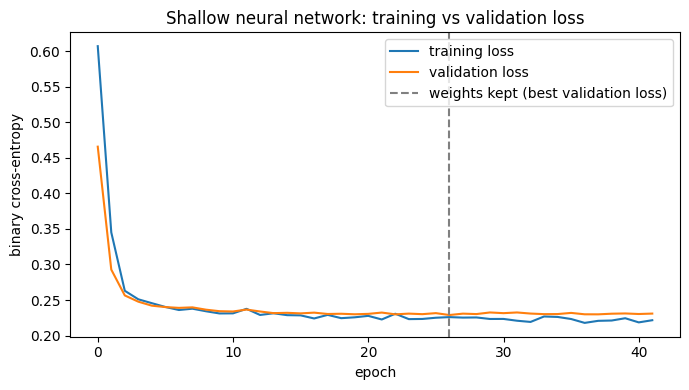

In [34]:
# 7.4 Shallow neural network (PyTorch)
import torch
import torch.nn as nn

torch.manual_seed(SEED)


class ShallowNet(nn.Module):
    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class TorchPodiumNet:
    # Wraps the network with fit / predict_proba so it is scored by the same code as the other models.
    def __init__(self, hidden=(32, 16), dropout=0.2, lr=1e-3, weight_decay=1e-4,
                 max_epochs=200, patience=15, batch_size=128, seed=SEED):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.max_epochs, self.patience, self.batch_size, self.seed = max_epochs, patience, batch_size, seed
        self.history = {'train loss': [], 'validation loss': []}

    def fit(self, X, y, X_early, y_early):
        # X_early / y_early (the validation seasons) are used ONLY to decide when to stop training.
        torch.manual_seed(self.seed)
        Xt = torch.tensor(np.asarray(X, dtype=np.float32))
        yt = torch.tensor(np.asarray(y, dtype=np.float32))
        Xe = torch.tensor(np.asarray(X_early, dtype=np.float32))
        ye = torch.tensor(np.asarray(y_early, dtype=np.float32))
        self.net = ShallowNet(Xt.shape[1], self.hidden, self.dropout)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()
        best_loss, best_state, wait = float('inf'), None, 0
        for epoch in range(self.max_epochs):
            self.net.train()
            order = torch.randperm(len(Xt))
            batch_losses = []
            for i in range(0, len(Xt), self.batch_size):
                idx = order[i:i + self.batch_size]
                opt.zero_grad()
                loss = loss_fn(self.net(Xt[idx]), yt[idx])
                loss.backward()
                opt.step()
                batch_losses.append(loss.item())
            self.net.eval()
            with torch.no_grad():
                val_loss = loss_fn(self.net(Xe), ye).item()
            self.history['train loss'].append(float(np.mean(batch_losses)))
            self.history['validation loss'].append(val_loss)
            if val_loss < best_loss - 1e-4:
                best_loss, wait = val_loss, 0
                best_state = {k: v.clone() for k, v in self.net.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        self.best_epoch = int(np.argmin(self.history['validation loss'])) + 1
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net(torch.tensor(np.asarray(X, dtype=np.float32)))).numpy()
        return np.column_stack([1 - p, p])


best_nn = None
for hidden, dropout in product([(16,), (32,), (32, 16), (64, 32)], [0.1, 0.3]):
    m = TorchPodiumNet(hidden=hidden, dropout=dropout).fit(X_train, y_train, X_val, y_val)
    v = pr_auc(y_val, proba(m, X_val))
    tuning_log.append({'model': 'Shallow Neural Network', 'hidden': hidden, 'dropout': dropout,
                       'best epoch (weights kept)': m.best_epoch, 'validation PR-AUC': round(v, 4)})
    if best_nn is None or v > best_nn[0]:
        best_nn = (v, {'hidden': hidden, 'dropout': dropout}, m)

models['Shallow Neural Network'] = best_nn[2]
print(pd.DataFrame([r for r in tuning_log if r['model'] == 'Shallow Neural Network']).drop(columns='model').to_string(index=False))
print(f"\nBest: {best_nn[1]}, weights kept from epoch {best_nn[2].best_epoch}, validation PR-AUC {best_nn[0]:.3f}")

h = best_nn[2].history
plt.figure(figsize=(7, 4))
plt.plot(h['train loss'], label='training loss')
plt.plot(h['validation loss'], label='validation loss')
plt.axvline(best_nn[2].best_epoch - 1, color='gray', linestyle='--', label='weights kept (best validation loss)')
plt.xlabel('epoch')
plt.ylabel('binary cross-entropy')
plt.title('Shallow neural network: training vs validation loss')
plt.legend()
plt.tight_layout()
plt.show()

### 7.5 How each model works and its limitations

**[GOAL]:** Explain, in plain terms, what each model does and where it can fail on this task.

| Model | How it works | Limitations here |
|---|---|---|
| **Grid-position reference** | Ranks drivers by starting position only. No learning. | Ignores car and driver strength. A fast car starting 5th scores the same as a slow car starting 5th. |
| **Logistic regression** (baseline and tuned) | Weighs each feature, adds the weights up and turns the sum into a probability (an S-shaped curve). Each weight shows how much a feature pushes the prediction. | Only straight-line effects: it cannot learn that "front row **and** top team" matters more than the two added separately, unless we build that feature. Overlapping features (grid vs qualifying, correlation 0.97) make the individual weights unstable, though predictions stay fine. |
| **Random forest** | Builds hundreds of decision trees, each on a random sample of rows and features, and averages their votes. | With 321 training races it can memorise noise. Probabilities are often squeezed toward the middle. It cannot extrapolate beyond values seen in 2003-2019, which matters because the test seasons are a new car era. |
| **Gradient boosting** | Builds small trees one after another, each fixing the mistakes of the ones before. | Most sensitive to settings and the most likely to overfit; it needs the validation seasons to pick them. Same era-shift problem as the forest. |
| **Shallow neural network** | Two small layers of weighted sums with a bend (ReLU) between them, trained step by step to reduce the prediction error. | Many more parameters than logistic regression for 6,804 rows, so it needs dropout and early stopping. Results change a little with the random seed. Hardest to explain (Objective 6 uses SHAP/LIME for that). |

**Limits shared by all models:**
- **Era shift.** The test seasons (2022-2024) are a new car-rules era, so scores can drop from validation to test even for a good model.
- **Small validation set.** Only 39 races (2020–2021), so differences of a few hundredths between models can be chance (7.6 measures this).
- **Missing information.** Weather, tyre strategy and practice pace are not in the data (6.8).

### 7.6 Comparison on training, validation and test

**[GOAL]:** Score every model with the same five metrics on all three sets and compare them side by side.

**[LOGIC]:**
- **Threshold:** for each model, the probability with the best F1 on the **validation** seasons. Each model's probabilities are computed once and reused, so the threshold and the scores always use the same numbers (the random forest adds up its trees in parallel, and recomputing could change the last digit of the one driver exactly at the threshold). The same number is then applied to train and test, so the test seasons never influence it.
- **Train vs validation** shows overfitting (a large gap). **Validation vs test** shows how well the choices carry over to unseen seasons in the newer car era.
- **Gap to the baseline, with a 95% interval:** for each model, PR-AUC minus the baseline's PR-AUC, recomputed on the same 1,000 resamples of whole races (7.1), on validation (where the choice is made) and on test.
- **Selection rule:** the baseline stays the selected model unless another trained model **clearly** beats it on validation, meaning its whole 95% interval is above 0. A more complex model has to earn its added complexity (the spec's baseline requirement). If several did, the one with the highest validation PR-AUC would be chosen. The rule itself uses only validation numbers. **It was adopted in the final revision (16 October), when an earlier version of this notebook had already shown test scores;** the rule before it, the highest validation PR-AUC, would select the random forest here (7.8 compares the two).
- **7.6 and 7.7 are the only places that report the test seasons** for the comparison; no choice is made from them.


=== train ===
                               threshold  ROC-AUC  PR-AUC     F1  Precision  Recall
model                                                                              
Reference: grid position only      0.333    0.909   0.628  0.647      0.649   0.646
Baseline: Logistic Regression      0.171    0.930   0.687  0.630      0.491   0.880
Logistic Regression (tuned)        0.169    0.930   0.686  0.629      0.489   0.882
Random Forest                      0.232    0.943   0.729  0.669      0.545   0.865
Gradient Boosting                  0.268    0.957   0.778  0.710      0.603   0.863
Shallow Neural Network             0.494    0.938   0.704  0.665      0.673   0.657

=== validation ===
                               threshold  ROC-AUC  PR-AUC     F1  Precision  Recall
model                                                                              
Reference: grid position only      0.333    0.909   0.639  0.692      0.692   0.692
Baseline: Logistic Regression      0.171 

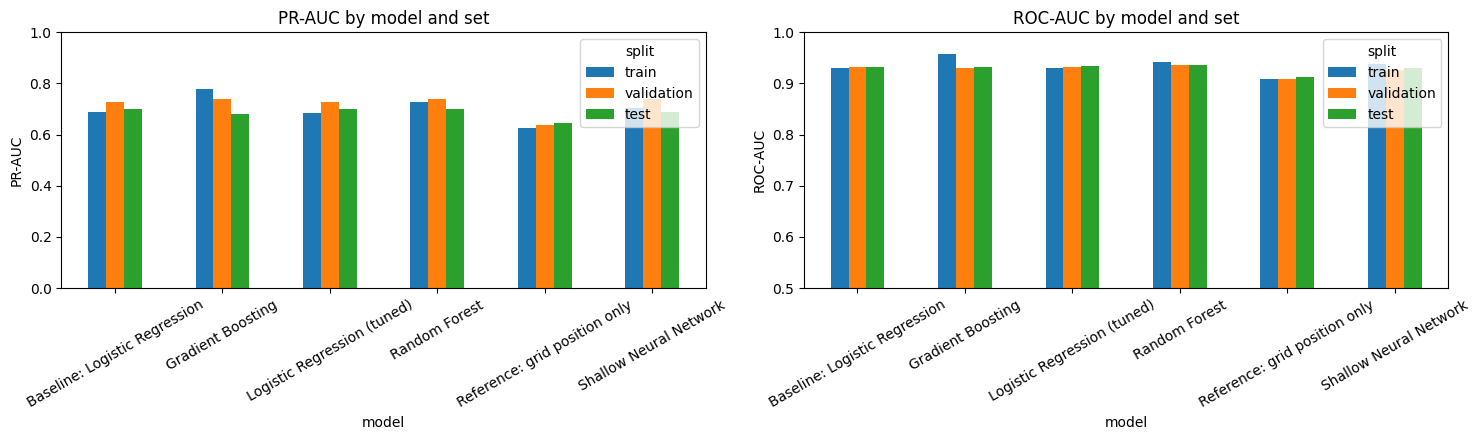

In [35]:
# 7.6 Final comparison: five metrics for every model on train, validation and test
METRICS = ['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']
rows, THRESHOLDS, PROBS = [], {}, {}
for name, m in models.items():
    probs = {split: proba(m, X) for split, (X, yy) in SPLITS.items()}  # computed once, so the threshold and the metrics use the same numbers
    PROBS[name] = probs                                                # reused below for the gap to the baseline
    THRESHOLDS[name] = best_f1_threshold(y_val, probs['validation'])   # chosen on validation only
    for split, (X, yy) in SPLITS.items():
        rows.append({'model': name, 'split': split, 'threshold': THRESHOLDS[name],
                     **all_metrics(yy, probs[split], THRESHOLDS[name])})
results = pd.DataFrame(rows)

for split in ('train', 'validation', 'test'):
    print(f"\n=== {split} ===")
    print(results[results['split'] == split].set_index('model')[['threshold'] + METRICS].round(3).to_string())

# Overfitting check: train minus validation (positive = better on training than on validation)
pivot = results.pivot(index='model', columns='split', values='PR-AUC')
print("\nPR-AUC gap, train minus validation, and validation minus test:")
print(pd.DataFrame({'train - validation': pivot['train'] - pivot['validation'],
                    'validation - test': pivot['validation'] - pivot['test']}).round(3).to_string())

# Is a model's lead over the baseline larger than chance? Resample whole races 1,000 times (7.1) and recompute
# PR-AUC(model) minus PR-AUC(baseline) on the same resampled races; the 95% interval is the middle 95% of them.
BASELINE = 'Baseline: Logistic Regression'
gap = {name: {} for name in models if name != BASELINE}
VAL_LOW = {}  # lower end of each model's validation interval, used by the selection rule below
for split in ('validation', 'test'):
    X, yy = SPLITS[split]
    yv, boot, p_base = yy.to_numpy(), race_resamples(X), PROBS[BASELINE][split]
    base = [pr_auc(yv[i], p_base[i]) for i in boot]
    for name in gap:
        p = PROBS[name][split]
        d = [pr_auc(yv[i], p[i]) - b for i, b in zip(boot, base)]
        lo, hi = np.percentile(d, [2.5, 97.5])
        gap[name][f'{split}: minus baseline'] = round(pr_auc(yv, p) - pr_auc(yv, p_base), 3)
        gap[name][f'{split}: 95% interval'] = f"{lo:+.3f} to {hi:+.3f}"
        if split == 'validation':
            VAL_LOW[name] = lo
print("\nPR-AUC minus the baseline's, with a 95% interval from resampling whole races:")
print(pd.DataFrame(gap).T.to_string())

# Selection rule: keep the simplest model, the baseline, unless another trained model CLEARLY beats it on validation,
# i.e. its whole 95% interval is above 0. A more complex model has to earn its added complexity (the spec's baseline
# requirement). Validation only: the test seasons play no part in the choice.
val_scores = results[(results['split'] == 'validation') & (results['model'] != 'Reference: grid position only')]
top_name = val_scores.sort_values('PR-AUC', ascending=False).iloc[0]['model']
clearly_better = [n for n in VAL_LOW if n != 'Reference: grid position only' and VAL_LOW[n] > 0]
if clearly_better:
    BEST_NAME = val_scores[val_scores['model'].isin(clearly_better)].sort_values('PR-AUC', ascending=False).iloc[0]['model']
else:
    BEST_NAME = BASELINE
BEST_MODEL = models[BEST_NAME]
print(f"\nHighest validation PR-AUC: {top_name}. Clearly better than the baseline: {clearly_better if clearly_better else 'none'}")
print(f"Selected model: {BEST_NAME} (threshold {THRESHOLDS[BEST_NAME]:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ('PR-AUC', 'ROC-AUC')):
    results.pivot(index='model', columns='split', values=metric)[['train', 'validation', 'test']].plot.bar(ax=ax, rot=30)
    ax.set_title(f'{metric} by model and set')
    ax.set_ylabel(metric)
    ax.set_ylim(0.5 if metric == 'ROC-AUC' else 0.0, 1.0)
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Baseline vs the grid-only reference:** the baseline logistic regression scores validation ROC-AUC 0.931 / PR-AUC 0.726, against 0.909 / 0.639 for the grid-only rule. On the test seasons it is 0.933 / 0.700 against 0.914 / 0.647. The interval table confirms the 19 features are a real gain: the grid-only rule is the only model clearly worse than the baseline (−0.088 on validation, interval −0.136 to −0.043; −0.053 on test, −0.098 to −0.004).
- **No trained model clearly beats the baseline.** On validation the random forest scores 0.740, gradient boosting and the network 0.739, the tuned logistic regression (C = 0.1) 0.729, against 0.726 for the baseline. Their leads all have 95% intervals that include 0 (random forest +0.014, −0.026 to +0.059; gradient boosting +0.013, −0.027 to +0.056; network +0.012, −0.021 to +0.054; tuned logistic regression +0.003, −0.005 to +0.012). So, by the rule above, **the selected model is the baseline logistic regression** (threshold 0.171).
- **Overfitting:** gradient boosting scores clearly better on training than on validation (0.778 vs 0.739, +0.039) and falls to 0.683 on test. The random forest, whose chosen setting is small (depth 5, at least 50 rows per leaf), scores lower on training than on validation (−0.011), like the logistic regressions (−0.039 and −0.043) and the network (−0.035): the validation seasons happen to be easier, so these gaps are no proof of "no overfitting".
- **Test seasons (2022–2024):** the random forest and the tuned logistic regression score 0.702, the baseline 0.700, the network 0.690, gradient boosting 0.683 and the grid-only rule 0.647. Every trained model drops from validation to test, the flexible ones most (gradient boosting 0.056, network 0.049, random forest 0.038, logistic regressions 0.026–0.027), which fits the era-shift limitation (6.8); the grid-only rule rises by 0.009. On test too, every trained model's interval against the baseline includes 0 (random forest +0.002, −0.020 to +0.028; gradient boosting −0.018, −0.043 to +0.015).
- **Thresholds:** the F1-optimal thresholds are between 0.17 and 0.49, mostly well below 0.5, because podiums are rare (~15%). The two logistic regressions have the lowest (0.169 tuned, 0.171 baseline), so they say "podium" more often: the baseline's validation recall is 0.863 at precision 0.605.


### 7.7 Curves and confusion matrices

**[GOAL]:** Show how the models behave across all thresholds, and what the chosen threshold does on the test seasons.

**[LOGIC]:** ROC curves show the overall separation between podium and non-podium. Precision-recall curves show the trade-off for the rare podium class. The confusion matrices show the real counts at the validation-chosen threshold on the **test** seasons.

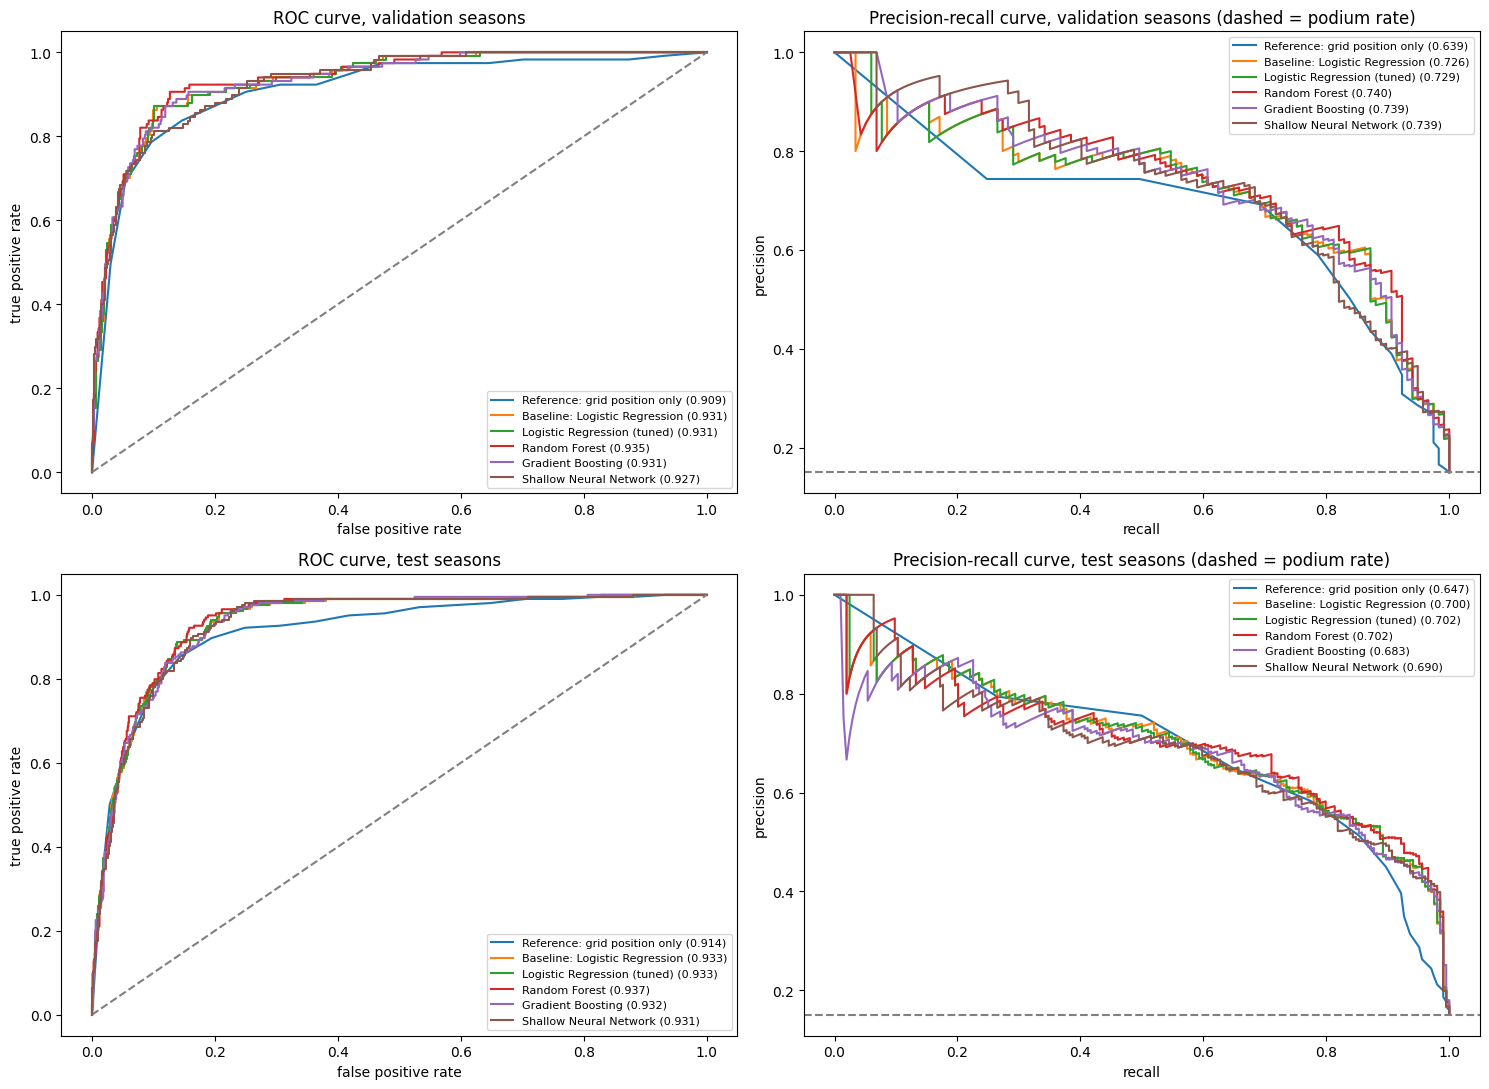

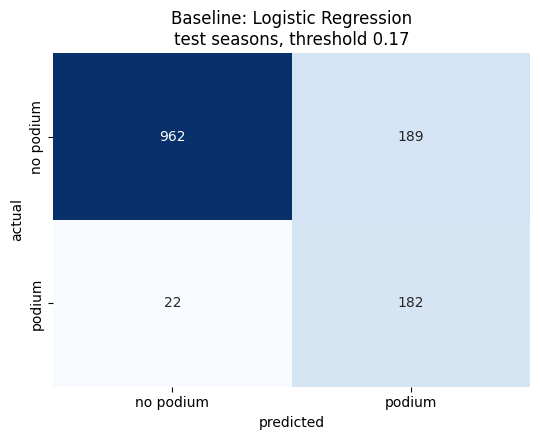

In [36]:
# 7.7 ROC and precision-recall curves (validation and test), and confusion matrices on the test seasons
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for row, split in enumerate(('validation', 'test')):
    X, yy = SPLITS[split]
    for name, m in models.items():
        p = proba(m, X)
        fpr, tpr, _ = roc_curve(yy, p)
        prec, rec, _ = precision_recall_curve(yy, p)
        axes[row, 0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(yy, p):.3f})")
        axes[row, 1].plot(rec, prec, label=f"{name} ({pr_auc(yy, p):.3f})")
    axes[row, 0].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axes[row, 0].set(title=f'ROC curve, {split} seasons', xlabel='false positive rate', ylabel='true positive rate')
    axes[row, 1].axhline(yy.mean(), color='gray', linestyle='--')
    axes[row, 1].set(title=f'Precision-recall curve, {split} seasons (dashed = podium rate)', xlabel='recall', ylabel='precision')
    axes[row, 0].legend(fontsize=8, loc='lower right')
    axes[row, 1].legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

show = ['Baseline: Logistic Regression', BEST_NAME] if BEST_NAME != 'Baseline: Logistic Regression' else [BEST_NAME]
fig, axes = plt.subplots(1, len(show), figsize=(5.5 * len(show), 4.5))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, show):
    pred = (proba(models[name], X_test) >= THRESHOLDS[name]).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
    ax.set(title=f'{name}\ntest seasons, threshold {THRESHOLDS[name]:.2f}', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Curves:** the ROC and precision-recall curves of the five trained models almost overlap on both validation and test; only the grid-only rule falls visibly below, most clearly in the ROC curve at false-positive rates above about 0.2 and in the precision-recall curve at high recall (above about 0.8). This matches the small PR-AUC differences in 7.6.
- **Test confusion matrix:** the selected model is the baseline, so one matrix is shown. Of the 204 real podium finishers in 2022–2024, it finds **182** (recall 0.89), misses 22 and wrongly flags **189** non-podium drivers (precision 0.49) at its threshold of 0.17. The low threshold is the F1-best one on validation: it trades many false alarms for catching almost every podium finisher.


### 7.8 Metric choice, model choice and hand-off to Objectives 5-6

**Primary metric: PR-AUC.**
- Only ~14% of rows are podiums (3 of ~21 drivers per race), so a model that predicts "no podium" for everyone is already 86% accurate. Accuracy would hide that.
- ROC-AUC counts the many easy non-podium drivers as true negatives, which makes every model look good (the grid-only rule already scores about 0.9 in 6.4). PR-AUC looks only at how well the model ranks the real podium finishers near the top, which is the actual job.
- It needs no threshold, so it can be used to pick hyperparameters and the best model fairly.

**Secondary metric: ROC-AUC.** It is the standard overall-separation score and lets us compare with the 6.4 single-feature evidence. It is secondary because it is insensitive to class imbalance.

**Reported but not used for selection: F1, precision and recall.** They depend on one threshold, which is itself tuned on the validation seasons. They show what a real yes/no decision would look like (how many podium finishers are caught and how many false alarms), but are noisier with only 39 validation races.

**Model choice: the baseline logistic regression.** The rule (7.6) keeps the simplest model unless another clearly beats it on validation. The random forest, gradient boosting and the network score 0.012–0.014 higher on validation, but each 95% interval includes 0, so none clearly earns its extra complexity. A logistic regression is also the easiest model to explain: each feature has one weight.

**How this rule came about, stated openly.** Until the final revision the rule was "highest validation PR-AUC". It was replaced on 16 October, after an earlier version of this notebook had already shown test scores, by the rule above, which follows the spec's baseline requirement (a more complex model has to earn its complexity). The old rule would select the random forest. On the test seasons the forest scores 0.702 and the baseline 0.700, a gap of +0.002 whose interval (−0.020 to +0.028) includes 0, so the two choices cannot be told apart on unseen seasons either.

**Hand-off.** `models`, `BEST_NAME`, `BEST_MODEL` and `THRESHOLDS` are used by Objective 5 (the ablation retrains the selected model once per removed feature group, with the same settings) and Objective 6 (permutation importance, SHAP and LIME on the selected model). `BEST_MODEL` and `THRESHOLDS[BEST_NAME]` also score new races in Section 10 (the inference function).


## Section 8: Objective 5 - Feature-Group Ablation

**[GOAL]:** Measure how much each of the six feature groups (6.3) really contributes to the selected model. 6.4 justified each feature *before* training with single-feature evidence; the ablation measures each group's contribution *after* training, inside the full model.

**[LOGIC]:**
- **What an ablation is:** remove one group of features, retrain the same model on the same rows, and see how much the score drops. A large drop means the model needs that group; no drop means the other groups can replace it.
- **Same model, same settings, same rows.** Every run retrains the model chosen in 7.6 (`BEST_NAME`, the baseline logistic regression) with the same settings (C = 1), on the same training seasons. Only the list of features changes, so any change in score comes from the removed group.
- **Order of the work:** 8.1 runs every ablation, prints the table and draws the chart.

### 8.1 Without one group, and only one group

**[GOAL]:** Retrain the selected model once per feature group, without it and with it alone, and score every run the same way.

**[LOGIC]:**
- **Two views.** *Without one group* (train on the other five) shows what is lost when the group is missing. *Only one group* (train on that group alone) shows what the group can do by itself. A group can be strong alone but cost little when dropped, if another group carries the same information.
- **Grid and qualifying together.** Grid and qualifying position correlate at 0.97 (6.4), so each can stand in for the other. One extra run drops both groups at once.
- **`clone`** copies the selected model's settings without what it learned, so every run starts from scratch with identical settings. A reference run with all 19 features must reproduce the 7.6 score.
- **Scored on the validation seasons**, where every choice is made, with the two threshold-free metrics (ROC-AUC and PR-AUC), so no threshold has to be re-tuned for each run. The test seasons are shown only as a check.
- **Is a drop real or noise?** Validation has only 39 races. For each run we resample the 39 validation races with replacement 1,000 times (`race_resamples`, 7.1) (whole races, because drivers in one race compete with each other) and recompute the PR-AUC lost. If the 95% interval stays above 0, the group really helps on these seasons.

Model retrained in every run: Baseline: Logistic Regression, with its settings: {'C': 1.0, 'max_iter': 1000}
Check: the reference run reproduces 7.6 (validation PR-AUC 0.726, ROC-AUC 0.931)

                           features  val ROC-AUC  val ROC-AUC lost  val PR-AUC  val PR-AUC lost val PR-AUC lost, 95% interval  test PR-AUC  test PR-AUC lost
run                                                                                                                                                         
all features (reference)         19        0.931             0.000       0.726            0.000                                      0.700             0.000
without grid                     17        0.929             0.002       0.719            0.007              -0.012 to +0.032        0.689             0.011
without qualifying               17        0.928             0.004       0.715            0.011              -0.007 to +0.028        0.699             0.002
without standings       

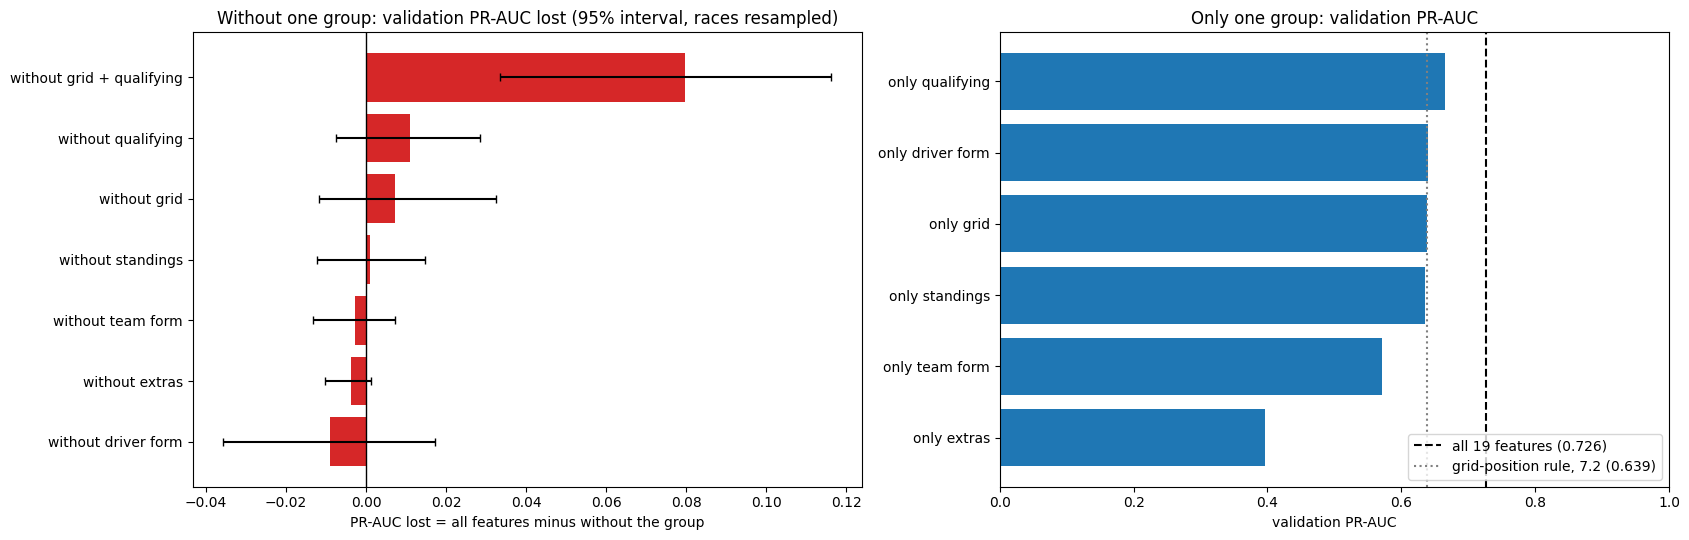

In [37]:
# 8.1 Feature-group ablation: retrain the selected model without each group, and with each group alone
from sklearn.base import clone

SHOWN = ('learning_rate', 'max_depth', 'max_iter', 'l2_regularization', 'C', 'n_estimators', 'min_samples_leaf')
print(f"Model retrained in every run: {BEST_NAME}, with its settings: "
      f"{ {k: v for k, v in BEST_MODEL.get_params().items() if k in SHOWN} }")


def fit_on(features):
    """A fresh copy of the selected model (same settings), trained on the given feature columns only."""
    return clone(BEST_MODEL).fit(X_train[features], y_train)


# Bootstrap over whole validation races (helper from 7.1): 1,000 resamples of the validation races, drawn once and reused for every run
BOOT = race_resamples(X_val)


def drop_interval(p_full, p_run):
    """95% interval of PR-AUC(all features) - PR-AUC(this run) over the resampled validation races."""
    yv = y_val.to_numpy()
    d = [pr_auc(yv[i], p_full[i]) - pr_auc(yv[i], p_run[i]) for i in BOOT]
    return np.percentile(d, [2.5, 97.5])


runs = {'all features (reference)': FEATURES}
for g, cols in FEATURE_GROUPS.items():
    runs[f'without {g}'] = [f for f in FEATURES if f not in cols]
both = FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying']
runs['without grid + qualifying'] = [f for f in FEATURES if f not in both]
for g, cols in FEATURE_GROUPS.items():
    runs[f'only {g}'] = list(cols)

rows, val_p = [], {}
for name, cols in runs.items():
    m = fit_on(cols)
    pv, pt = m.predict_proba(X_val[cols])[:, 1], m.predict_proba(X_test[cols])[:, 1]
    val_p[name] = pv
    rows.append({'run': name, 'features': len(cols),
                 'val ROC-AUC': roc_auc_score(y_val, pv), 'val PR-AUC': pr_auc(y_val, pv),
                 'test ROC-AUC': roc_auc_score(y_test, pt), 'test PR-AUC': pr_auc(y_test, pt)})
ablation = pd.DataFrame(rows).set_index('run')
ref = ablation.loc['all features (reference)']
for s in ('val', 'test'):
    ablation[f'{s} ROC-AUC lost'] = ref[f'{s} ROC-AUC'] - ablation[f'{s} ROC-AUC']
    ablation[f'{s} PR-AUC lost'] = ref[f'{s} PR-AUC'] - ablation[f'{s} PR-AUC']
DROP_CI = {name: drop_interval(val_p['all features (reference)'], val_p[name]) for name in runs if name.startswith('without')}
ablation['val PR-AUC lost, 95% interval'] = (pd.Series({k: f"{lo:+.3f} to {hi:+.3f}" for k, (lo, hi) in DROP_CI.items()})
                                            .reindex(ablation.index).fillna(''))

print(f"Check: the reference run reproduces 7.6 (validation PR-AUC {ref['val PR-AUC']:.3f}, ROC-AUC {ref['val ROC-AUC']:.3f})\n")
cols_shown = ['features', 'val ROC-AUC', 'val ROC-AUC lost', 'val PR-AUC', 'val PR-AUC lost',
              'val PR-AUC lost, 95% interval', 'test PR-AUC', 'test PR-AUC lost']
with pd.option_context('display.width', 250, 'display.max_columns', 20):
    print(ablation[cols_shown].round(3).to_string())

# Left: what is lost without each group (with the 95% interval). Right: what each group does alone.
without = ablation.loc[[n for n in runs if n.startswith('without')]].sort_values('val PR-AUC lost')
alone = ablation.loc[[n for n in runs if n.startswith('only')]].sort_values('val PR-AUC')
lost = without['val PR-AUC lost'].to_numpy()
lo = np.array([DROP_CI[n][0] for n in without.index])
hi = np.array([DROP_CI[n][1] for n in without.index])
grid_rule = results[(results['model'] == 'Reference: grid position only') & (results['split'] == 'validation')]['PR-AUC'].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
axes[0].barh(without.index, lost, xerr=[np.clip(lost - lo, 0, None), np.clip(hi - lost, 0, None)],
             color='tab:red', capsize=3)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(title='Without one group: validation PR-AUC lost (95% interval, races resampled)',
            xlabel='PR-AUC lost = all features minus without the group')
axes[1].barh(alone.index, alone['val PR-AUC'], color='tab:blue')
axes[1].axvline(ref['val PR-AUC'], color='black', linestyle='--', label=f"all 19 features ({ref['val PR-AUC']:.3f})")
axes[1].axvline(grid_rule, color='gray', linestyle=':', label=f"grid-position rule, 7.2 ({grid_rule:.3f})")
axes[1].set(title='Only one group: validation PR-AUC', xlabel='validation PR-AUC', xlim=(0, 1))
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Check:** the reference run with all 19 features reproduces 7.6 exactly (validation PR-AUC 0.726, ROC-AUC 0.931).
- **Starting position is what the model cannot do without.** Dropping grid **and** qualifying together costs 0.080 validation PR-AUC (0.726 → 0.646, 95% interval +0.034 to +0.116) and 0.117 on the test seasons (0.700 → 0.583). It is the only loss whose interval stays above 0.
- **No single group is needed on its own.** Dropping qualifying costs 0.011 (interval −0.007 to +0.028), grid 0.007 (−0.012 to +0.032) and standings 0.001 (−0.012 to +0.015): none can be told apart from noise, because the other groups carry overlapping information (grid and qualifying correlate at 0.97, 6.4).
- **Dropping form or extras even raises the score slightly:** driver form −0.009 (interval −0.036 to +0.017), team form −0.003 (−0.013 to +0.007), extras −0.004 (−0.010 to +0.001). Every interval includes 0, so these are noise, not proof that the groups hurt.
- **Alone, most groups are strong:** qualifying alone scores 0.666, driver form 0.640, grid 0.639 (the same as the grid-position rule in 7.2), standings 0.635 and team form 0.571. Only the extras are weak alone (0.396; a random ranking would score about 0.15, the podium rate). So each group carries real signal, but much of it is shared: a fast car shows up in the grid, the standings and the form.
- **ROC-AUC hardly reacts:** dropping a single group changes validation ROC-AUC by at most 0.004, and grid + qualifying by 0.028, while PR-AUC moves by up to 0.080. This supports PR-AUC as the primary metric (7.8).
- **Test seasons, as a check:** the same picture. Grid + qualifying is the only large loss (0.117); for single groups the test PR-AUC lost is between −0.011 and +0.011.
- **Decision:** all 19 features are kept. No single group changes the validation score by more than chance in either direction, and every group except the extras carries real signal on its own (6.4).


## Section 9: Objective 6 - Model Explainability (XAI)

**[GOAL]:** Explain what the selected model (the baseline logistic regression, 7.6) relies on: **globally**, across all drivers, with permutation importance and SHAP; and **locally**, for one single prediction, with SHAP and LIME.

**[LOGIC]:**
- **Importance is not causation.** Every method below measures what the *model* uses to make its predictions. A feature that is important to the model is not proof that it *causes* podium finishes. For example, a high championship position does not make a driver finish on the podium; it is a sign of a fast car and driver, and the model uses it as a clue. 9.5 comes back to this.
- **Data used:** the global explanations use the validation seasons (2020–2021), the same data used for every choice. The local example comes from the test seasons, which is fine because explaining a prediction does not choose anything.
- **Order of the work:** 9.1 permutation importance → 9.2 SHAP (global) → 9.3 one prediction explained with SHAP and LIME → 9.4 do the methods agree? → 9.5 what the explanations do and do not show.
- **Libraries:** `shap` and `lime` are preinstalled on Kaggle; the next cell installs them only if they are missing.

In [38]:
# 9.0 Libraries for the explanations (preinstalled on Kaggle; installed here only if missing)
import importlib.util
import subprocess
import sys

for pkg in ('shap', 'lime'):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance

print('shap', shap.__version__)

shap 0.52.0


### 9.1 Permutation importance (global)

**[GOAL]:** Measure how much the selected model's validation score depends on each feature.

**[LOGIC]:**
- **How it works:** shuffle one feature's values across the validation rows, so they no longer belong to the right driver, and measure how much validation PR-AUC falls. A large fall means the model relies on that feature. Each feature is shuffled 20 times and the falls are averaged.
- **Model not retrained.** Unlike the ablation (8.1), the trained model stays the same; only its input is scrambled.
- **Whole groups too.** Grid and qualifying position (0.97) and championship position and points share (−0.95) carry the same information (6.4). Shuffling one feature of such a pair can look harmless, because the model still sees its partner. So each whole group is also shuffled at once (all its columns move together).

Validation PR-AUC of Baseline: Logistic Regression with nothing shuffled: 0.726

One feature shuffled at a time:
                                  group  PR-AUC lost (mean)     std
grid_pos                           grid              0.0782  0.0298
quali_pos                    qualifying              0.0451  0.0237
drv_form_podium_rate        driver form              0.0254  0.0220
team_form_avg_best_finish     team form              0.0242  0.0173
quali_gap_pct                qualifying              0.0161  0.0169
team_form_dnf_rate            team form              0.0083  0.0078
pit_lane_start                     grid              0.0057  0.0069
team_form_podiums_per_race    team form              0.0051  0.0077
drv_form_dnf_rate           driver form              0.0027  0.0059
is_rookie                   driver form              0.0023  0.0080
circuit_podium_rate              extras              0.0004  0.0012
first_race_of_season          standings              0.0004  0.0040
tea

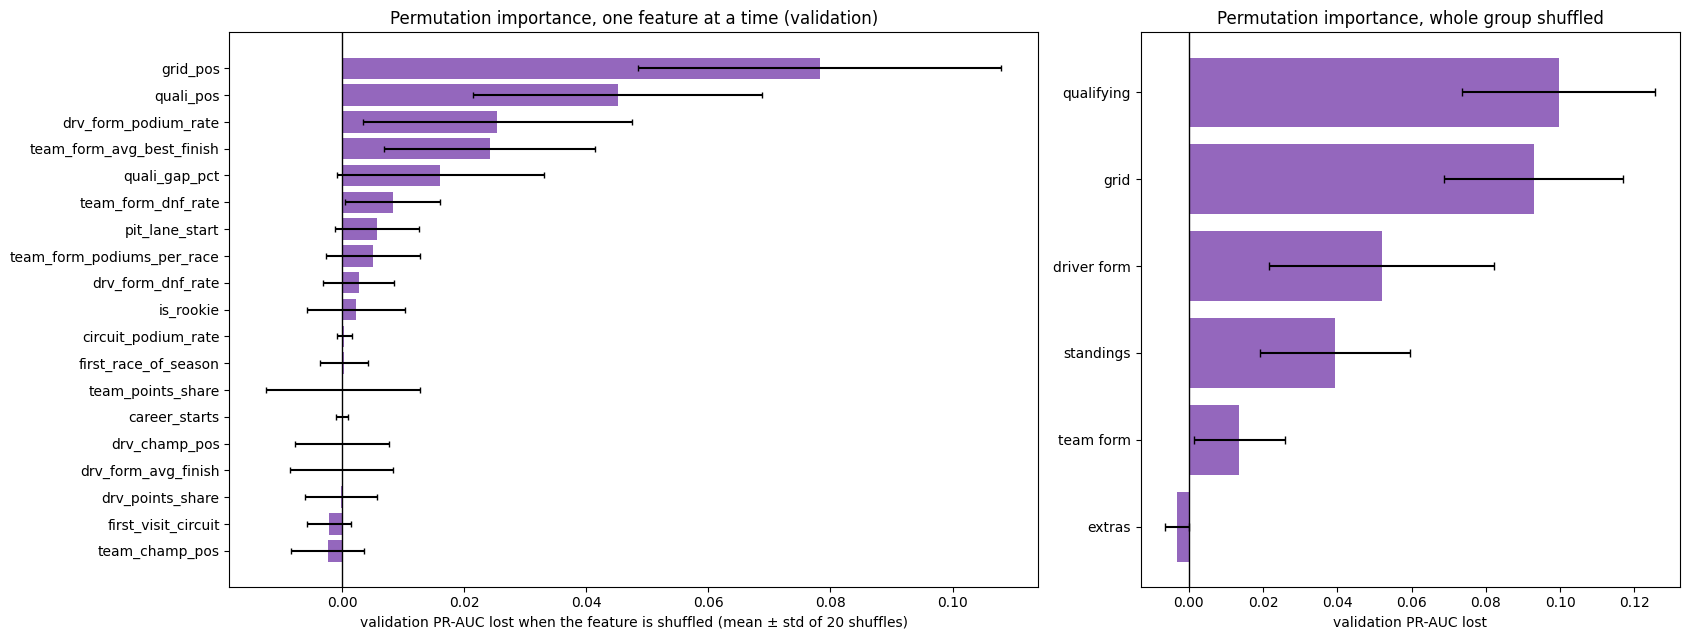

In [39]:
# 9.1 Permutation importance on the validation seasons (score = PR-AUC, 20 shuffles each)
base_pr = pr_auc(y_val, proba(BEST_MODEL, X_val))
perm = permutation_importance(BEST_MODEL, X_val, y_val, scoring='average_precision',
                              n_repeats=20, random_state=SEED, n_jobs=-1)
GROUP_OF = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
perm_table = (pd.DataFrame({'group': [GROUP_OF[f] for f in FEATURES],
                            'PR-AUC lost (mean)': perm.importances_mean, 'std': perm.importances_std}, index=FEATURES)
              .sort_values('PR-AUC lost (mean)', ascending=False))

# Whole groups: the group's columns are shuffled together, as one block of rows
rng = np.random.default_rng(SEED)
group_rows = []
for g, cols in FEATURE_GROUPS.items():
    lost = []
    for _ in range(20):
        shuffled = X_val.copy()
        shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]
        lost.append(base_pr - pr_auc(y_val, proba(BEST_MODEL, shuffled)))
    group_rows.append({'group': g, 'PR-AUC lost (mean)': np.mean(lost), 'std': np.std(lost)})
group_perm = pd.DataFrame(group_rows).set_index('group').sort_values('PR-AUC lost (mean)', ascending=False)

print(f"Validation PR-AUC of {BEST_NAME} with nothing shuffled: {base_pr:.3f}\n")
print("One feature shuffled at a time:")
print(perm_table.round(4).to_string())
print("\nWhole group shuffled at once:")
print(group_perm.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [3, 2]})
pt = perm_table.iloc[::-1]
axes[0].barh(pt.index, pt['PR-AUC lost (mean)'], xerr=pt['std'], color='tab:purple', capsize=2)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(title='Permutation importance, one feature at a time (validation)',
            xlabel='validation PR-AUC lost when the feature is shuffled (mean ± std of 20 shuffles)')
gp = group_perm.iloc[::-1]
axes[1].barh(gp.index, gp['PR-AUC lost (mean)'], xerr=gp['std'], color='tab:purple', capsize=3)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set(title='Permutation importance, whole group shuffled', xlabel='validation PR-AUC lost')
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **Starting point:** validation PR-AUC 0.726 with nothing shuffled (the 7.6 score).
- **One feature at a time:** grid position matters most (shuffling it costs 0.078 ± 0.030), then qualifying position (0.045 ± 0.024), driver-form podium rate (0.025 ± 0.022), team form best finish (0.024 ± 0.017) and qualifying gap (0.016 ± 0.017). Every other feature costs 0.008 or less, within about one standard deviation of 0, and a few are slightly negative (team championship position −0.002, first visit −0.002), which is noise. In a logistic regression every feature has a weight, so none is exactly 0.
- **Whole groups:** qualifying 0.100 ± 0.026, grid 0.093 ± 0.024, driver form 0.052 ± 0.030, standings 0.039 ± 0.020, team form 0.014 ± 0.012, extras −0.003. Shuffling the whole standings group costs 0.039, although no standings feature alone costs more than 0.001: championship position and points share stand in for each other, so the information only shows when both are scrambled.
- **Permutation vs ablation:** scrambling qualifying in the trained model costs 0.100, but dropping it and retraining costs only 0.011 (8.1). The trained model does use qualifying; a model retrained without it gets the same information from grid position. Both are correct: they answer different questions.


### 9.2 SHAP (global)

**[GOAL]:** Show, for every validation prediction, how much each feature pushed it towards or away from a podium, and which features matter most overall.

**[LOGIC]:**
- **How it works:** SHAP splits every single prediction into one contribution per feature. The contributions start from the model's average output and add up exactly to the prediction, so nothing is left unexplained. A positive value pushes towards a podium, a negative one away.
- **`LinearExplainer`** is the exact SHAP method for a linear model such as logistic regression: a feature's contribution is its weight × (its value − the training average). The values are in **log-odds**, the model's internal score before it is turned into a probability (0 log-odds = 50%).
- **Two charts.** The *beeswarm* shows every driver-race as a dot: its position is the SHAP value, its colour the feature's real value (red = high, blue = low), so it shows the direction of each effect. The *bar chart* shows the average size of each feature's contribution.
- **Readable colours:** the dots are coloured by the real, unscaled values from `model_df` (grid places, points share), not the rescaled ones the model sees.
- **Check:** average output + contributions must equal the model's own output for every row.

Average output on the training rows: -3.91 log-odds (= the intercept -3.91, because every feature has mean 0 after 6.5)
Check: base value + contributions = the model's own output (largest difference 3.6e-15)


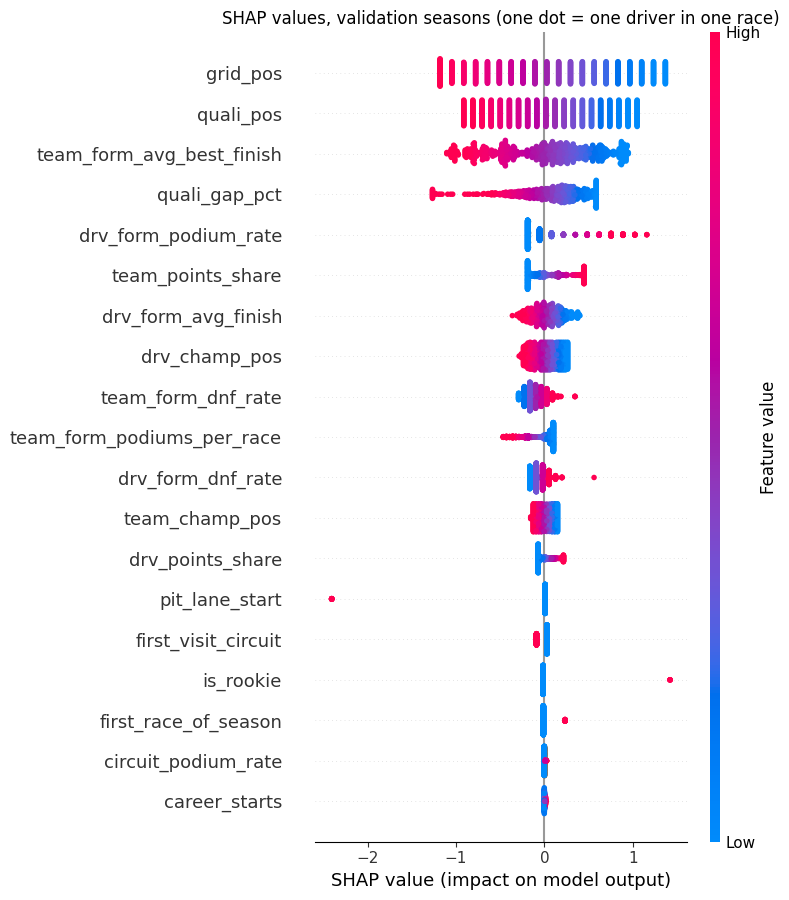

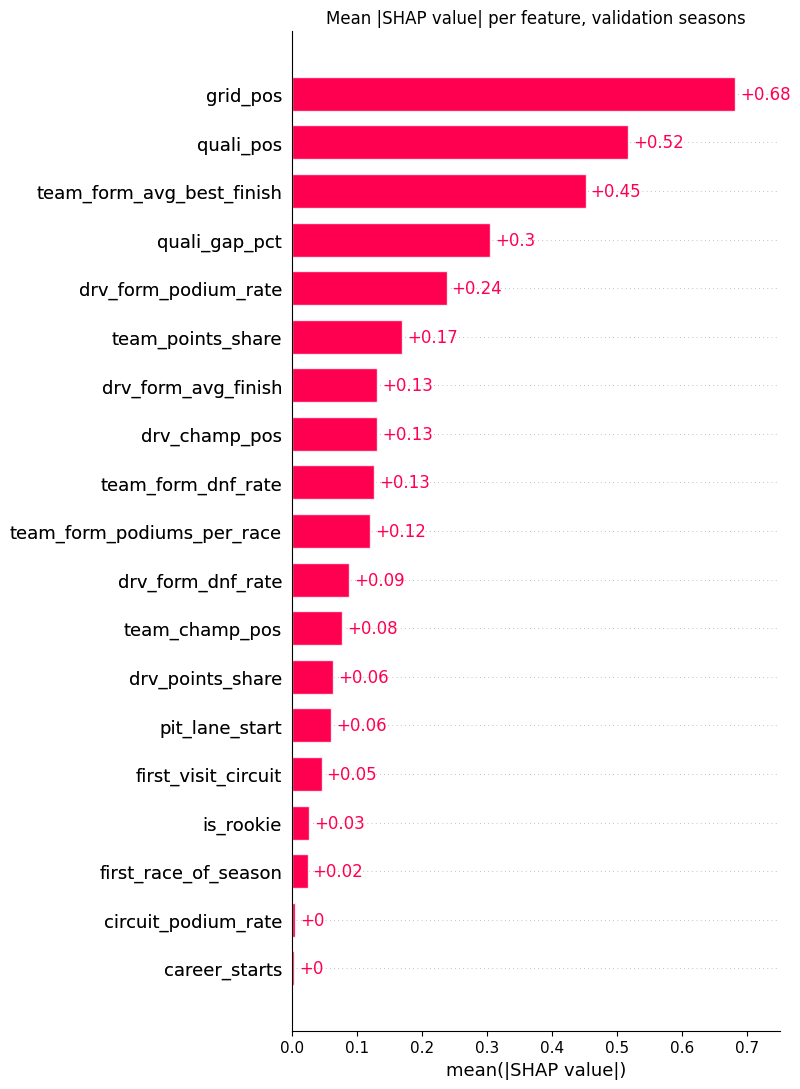

Mean |SHAP value| (log-odds), largest first:
grid_pos                      0.680
quali_pos                     0.517
team_form_avg_best_finish     0.451
quali_gap_pct                 0.304
drv_form_podium_rate          0.238
team_points_share             0.170
drv_form_avg_finish           0.131
drv_champ_pos                 0.131
team_form_dnf_rate            0.126
team_form_podiums_per_race    0.120
drv_form_dnf_rate             0.087
team_champ_pos                0.077
drv_points_share              0.064
pit_lane_start                0.060
first_visit_circuit           0.046
is_rookie                     0.027
first_race_of_season          0.024
circuit_podium_rate           0.004
career_starts                 0.004


In [40]:
# 9.2 SHAP for every validation row (LinearExplainer = exact for a logistic regression; values in log-odds)
assert isinstance(BEST_MODEL, LogisticRegression), "9.2-9.3 are written for the linear model selected in 7.6"
masker = shap.maskers.Independent(X_train, max_samples=len(X_train))  # all training rows (the default keeps only 100)
explainer = shap.LinearExplainer(BEST_MODEL, masker)
BASE_VALUE = float(np.ravel(explainer.expected_value)[-1])   # average model output (log-odds) on the training rows


def shap_values(X):
    v = explainer.shap_values(X)
    v = v[1] if isinstance(v, list) else v                    # some shap versions return one array per class
    return v[:, :, 1] if v.ndim == 3 else v


sv_val = shap_values(X_val)
print(f"Average output on the training rows: {BASE_VALUE:.2f} log-odds "
      f"(= the intercept {BEST_MODEL.intercept_[0]:.2f}, because every feature has mean 0 after 6.5)")
raw_val = model_df.loc[X_val.index, FEATURES]                 # real (unscaled) values, so colours and axes are readable
gap = np.abs(BASE_VALUE + sv_val.sum(axis=1) - BEST_MODEL.decision_function(X_val)).max()
print(f"Check: base value + contributions = the model's own output (largest difference {gap:.1e})")

val_expl = shap.Explanation(values=sv_val, base_values=np.full(len(sv_val), BASE_VALUE),
                            data=raw_val.to_numpy(dtype=float), feature_names=FEATURES)
shap.plots.beeswarm(val_expl, max_display=len(FEATURES), show=False)
plt.title('SHAP values, validation seasons (one dot = one driver in one race)')
plt.tight_layout()
plt.show()

shap.plots.bar(val_expl, max_display=len(FEATURES), show=False)
plt.title('Mean |SHAP value| per feature, validation seasons')
plt.tight_layout()
plt.show()

shap_mean = pd.Series(np.abs(sv_val).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("Mean |SHAP value| (log-odds), largest first:")
print(shap_mean.round(3).to_string())

**[OBSERVATION]:**
- **Check passed:** average output + contributions equals the model's own output for every validation row (largest difference 3.6e-15). The average output on the training rows is −3.91 log-odds, the model's intercept, because every feature has mean 0 after 6.5.
- **Largest average contributions (log-odds):** grid position 0.680, qualifying position 0.517, team form best finish 0.451, qualifying gap 0.304, driver-form podium rate 0.238 and team points share 0.170. Then driver average finish and driver championship position (0.131 each), team retirement rate 0.126 and team podiums per race 0.120. Career starts and circuit podium rate (0.004 each) barely move any prediction.
- **Directions (beeswarm):** a front grid or qualifying position (low values, blue) pushes towards a podium by up to about +1.3, a position at the back away by up to about −1.2. A good team best finish (low), a small gap to the fastest qualifier, a high recent podium rate and a high team points share all push up, as expected in F1. A pit-lane start pushes down by about −2.4.
- **Two surprising signs:** a high team podiums-per-race value pushes *down* (to about −0.5), and the rookie flag pushes *up* (about +1.4). In a linear model, overlapping features share and trade credit: team strength is already carried by team best finish and team points share, so the third team feature ends up correcting them, and the rookie flag offsets the median values filled in for a rookie's missing form (6.5). This is the "single weights are unstable" limitation from 7.5; the predictions themselves are not affected.
- **SHAP vs permutation:** both rank grid position first and qualifying position second. SHAP then ranks team form best finish, permutation driver podium rate (0.025 against 0.024 for team best finish). SHAP counts every push a feature gives a prediction; permutation counts only the pushes that change how the podium finishers are ranked, which is what PR-AUC measures.


### 9.3 Local explanation: one driver, SHAP and LIME

**[GOAL]:** Explain one single prediction, so we can see why the model gave that driver that chance.

**[LOGIC]:**
- **Which prediction:** a rule fixed in advance, in the code: among drivers in the test seasons who started outside the top 3 and did finish on the podium, the one the model was most sure about. It is a non-obvious call, so the explanation has to show more than "started at the front".
- **SHAP waterfall:** starts from the model's average output and adds each feature's contribution for this one driver, largest first, until it reaches this prediction.
- **LIME:** makes 5,000 random rows, each feature drawn from the training data (a quartile range for numbers, an observed value for flags), asks the model about each, and fits a small straight-line model to its answers, giving the most weight to the rows that look most like this driver. Its weights are read as "this condition raised (or lowered) the podium chance by this much". LIME works in real units (grid places, points share), so the model sees each copy after the same preparation as in 6.5.
- **Why both:** they are built in completely different ways. If they point to the same features, the explanation is more trustworthy. The spec asks for LIME and/or local SHAP; we show both.

Explained prediction: max_verstappen (Red Bull), 2023 Belgian Grand Prix: started P6, predicted podium chance 0.76 (threshold 0.17), finished P1
Its feature values:
grid_pos pit_lane_start quali_pos quali_gap_pct drv_points_share drv_champ_pos team_points_share team_champ_pos first_race_of_season drv_form_podium_rate drv_form_avg_finish drv_form_dnf_rate is_rookie team_form_podiums_per_race team_form_avg_best_finish team_form_dnf_rate career_starts circuit_podium_rate first_visit_circuit
       6              0       1.0           0.0              1.0           1.0               1.0            1.0                    0                  1.0                 1.2               0.0         0                        1.5                       1.0                0.0           174                 0.5                   0


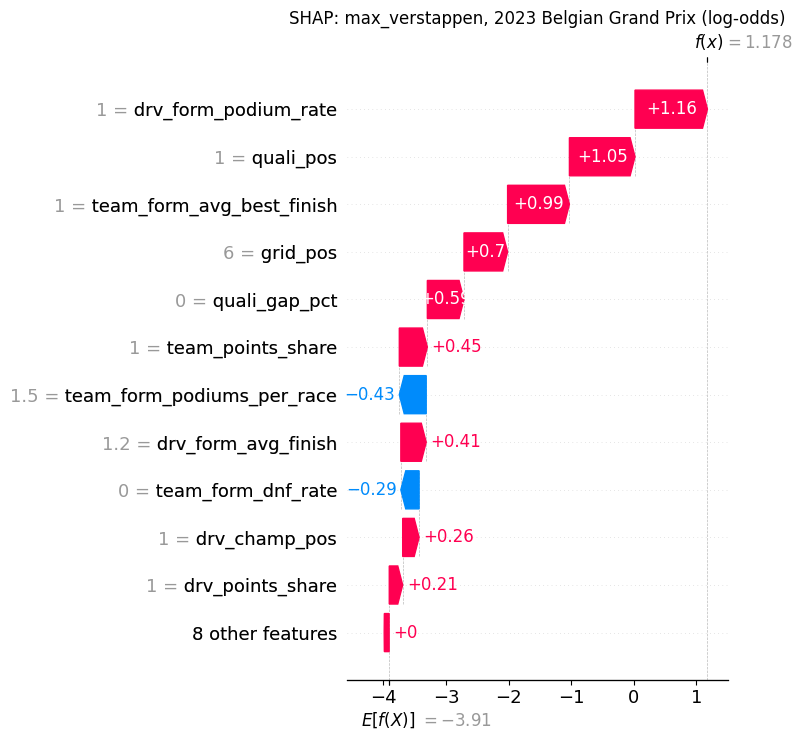

SHAP: average -3.91 + contributions +5.09 = 1.18 log-odds = podium chance 0.76

LIME: local straight-line model predicts 0.22 (the model says 0.76); fit R² 0.47
  is_rookie=0                                      -0.083
  pit_lane_start=0                                 +0.059
  grid_pos <= 6.00                                 +0.057
  team_form_avg_best_finish <= 4.60                +0.046
  quali_pos <= 6.00                                +0.045
  drv_form_podium_rate > 0.20                      +0.036
  quali_gap_pct <= 0.88                            +0.029
  team_points_share > 0.52                         +0.019
  drv_form_avg_finish <= 8.00                      +0.014
  team_form_podiums_per_race > 0.50                -0.012


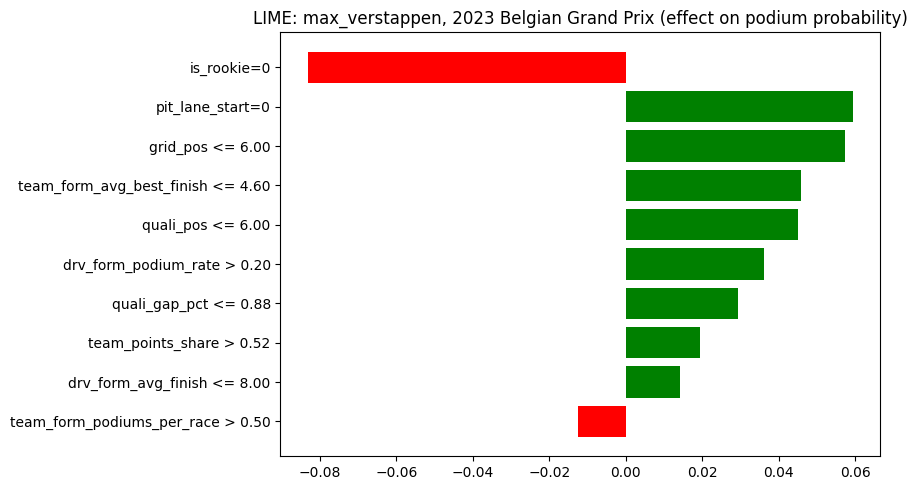

In [41]:
# 9.3 Local explanation of one prediction: SHAP waterfall and LIME for the same driver
p_test = proba(BEST_MODEL, X_test)
info = model_df.loc[X_test.index, ['year', 'race_name', 'driverRef', 'constructor_name', 'grid_pos', 'positionOrder', 'podium']]
info = info.assign(p=p_test)

# Rule fixed in advance: among drivers who started outside the top 3 and did finish on the podium,
# the one the model was most sure about. A non-obvious call, so the explanation must show more than the grid.
hits = info[(info['podium'] == 1) & (info['grid_pos'] >= 4) & (info['p'] >= THRESHOLDS[BEST_NAME])]
CASE = hits['p'].idxmax()
case = info.loc[CASE]
print(f"Explained prediction: {case['driverRef']} ({case['constructor_name']}), {int(case['year'])} {case['race_name']}: "
      f"started P{int(case['grid_pos'])}, predicted podium chance {case['p']:.2f} "
      f"(threshold {THRESHOLDS[BEST_NAME]:.2f}), finished P{int(case['positionOrder'])}")
print("Its feature values:")
print(model_df.loc[CASE, FEATURES].to_frame('value').T.round(3).to_string(index=False))

# SHAP waterfall: from the average output, each feature moves the prediction up or down
sv_case = shap_values(X_test.loc[[CASE]])[0]
case_expl = shap.Explanation(values=sv_case, base_values=BASE_VALUE,
                             data=model_df.loc[CASE, FEATURES].to_numpy(dtype=float), feature_names=FEATURES)
shap.plots.waterfall(case_expl, max_display=12, show=False)
plt.title(f"SHAP: {case['driverRef']}, {int(case['year'])} {case['race_name']} (log-odds)")
plt.tight_layout()
plt.show()
logit = BASE_VALUE + sv_case.sum()
print(f"SHAP: average {BASE_VALUE:.2f} + contributions {sv_case.sum():+.2f} = {logit:.2f} log-odds "
      f"= podium chance {1 / (1 + np.exp(-logit)):.2f}")

# LIME in real units: it changes the filled-in, unscaled values; the model sees them after the same preparation (6.5)
medians = TRAIN_STATS[0]
FLAGS = ['pit_lane_start', 'first_race_of_season', 'is_rookie', 'first_visit_circuit']


def model_on_raw(a):
    return BEST_MODEL.predict_proba(prepare(pd.DataFrame(a, columns=FEATURES), *TRAIN_STATS))


lime_explainer = LimeTabularExplainer(model_df.loc[X_train.index, FEATURES].fillna(medians).to_numpy(dtype=float),
                                      feature_names=FEATURES, class_names=['no podium', 'podium'],
                                      categorical_features=[FEATURES.index(f) for f in FLAGS],
                                      discretize_continuous=True, mode='classification', random_state=SEED)
case_raw = model_df.loc[CASE, FEATURES].astype(float).fillna(medians).to_numpy(dtype=float)
assert abs(model_on_raw(case_raw[None])[0, 1] - case['p']) < 1e-9   # same prediction as the prepared row
lime_exp = lime_explainer.explain_instance(case_raw, model_on_raw, num_features=10, num_samples=5000)
print(f"\nLIME: local straight-line model predicts {lime_exp.local_pred[0]:.2f} "
      f"(the model says {case['p']:.2f}); fit R² {lime_exp.score:.2f}")
for rule, weight in lime_exp.as_list():
    print(f"  {rule:48s} {weight:+.3f}")
fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(9, 5)
plt.title(f"LIME: {case['driverRef']}, {int(case['year'])} {case['race_name']} (effect on podium probability)")
plt.tight_layout()
plt.show()

**[OBSERVATION]:**
- **The driver:** Max Verstappen (Red Bull), 2023 Belgian Grand Prix. He set the fastest qualifying lap (qualifying position 1, gap 0.0%) but started 6th (a grid penalty), and he won. The model gave him a podium chance of 0.76, above its threshold of 0.17.
- **SHAP:** from the model's average output (−3.91 log-odds, the training average) the contributions add +5.09 and reach 1.18 log-odds, a chance of 0.76. The largest pushes (waterfall) are a podium in each of his last 10 races (driver-form podium rate 1.0, +1.16), qualifying position 1 (+1.05) and Red Bull's best car finishing first on average over its last 10 races (+0.99). Grid position 6 adds about +0.7 and the 0% qualifying gap about +0.6, then team points share 1.0 (+0.45) and his average finish of 1.2 (+0.41). Team podiums per race (−0.43) and the team's 0% retirement rate (−0.29) push down: the same overlap effect as the two surprising signs in 9.2 (on its own, a lower team retirement rate goes with more podiums, 6.4). So the model's confidence comes from his form, his qualifying pace and his team, and starting 6th still counts in his favour, because 6th is better than the average grid slot.
- **LIME is only a rough copy here.** Its local straight-line model predicts 0.22 where the model says 0.76, and fits the model's answers poorly (R² 0.47). Its largest weights go to the two flags (rookie = 0, −0.083; no pit-lane start, +0.059), because flipping a flag in the changed copies moves a linear model's output a lot. Its other conditions agree with SHAP: grid position ≤ 6 (+0.057), team best finish ≤ 4.60 (+0.046), qualifying position ≤ 6 (+0.045), driver podium rate > 0.20 (+0.036), qualifying gap ≤ 0.88% (+0.029) and team points share > 0.52 (+0.019).
- **Shared message:** qualifying pace, recent form and team strength. SHAP is exact for this model, so its numbers are the ones to quote; LIME's weights are read loosely.


### 9.4 Do the methods agree?

**[GOAL]:** Compare the three global views, group by group: the ablation (8.1), permutation importance (9.1) and SHAP (9.2).

**[LOGIC]:** Each method answers a slightly different question. The ablation asks what the model can still do *after retraining without* a group; permutation asks how much the *trained* model suffers when a group is scrambled; SHAP asks how much a group *moves* each prediction. If they rank the groups the same way, the conclusion does not depend on the method.

In [42]:
# 9.4 Do the methods agree? One row per feature group (larger = the model relies on the group more)
group_shap = pd.Series({g: np.abs(sv_val[:, [FEATURES.index(f) for f in cols]].sum(axis=1)).mean()
                        for g, cols in FEATURE_GROUPS.items()})
agree = pd.DataFrame({
    'ablation: PR-AUC lost without the group (8.1)': [ablation.loc[f'without {g}', 'val PR-AUC lost'] for g in FEATURE_GROUPS],
    'ablation: PR-AUC with the group alone (8.1)': [ablation.loc[f'only {g}', 'val PR-AUC'] for g in FEATURE_GROUPS],
    'permutation: PR-AUC lost, group shuffled (9.1)': [group_perm.loc[g, 'PR-AUC lost (mean)'] for g in FEATURE_GROUPS],
    'SHAP: mean |group contribution|, log-odds (9.2)': group_shap.to_numpy(),
}, index=list(FEATURE_GROUPS))
agree['SHAP rank'] = agree['SHAP: mean |group contribution|, log-odds (9.2)'].rank(ascending=False).astype(int)
agree['permutation rank'] = agree['permutation: PR-AUC lost, group shuffled (9.1)'].rank(ascending=False).astype(int)
with pd.option_context('display.width', 250, 'display.max_columns', 20):
    print(agree.sort_values('SHAP rank').round(3).to_string())

             ablation: PR-AUC lost without the group (8.1)  ablation: PR-AUC with the group alone (8.1)  permutation: PR-AUC lost, group shuffled (9.1)  SHAP: mean |group contribution|, log-odds (9.2)  SHAP rank  permutation rank
qualifying                                           0.011                                        0.666                                           0.100                                            0.786          1                 1
grid                                                 0.007                                        0.639                                           0.093                                            0.734          2                 2
standings                                            0.001                                        0.635                                           0.039                                            0.421          3                 4
driver form                                         -0.009                      

**[OBSERVATION]:**
- **The methods agree on the top two groups.** Qualifying and grid rank first and second in SHAP (0.786 and 0.734), in permutation (0.100 and 0.093) and when a group is dropped (0.011 and 0.007). Used alone, qualifying is again first (0.666), and grid (0.639), driver form (0.640) and standings (0.635) are within 0.005 of each other.
- **Standings and driver form swap third and fourth:** SHAP ranks standings third (0.421) and driver form fourth (0.355); permutation the other way round (0.052 for driver form, 0.039 for standings). Team form and the extras are last in SHAP, in permutation and when used alone. When one group is dropped the order differs (driver form is lowest, −0.009), but there every single-group change is within noise (8.1).
- **Where they differ, it is because of overlap.** Dropping qualifying and retraining costs only 0.011 (8.1), but scrambling it in the trained model costs 0.100 (9.1). The information is important; whether grid or qualifying carries it is interchangeable.
- **Conclusion:** the model is built on the starting position, then the driver's recent form and the standings. Team form and the extras add little on top.


### 9.5 What the explanations show, and what they do not

- **Importance is not causation.** Everything in 8.1–9.4 describes what this model *relies on* to predict, not what *causes* a podium. A good team best finish matters because a fast car shows up in it; a better finish last week does not make this week's car faster. Qualifying position does not cause a good race result either: both come from the same fast car and driver.
- **Overlapping features share the credit.** Grid and qualifying position (0.97), and championship position and points share (−0.95), carry almost the same information, and the three team features overlap too. In a linear model the split between partners can even flip a sign (team podiums per race, the rookie flag, 9.2), so partners are read together, as "starting position", "standings" and "team strength".
- **Small importance means "this model barely uses it", not "useless".** Career starts and circuit podium rate barely move any prediction (9.2), and dropping the extras does not lower the score (8.1), yet circuit podium rate scores 0.705 on its own (6.4): its information is already in the other features.
- **The explanations describe 2020–2021.** The global explanations come from the 39 validation races. In the new car era of the test seasons (2022–2024) the model's reliance may shift (7.6).
- **LIME is an approximation.** Its local straight-line model matched the model poorly for the explained driver (R² 0.47), so its exact weights are read loosely. SHAP for a linear model is exact.


## Section 10: Inference Function (deliverable 7)

**[GOAL]:** Score a race that has not been run yet: for every starter, the chance of a podium and a yes/no prediction, using only what is known after qualifying and before the start. Show it on a complete record and on partially-missing records.

**[LOGIC]:**
- **Two small functions.**
  - `pre_race_rows` turns a race into its pre-race state, following the recipe in 6.7: the race's starters with their results erased, plus every earlier race as history.
  - `predict_podium` is the inference function itself. It takes one row per driver with the raw values of the 19 features, prepares them exactly as in 6.5 (training medians and training mean/spread, `TRAIN_STATS`), scores them with the selected model (`BEST_MODEL`, 7.6) and applies its validation-chosen threshold (`THRESHOLDS[BEST_NAME]`).
- **Missing values.** A blank value, or a feature that is not given at all, is filled with its training median, the same rule the models were trained with. So a partially-missing record still gets a prediction. The function also prints the names of any feature it was not given, so a misspelt column name is noticed instead of being filled without a word.
- **Demonstration race:** the last race in the data (a test-season race), treated as if it had not been run. The check below confirms that its features, rebuilt from pre-race information only, equal the ones the models were scored on, so the function adds no leakage.
- **Three records:**
  - complete: the pole sitter, all 19 values known;
  - partially missing, naturally: the starter with the most blank features (a driver's first race has no form and no circuit history);
  - partially missing, by hand: the pole sitter again, with the two qualifying values removed, as if qualifying had not been recorded.
- **For a truly new race,** first add it to `dfs_clean['races']`, its entries to `starts` (each with its `constructorId`) and its qualifying (if known) to `dfs_clean['qualifying']`, as listed in 6.7; then the same two functions apply.


In [43]:
# 10. Inference function: podium chance for every starter, from what is known before the start
def pre_race_rows(race_id):
    """The race's starters as they look before the start, plus every earlier race as history.
    The race's own results are erased, so nothing from the race can reach its features."""
    race = starts[starts['raceId'] == race_id].copy()
    race[['positionOrder', 'podium', 'dnf', 'status_description']] = np.nan
    history = starts[starts['date'] < race['date'].iloc[0]]
    return pd.concat([history, race])


def predict_podium(records):
    """Inference function. records: one row per driver and race with the raw values of the 19 features (as in
    model_df). A blank value, or a feature that is missing altogether, is filled with the training median;
    the features that were not given at all are printed."""
    not_given = [f for f in FEATURES if f not in records.columns]
    if not_given:
        print(f"Not given (filled with the training median): {', '.join(not_given)}")
    unknown = [c for c in records.columns if c not in FEATURES]
    if unknown:
        print(f"Ignored (not one of the 19 features): {', '.join(unknown)}")
    X_new = prepare(records.reindex(columns=FEATURES).astype(float), *TRAIN_STATS)
    chance = proba(BEST_MODEL, X_new)
    return pd.DataFrame({'podium chance': chance, 'podium predicted': chance >= THRESHOLDS[BEST_NAME]},
                        index=records.index)


# Demonstration: the last race in the data, treated as if it had not been run yet
RACE = starts.loc[starts['date'].idxmax(), 'raceId']
race = build_table(pre_race_rows(RACE))
race = race[race['raceId'] == RACE].set_index('driverRef')
print(f"Race: {race['year'].iloc[0]} {race['race_name'].iloc[0]}, {len(race)} starters, results erased")
print(f"Model: {BEST_NAME}, podium predicted when the chance is at least {THRESHOLDS[BEST_NAME]:.3f}")

# Check: rebuilt from pre-race information only, the features equal the ones the models were scored on
scored = model_df[model_df['raceId'] == RACE].set_index('driverRef')[FEATURES]
pd.testing.assert_frame_equal(race.loc[scored.index, FEATURES], scored, check_dtype=False)
print("Check passed: the 19 features rebuilt without the race's results equal those in model_df\n")

pole = race['quali_pos'].idxmin()                          # the pole sitter
most_blanks = race[FEATURES].isna().sum(axis=1).idxmax()   # the starter with the most blank features
records = {f'complete: {pole}': race.loc[[pole], FEATURES],
           f'partially missing: {most_blanks}': race.loc[[most_blanks], FEATURES],
           f'partially missing: {pole}, no qualifying': race.loc[[pole], FEATURES].drop(columns=['quali_pos', 'quali_gap_pct'])}

print("The three records (raw values; blank = missing, filled with the training median):")
values = pd.DataFrame({label: rec.reindex(columns=FEATURES).iloc[0] for label, rec in records.items()})
values['training median'] = TRAIN_STATS[0]
print(values.round(3).to_string(na_rep='blank'))

rows = []
for label, rec in records.items():
    out = predict_podium(rec)
    rows.append({'record': label, 'blank values': int(rec.reindex(columns=FEATURES).isna().sum().sum()),
                 'podium chance': round(out['podium chance'].iloc[0], 3), 'podium predicted': out['podium predicted'].iloc[0]})
print("\nPredictions:")
print(pd.DataFrame(rows).to_string(index=False))

# The whole field, ranked by podium chance; the actual finish is shown only afterwards, it is never used above
actual = starts[starts['raceId'] == RACE].set_index('driverRef')['positionOrder'].rename('actual finish')
field = predict_podium(race[FEATURES]).join(race[['grid_pos', 'quali_pos']]).join(actual)
print("\nWhole field:")
print(field.sort_values('podium chance', ascending=False).round(3).to_string())


Race: 2024 Abu Dhabi Grand Prix, 20 starters, results erased
Model: Baseline: Logistic Regression, podium predicted when the chance is at least 0.171
Check passed: the 19 features rebuilt without the race's results equal those in model_df

The three records (raw values; blank = missing, filled with the training median):
                            complete: norris  partially missing: doohan  partially missing: norris, no qualifying  training median
grid_pos                               1.000                     17.000                                     1.000           11.000
pit_lane_start                         0.000                      0.000                                     0.000            0.000
quali_pos                              1.000                     20.000                                     blank           11.000
quali_gap_pct                          0.000                      1.828                                     blank            1.809
drv_points_share       

**[OBSERVATION]:**
- **Check passed:** the 2024 Abu Dhabi Grand Prix, rebuilt with its results erased, gives exactly the same 19 features as the table the models were scored on. The inference function sees nothing from the race itself, and it prepares a record the same way as in training.
- **Complete record:** Norris, on pole, with all 19 values known, gets a podium chance of 0.691, above the threshold 0.171, so a podium is predicted. Norris won the race.
- **Partially-missing record (natural):** Doohan, in a first Formula 1 race, has 4 blank values: the three driver-form values and the circuit podium rate. His standings are not blank: with no standing yet, the 6.3 rule already gives him points share 0 and championship position 23. The blanks are filled with the training medians (podium rate 0, average finish 11.4, retirement rate 0.2, circuit podium rate 0). Starting 17th, qualified 20th, with no points and a team sixth in the standings, the chance is 0.005: no podium (finished 15th).
- **Partially-missing record (by hand):** the same Norris record without its two qualifying values; the function prints that these two were not given. They are filled with the medians (position 11, gap 1.809%), so the chance falls from 0.691 to 0.330. It is still above the threshold, because pole on the grid and the standings are known. A missing value is replaced by a typical value: it is treated as neither good nor bad.
- **The whole field:** five drivers are above the threshold (Norris 0.691, Piastri 0.631, Verstappen 0.549, Sainz 0.527, Russell 0.227). The threshold is low (chosen for the best F1 on validation), and the yes/no rule is per driver, so it can name more than three per race. The real podium was Norris, Sainz and Leclerc. Two of the five predictions were right, and Leclerc, who started 19th, had a chance of only 0.065: a recovery from the back is what a pre-race model cannot foresee.


## Summary of results

- **Data (Sections 1–4):** 160,076 `\N` placeholders became real missing values, the 85 duplicated driver–race groups were resolved (the driver's best-classified row is kept), and all 14 primary keys and 23 foreign-key links are clean. Suspect fastest-lap records are labelled, not changed (3.1). One joined table has 26,668 driver–race rows.
- **Q1 (Section 5):** front-row starters reach the podium 60.4% of the time. Conversion rose from 56.4% (1950–2013) to 76.0% (2014–2024), while the share of front-row starters who did not finish fell from 29.8% to 8.4%.
- **Q2:** no home advantage once the grid slot is controlled for: pooled odds ratio 0.97 (95% CI 0.81–1.15, p = 0.71).
- **Q3:** mechanical retirements fell from 9.39% to 6.13% of starts (p = 0.00028). The highest rates were Caterham in 2014–2021 and Alpine in 2022–2024; only McLaren's drop survives the correction for testing many teams.
- **Modelling table (Section 6):** 8,939 driver–race rows (2003–2024), split by whole seasons into 6,804 / 780 / 1,355 rows (2003–2019 / 2020–2021 / 2022–2024), with 19 features that use only information from before the start. Team history follows `constructorId`, so a renamed team (or an id back after more than a season) starts over.
- **Models (Section 7):** no model clearly beats the logistic-regression baseline on validation (the random forest leads by 0.014, 95% interval −0.026 to +0.059), so the baseline is the selected model. On the test seasons it scores PR-AUC 0.700, against 0.702 for the forest, again within noise. The features clearly beat the grid position alone.
- **What the model uses (Sections 8–9):** the starting position (grid or qualifying, which stand in for each other), then recent driver form and the standings. Removing grid and qualifying together costs 0.080 validation PR-AUC. This shows what the model relies on, not what causes a podium.
- **Inference (Section 10):** scores any race from pre-race information. On the 2024 Abu Dhabi GP, a complete record (Norris) gets 0.691 and a record with 4 blank values (Doohan) 0.005.
- **Main limits (6.8, 7.5, 9.5):** the test seasons are a new car era (every trained model drops from validation to test), validation has only 39 races, and weather, tyres and practice pace are not in the data.
